# Bài thực hành dữ liệu đặt phòng khách sạn — Notebook khung

**Phiên bản 2.0 · Dành cho sinh viên · Chưa có lời giải**

| Thông tin nhóm | Điền vào đây |
|---|---|
| Mã nhóm | NhomXX |
| Thành viên 1 (MSSV) — phần phụ trách | … |
| Thành viên 2 (MSSV) — phần phụ trách | … |
| Thành viên 3 (MSSV) — phần phụ trách | … |
| Ngày chạy lại toàn bộ lần cuối | … |

**Trước khi nộp:** đổi tên tệp thành `hotel_analysis.ipynb`.

## Cách dùng notebook này

Notebook đi theo đúng 5 giai đoạn của đề bài: **A Khảo sát → B Làm sạch → C Bảng sạch & kiểm tra → D Phân tích 10 câu → E Xuất & nộp**.

| Ký hiệu | Ý nghĩa | Bạn cần làm gì |
|---|---|---|
| 📋 Thẻ nhiệm vụ | Bảng đầu mỗi mục: mục tiêu, đầu vào/ra, các bước, bẫy | Đọc trước khi viết mã |
| `# TODO` | Chỗ nhóm phải viết mã | Thay bằng mã của nhóm; xóa chữ TODO khi xong |
| `= None` | Biến đầu ra nhóm phải tạo | Gán DataFrame thật, **giữ đúng tên biến** |
| ✅ / ❌ | Kết quả ô tự kiểm tra | ❌ nghĩa là chưa xong hoặc chưa đúng quy ước — đọc gợi ý in kèm |
| ✍️ | Ô văn bản nhóm phải viết | Viết bằng số liệu thật, có mẫu số |

**Ba quy tắc vàng**

1. **Không sửa tay** `hotel_bookings_dirty.csv`, không thay bằng bộ dữ liệu gốc sạch.
2. **Không xóa các ô kiểm tra** (✅/❌). Chúng giúp bạn và giảng viên thấy tiến độ.
3. Cuối mỗi buổi: **Runtime/Kernel → Restart & Run all**. Notebook phải chạy được từ đầu đến cuối.

Notebook vẫn chạy hết khi còn dang dở: các ô kiểm tra chỉ in ❌, không làm dừng chương trình.

## 0 · Thiết lập

**Colab:** File → Upload notebook; mở bảng 📁 Files, tải `hotel_bookings_dirty.csv` lên. Có thể tải thêm `kiem_tra_nop_bai.py` để tự kiểm tra ở cuối.
**Máy cá nhân:** giữ cấu trúc thư mục của gói bài tập (notebook ở thư mục gốc, dữ liệu trong `data/`).

Ô 0.1 chứa công cụ hỗ trợ dùng chung. **Không cần sửa**, chỉ cần chạy.

In [50]:
# 0.1 CÔNG CỤ HỖ TRỢ — KHÔNG CẦN SỬA
from pathlib import Path
import numpy as np
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 40)

# ---- Đường dẫn: tự tìm dữ liệu ở data/ hoặc cùng thư mục notebook (Colab) ----
CANDIDATES = [Path('data/hotel_bookings_dirty.csv'), Path('hotel_bookings_dirty.csv')]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUTPUT_DIR = Path('outputs')
for sub in ['', 'figures', 'tables']:
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)

# ---- Quy ước của đề (Mục 5) ----
SNAPSHOT_DATE = pd.Timestamp('2017-09-14')
MISSING_TOKENS = ['NULL', 'N/A', 'NA', '?', 'unknown', '-']        # so sánh không phân biệt hoa thường
HOTEL_COLORS = {'City Hotel': '#2F4858', 'Resort Hotel': '#E07A1F'}  # dùng cho MỌI hình có hotel
STATUS_COLORS = {'Check-Out': '#5B8E7D', 'Canceled': '#B81D24', 'No-Show': '#F2A541'}
FIGSIZE = (9, 5)

# ===================== BỘ KIỂM TRA ĐẦU RA (dùng chung notebook + tools) =====================
# Bộ kiểm tra chỉ xác nhận CẤU TRÚC, KHÓA, MIỀN GIÁ TRỊ và TÍNH NHẤT QUÁN theo quy ước trong đề.
# Nó KHÔNG chứa đáp án và KHÔNG chứng minh kết quả phân tích của nhóm là đúng.
import pandas as pd

HOTELS = ['City Hotel', 'Resort Hotel']
MEALS = ['BB', 'HB', 'FB', 'SC']
SEGMENTS = ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate', 'Complementary', 'Aviation']
CHANNELS = ['TA/TO', 'Direct', 'Corporate', 'GDS']
DEPOSITS = ['No Deposit', 'Non Refund', 'Refundable']
CUSTOMERS = ['Transient', 'Transient-Party', 'Contract', 'Group']
STATUSES = ['Check-Out', 'Canceled', 'No-Show']
ROOM_TYPES = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'P']
LEAD_GROUPS = ['0-7', '8-30', '31-90', '91-180', '181+']

ARRIVAL_MIN, ARRIVAL_MAX = pd.Timestamp('2015-07-01'), pd.Timestamp('2017-08-31')
STATUS_MIN, STATUS_MAX = pd.Timestamp('2014-10-01'), pd.Timestamp('2017-09-14')
LEAD_MIN, LEAD_MAX = 0, 800
WEEKEND_MAX, WEEK_MAX = 20, 50
GUEST_MAX = 10
ADR_MIN, ADR_MAX = 0, 1000
REQ_MAX = 5
N_RAW_ROWS = 10325

CLEAN_REQUIRED = ['booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date', 'stays_in_weekend_nights',
                  'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment',
                  'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'assigned_room_type',
                  'deposit_type', 'customer_type', 'adr', 'total_of_special_requests', 'reservation_status',
                  'reservation_status_date',
                  'arrival_year', 'arrival_month', 'total_nights', 'total_guests', 'lead_time_group',
                  'room_changed_flag', 'revenue_est']
SUMMARY_COLUMNS = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled',
                   'cancel_rate_pct', 'room_nights']
LOG_COLUMNS = ['step', 'field', 'issue', 'detection_rule', 'action', 'affected_rows',
               'changed_cells', 'removed_rows', 'example_row_ids', 'reason', 'check_after']
LINEAGE_COLUMNS = ['row_id', 'booking_id', 'status']
LINEAGE_STATUS = ['kept', 'merged', 'dropped']
QUALITY_COLUMNS = ['column', 'stage', 'denominator_rows', 'missing_count', 'invalid_count', 'missing_pct']

CORE_FILES = ['bookings_clean.csv', 'monthly_summary.csv', 'cleaning_log.csv', 'row_lineage.csv',
              'quality_report.csv']
FIGURE_FILES = ['fig01_hotel_cancel.png', 'fig02_monthly_arrivals_2016.png', 'fig03_leadtime_cancel.png',
                'fig04_top10_country.png', 'fig05_segment_cancel.png', 'fig06_deposit_cancel.png',
                'fig07_adr_hist.png', 'fig08_stay_nights.png']
TABLE_FILES = ['a_missing_survey.csv', 'a_issue_catalog.csv', 'q01_before_after.csv',
               'q02_hotel_cancel.csv', 'q03_monthly_arrivals_2016.csv', 'q04_leadtime_stats.csv',
               'q04_leadtime_cancel.csv', 'q05_top10_country.csv', 'q06_segment_cancel.csv',
               'q07_deposit_cancel.csv', 'q08_adr_stats_by_hotel.csv', 'q09_stay_nights.csv',
               'q10_room_change_by_hotel.csv', 'q10_room_change_by_reserved_type.csv']


def _blank(s):
    """True khi ô thiếu: NaN/None/NA hoặc chuỗi rỗng sau khi bỏ khoảng trắng."""
    return s.isna() | s.astype('string').str.strip().fillna('').eq('')


def _num(s):
    return pd.to_numeric(s.where(~_blank(s)), errors='coerce')


def _int_ok(s, lo, hi):
    """Ô có dữ liệu phải là số nguyên trong [lo, hi]. Trả về (đạt?, số ô sai)."""
    present = ~_blank(s)
    v = _num(s)
    bad = present & (v.isna() | (v % 1 != 0) | (v < lo) | (v > hi))
    return int(bad.sum()) == 0, int(bad.sum())


def _bool(s):
    m = {'true': True, 'false': False, '1': True, '0': False, '1.0': True, '0.0': False}
    return s.astype('string').str.strip().str.lower().map(m)


def _date(s):
    txt = s.astype('string').str.strip()
    return pd.to_datetime(txt.where(~_blank(s)), format='%Y-%m-%d', errors='coerce')


def _cat_ok(s, allowed, allow_missing=True):
    present = ~_blank(s)
    bad = sorted(set(s[present].astype(str)) - set(allowed))
    miss = int((~present).sum())
    ok = not bad and (allow_missing or miss == 0)
    return ok, ('Nhãn lạ: ' + ', '.join(bad[:6]) if bad else '') + ('' if allow_missing or miss == 0 else f' {miss} ô thiếu')


def validate_outputs(clean, monthly, row_lineage, cleaning_log, quality_report, raw_row_ids=None):
    """Chạy toàn bộ kiểm tra. Trả về DataFrame: nhom, kiem_tra, ket_qua, chi_tiet."""
    res = []

    def add(group, name, ok, detail=''):
        res.append({'nhom': group, 'kiem_tra': name,
                    'ket_qua': 'ĐẠT' if ok else 'CHƯA ĐẠT', 'chi_tiet': detail})

    def safe(group, name, fn):
        try:
            ok, detail = fn()
        except Exception as e:  # thiếu cột, sai kiểu... -> báo lỗi thân thiện
            ok, detail = False, f'Lỗi khi kiểm tra: {type(e).__name__}: {e}'
        add(group, name, ok, detail)

    frames = {'bookings_clean': clean, 'monthly_summary': monthly, 'row_lineage': row_lineage,
              'cleaning_log': cleaning_log, 'quality_report': quality_report}
    for k, v in frames.items():
        add('0 Tồn tại', f'{k} đã được tạo', v is not None and len(v) > 0,
            '' if v is not None else 'Biến/tệp còn trống (None).')

    # ---------------- Bảng chính: khóa và nhãn ----------------
    if clean is not None:
        c = clean
        G = '1 Khóa & nhãn'
        safe(G, 'Đủ các cột bắt buộc',
             lambda: (not (miss := [x for x in CLEAN_REQUIRED if x not in c.columns]),
                      'Thiếu: ' + ', '.join(miss) if miss else f'{len(c.columns)} cột'))
        safe(G, 'booking_id không thiếu, dạng BK + 6 chữ số',
             lambda: ((n := int((_blank(c['booking_id']) | ~c['booking_id'].astype('string').str.fullmatch(r'BK\d{6}').fillna(False)).sum())) == 0,
                      f'{n} ô thiếu hoặc sai dạng'))
        safe(G, 'booking_id không trùng (1 dòng / đặt phòng)',
             lambda: ((n := int(c['booking_id'].duplicated().sum())) == 0, f'{n} booking_id lặp'))
        safe(G, 'hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)', lambda: _cat_ok(c['hotel'], HOTELS, False))
        for col, allowed in [('meal', MEALS), ('market_segment', SEGMENTS), ('distribution_channel', CHANNELS),
                             ('deposit_type', DEPOSITS), ('customer_type', CUSTOMERS), ('reservation_status', STATUSES),
                             ('reserved_room_type', ROOM_TYPES), ('assigned_room_type', ROOM_TYPES)]:
            safe(G, f'{col} thuộc tập nhãn hợp lệ hoặc thiếu', lambda col=col, allowed=allowed: _cat_ok(c[col], allowed))
        safe(G, 'country là mã 2–3 chữ in hoa hoặc thiếu',
             lambda: ((n := int((~_blank(c['country']) & ~c['country'].astype('string').str.fullmatch(r'[A-Z]{2,3}').fillna(False)).sum())) == 0,
                      f'{n} ô sai dạng'))
        safe(G, 'is_canceled, is_repeated_guest chỉ là 0/1 hoặc thiếu',
             lambda: ((a := _int_ok(c['is_canceled'], 0, 1))[0] and (b := _int_ok(c['is_repeated_guest'], 0, 1))[0],
                      f'is_canceled sai: {a[1]}; is_repeated_guest sai: {b[1]}'))

        # ---------------- Số đo và ngày ----------------
        G = '2 Số & ngày'
        for col, lo, hi in [('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX),
                            ('stays_in_week_nights', 0, WEEK_MAX), ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX),
                            ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]:
            safe(G, f'{col} nguyên trong {lo}–{hi}', lambda col=col, lo=lo, hi=hi: ((r := _int_ok(c[col], lo, hi))[0], f'{r[1]} ô sai'))

        def _adr():
            present = ~_blank(c['adr'])
            v = _num(c['adr'])
            bad = present & (v.isna() | (v < ADR_MIN) | (v > ADR_MAX))
            return int(bad.sum()) == 0, f'{int(bad.sum())} ô không phải số trong 0–1000'
        safe(G, 'adr là số (EUR) trong 0–1000 hoặc thiếu', _adr)

        def _dates(col, lo, hi):
            s = c[col]
            present = ~_blank(s)
            fmt_bad = present & ~s.astype('string').str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}').fillna(False)
            d = _date(s)
            rng_bad = present & (d.isna() | (d < lo) | (d > hi))
            n = int((fmt_bad | rng_bad).sum())
            return n == 0, f'{n} ô sai định dạng YYYY-MM-DD hoặc ngoài {lo:%Y-%m-%d}..{hi:%Y-%m-%d}'
        safe(G, 'arrival_date dạng YYYY-MM-DD, trong 2015-07-01..2017-08-31',
             lambda: _dates('arrival_date', ARRIVAL_MIN, ARRIVAL_MAX))
        safe(G, 'reservation_status_date dạng YYYY-MM-DD, trong 2014-10-01..2017-09-14',
             lambda: _dates('reservation_status_date', STATUS_MIN, STATUS_MAX))

        def _cons():
            st = c['reservation_status'].astype('string')
            ic = _num(c['is_canceled'])
            exp = st.map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1})
            bad = exp.notna() & (ic.astype('Float64') != exp.astype('Float64')).fillna(True)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng is_canceled mâu thuẫn reservation_status'
        safe(G, 'is_canceled nhất quán với reservation_status', _cons)

        # ---------------- Cột dẫn xuất ----------------
        G = '3 Cột dẫn xuất'

        def _ym():
            d = _date(c['arrival_date'])
            bad = (d.dt.year.astype('Float64').fillna(-1) != _num(c['arrival_year']).fillna(-1)) | \
                  (d.dt.month.astype('Float64').fillna(-1) != _num(c['arrival_month']).fillna(-1))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng không khớp arrival_date'
        safe(G, 'arrival_year, arrival_month lấy từ arrival_date', _ym)

        def _sum(target, parts):
            exp = sum(_num(c[p]) for p in parts)
            bad = exp.fillna(-999) != _num(c[target]).fillna(-999)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (thiếu một thành phần → kết quả thiếu)'
        safe(G, 'total_nights = weekend + week nights', lambda: _sum('total_nights', ['stays_in_weekend_nights', 'stays_in_week_nights']))
        safe(G, 'total_guests = adults + children + babies', lambda: _sum('total_guests', ['adults', 'children', 'babies']))

        def _lead():
            lt = _num(c['lead_time'])
            exp = pd.cut(lt, bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')], labels=LEAD_GROUPS).astype('string')
            got = c['lead_time_group'].astype('string').where(~_blank(c['lead_time_group']))
            bad = exp.fillna('∅') != got.fillna('∅')
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai nhóm (nhãn: {", ".join(LEAD_GROUPS)})'
        safe(G, 'lead_time_group đúng 5 nhóm quy ước', _lead)

        def _room():
            r, a = c['reserved_room_type'], c['assigned_room_type']
            exp = (~_blank(r) & ~_blank(a) & (r.astype('string') != a.astype('string'))).fillna(False)
            got = _bool(c['room_changed_flag'])
            bad = got.isna() | (got.astype('boolean') != exp.astype('boolean'))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai hoặc thiếu cờ (chỉ dùng True/False)'
        safe(G, 'room_changed_flag đúng quy tắc', _room)

        def _rev():
            adr, n, ic = _num(c['adr']), _num(c['total_nights']), _num(c['is_canceled'])
            exp = (adr * n).where(ic == 0).round(2)
            got = _num(c['revenue_est']).round(2)
            same = (exp.isna() & got.isna()) | ((exp - got).abs() <= 0.011).fillna(False)
            bad = ~same
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (chỉ tính khi is_canceled = 0 và adr, total_nights hợp lệ)'
        safe(G, 'revenue_est = adr × total_nights (chỉ đặt phòng không hủy)', _rev)

    # ---------------- Bảng tổng hợp theo tháng ----------------
    if monthly is not None:
        m = monthly
        G = '4 Bảng tháng'
        safe(G, 'monthly_summary đúng 7 cột',
             lambda: (list(m.columns) == SUMMARY_COLUMNS, f'Cột hiện có: {list(m.columns)}'))
        safe(G, 'Không trùng khóa (hotel, arrival_year, arrival_month)',
             lambda: ((n := int(m.duplicated(['hotel', 'arrival_year', 'arrival_month']).sum())) == 0, f'{n} khóa lặp'))
        if clean is not None:
            def _recompute():
                c = clean.copy()
                c['_y'], c['_m'] = _num(c['arrival_year']), _num(c['arrival_month'])
                c['_ic'], c['_n'] = _num(c['is_canceled']), _num(c['total_nights'])
                c = c[c['_y'].notna()]
                g = c.groupby([c['hotel'].astype(str), '_y', '_m'])
                exp = pd.DataFrame({'n_bookings': g.size(), 'n_canceled': g['_ic'].apply(lambda s: (s == 1).sum()),
                                    'known': g['_ic'].apply(lambda s: s.notna().sum()),
                                    'room_nights': g.apply(lambda x: x.loc[x['_ic'] == 0, '_n'].sum())}).reset_index()
                exp.columns = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'known', 'room_nights']
                exp['cancel_rate_pct'] = (exp['n_canceled'] / exp['known'] * 100).round(2)
                got = m.copy()
                for col in ['arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'cancel_rate_pct', 'room_nights']:
                    got[col] = _num(got[col])
                got['hotel'] = got['hotel'].astype(str)
                j = exp.merge(got, on=['hotel', 'arrival_year', 'arrival_month'], how='outer', suffixes=('_e', '_g'), indicator=True)
                miss = int((j['_merge'] != 'both').sum())
                b = j[j['_merge'] == 'both']
                bad = int(((b['n_bookings_e'] != b['n_bookings_g']) | (b['n_canceled_e'] != b['n_canceled_g']) |
                           ~(((b['cancel_rate_pct_e'] - b['cancel_rate_pct_g']).abs() <= 0.011) |
                             (b['cancel_rate_pct_e'].isna() & b['cancel_rate_pct_g'].isna())) |
                           ((b['room_nights_e'] - b['room_nights_g']).abs() > 0.5)).sum())
                return miss == 0 and bad == 0, f'{miss} tháng thiếu/thừa; {bad} tháng lệch số liệu so với bảng chính'
            safe(G, 'Số liệu khớp khi tính lại từ bookings_clean', _recompute)

    # ---------------- Truy vết ----------------
    if row_lineage is not None:
        rl = row_lineage
        G = '5 Truy vết'
        safe(G, 'row_lineage có cột row_id, booking_id, status',
             lambda: (all(x in rl.columns for x in LINEAGE_COLUMNS), f'Cột hiện có: {list(rl.columns)}'))
        safe(G, 'Mỗi row_id xuất hiện đúng 1 lần',
             lambda: ((n := int(rl['row_id'].duplicated().sum())) == 0, f'{n} row_id lặp'))
        if raw_row_ids is not None:
            safe(G, f'Phủ đủ {N_RAW_ROWS} row_id gốc',
                 lambda: ((mm := len(set(raw_row_ids) - set(rl['row_id']))) == 0 and
                          (x := len(set(rl['row_id']) - set(raw_row_ids))) == 0,
                          f'Thiếu {mm} row_id gốc; thừa {x} row_id lạ'))
        safe(G, 'status thuộc kept / merged / dropped',
             lambda: (not (bad := sorted(set(rl['status'].astype(str)) - set(LINEAGE_STATUS))),
                      'Giá trị lạ: ' + ', '.join(bad[:5]) if bad else ''))
        if clean is not None:
            safe(G, 'Mỗi booking_id trong bảng chính có đúng 1 dòng kept',
                 lambda: ((k := rl.loc[rl['status'] == 'kept', 'booking_id']).is_unique and
                          set(k) == set(clean['booking_id']),
                          f'{int(k.duplicated().sum())} booking_id có >1 kept; '
                          f'{len(set(clean["booking_id"]) - set(k))} booking_id không có kept'))
            safe(G, 'Dòng kept/merged trỏ tới booking_id có trong bảng chính',
                 lambda: ((n := int((rl['status'].isin(['kept', 'merged']) &
                                     ~rl['booking_id'].isin(clean['booking_id'])).sum())) == 0, f'{n} dòng trỏ sai'))

    # ---------------- Nhật ký & chất lượng ----------------
    G = '6 Nhật ký'
    if cleaning_log is not None:
        lg = cleaning_log
        safe(G, 'cleaning_log đúng 11 cột theo mẫu',
             lambda: (list(lg.columns) == LOG_COLUMNS, f'Cột hiện có: {list(lg.columns)}'))
        safe(G, 'Có ít nhất 10 quy tắc được ghi', lambda: (len(lg) >= 10, f'{len(lg)} dòng'))
        safe(G, 'affected_rows, changed_cells, removed_rows là số nguyên ≥ 0',
             lambda: (all(_int_ok(lg[x], 0, 10**7)[0] and (~_blank(lg[x])).all()
                          for x in ['affected_rows', 'changed_cells', 'removed_rows']), ''))
        safe(G, 'Mỗi quy tắc có lý do (reason) và kiểm tra sau (check_after)',
             lambda: ((n := int((_blank(lg['reason']) | _blank(lg['check_after'])).sum())) == 0, f'{n} dòng thiếu'))
    if quality_report is not None:
        q = quality_report
        safe(G, 'quality_report có các cột bắt buộc',
             lambda: (not (mm := [x for x in QUALITY_COLUMNS if x not in q.columns]), 'Thiếu: ' + ', '.join(mm) if mm else ''))
        safe(G, 'quality_report có cả before và after',
             lambda: ({'before', 'after'} <= set(q['stage'].astype(str)), f'stage: {sorted(set(q["stage"].astype(str)))}'))

    return pd.DataFrame(res)


def print_report(report):
    n_ok = int((report['ket_qua'] == 'ĐẠT').sum())
    for _, r in report.iterrows():
        mark = '✅' if r['ket_qua'] == 'ĐẠT' else '❌'
        extra = f'  — {r["chi_tiet"]}' if r['chi_tiet'] and r['ket_qua'] != 'ĐẠT' else ''
        print(f'{mark} [{r["nhom"]}] {r["kiem_tra"]}{extra}')
    print(f'\nTỔNG KẾT: {n_ok}/{len(report)} kiểm tra đạt.')
    return n_ok == len(report)
# =============================================================================================


# ---- Hàm tiện ích ----
cleaning_log_rows = []   # mỗi phần tử là 1 dict = 1 dòng nhật ký

def example_ids(frame, mask, k=5):
    """Trả về tối đa k row_id (ngăn bằng '; ') của các dòng thỏa mask — dùng cho cột example_row_ids."""
    return '; '.join(frame.loc[mask, 'row_id'].astype(str).head(k))

def log_step(step, field, issue, detection_rule, action, affected_rows, changed_cells,
             removed_rows, example_row_ids, reason, check_after):
    """Thêm 1 dòng vào nhật ký làm sạch. Gọi lại với cùng step+field+issue sẽ GHI ĐÈ dòng cũ (an toàn khi chạy lại ô)."""
    row = dict(step=step, field=field, issue=issue, detection_rule=detection_rule, action=action,
               affected_rows=int(affected_rows), changed_cells=int(changed_cells),
               removed_rows=int(removed_rows), example_row_ids=example_row_ids,
               reason=reason, check_after=check_after)
    cleaning_log_rows[:] = [r for r in cleaning_log_rows
                            if not (r['step'] == step and r['field'] == field and r['issue'] == issue)]
    cleaning_log_rows.append(row)
    print(f'📝 Đã ghi nhật ký: [{step}] {field} — {issue} ({int(affected_rows)} dòng)')

def check(name, condition, hint=''):
    """In ✅ hoặc ❌. condition là hàm không tham số (lambda) để không báo lỗi khi biến chưa sẵn sàng."""
    try:
        ok = bool(condition())
        err = ''
    except Exception as e:
        ok, err = False, f' (chưa sẵn sàng: {type(e).__name__})'
    print(('✅ ' if ok else '❌ ') + name + ('' if ok else err + (f'\n   ↳ Gợi ý: {hint}' if hint else '')))
    return ok

def save_table(frame, name):
    """Lưu bảng nguồn vào outputs/tables/<name>.csv. Dùng đúng tên trong đề (Mục 12)."""
    if frame is None:
        print(f'⏳ Chưa có bảng {name} — bỏ qua.'); return
    if name + '.csv' not in TABLE_FILES:
        print(f'⚠️  Tên {name}.csv không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    frame.to_csv(OUTPUT_DIR / 'tables' / f'{name}.csv', index=False, encoding='utf-8-sig')
    print(f'💾 outputs/tables/{name}.csv  ({len(frame)} dòng)')

def save_fig(fig, name):
    """Lưu hình PNG 150 dpi vào outputs/figures/<name>.png."""
    if name + '.png' not in FIGURE_FILES:
        print(f'⚠️  Tên {name}.png không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    fig.savefig(OUTPUT_DIR / 'figures' / f'{name}.png', dpi=150, bbox_inches='tight')
    print(f'🖼️  outputs/figures/{name}.png')

def finish_chart(ax, title, xlabel, ylabel, note=None):
    """Định dạng chuẩn: tiêu đề, nhãn trục, ghi chú mẫu số/nguồn dưới hình, bỏ khung thừa."""
    ax.set_title(title, fontsize=13, fontweight='bold', loc='left')
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.spines[['top', 'right']].set_visible(False)
    if note:
        ax.figure.text(0.01, -0.04, note, fontsize=9, color='#555555', ha='left', va='top', wrap=True)

def show_progress():
    """Bảng tiến độ: các tệp bắt buộc đã có trong outputs/ hay chưa."""
    items = [('Dữ liệu', f, OUTPUT_DIR / f) for f in CORE_FILES] + \
            [('Bảng', f, OUTPUT_DIR / 'tables' / f) for f in TABLE_FILES] + \
            [('Hình', f, OUTPUT_DIR / 'figures' / f) for f in FIGURE_FILES]
    t = pd.DataFrame([(g, f, '✅' if p.exists() else '⬜') for g, f, p in items], columns=['Nhóm', 'Tệp', 'Có'])
    done = (t['Có'] == '✅').sum()
    print(f'Tiến độ tệp đầu ra: {done}/{len(t)} ({done / len(t):.0%})')
    return t

print('Đã nạp công cụ hỗ trợ. pandas', pd.__version__)

Đã nạp công cụ hỗ trợ. pandas 3.0.1


In [51]:
# 0.2 ĐỌC DỮ LIỆU — đọc mọi cột ở dạng chuỗi để thấy giá trị gốc
if not DATA_PATH.exists():
    raise FileNotFoundError('Không thấy hotel_bookings_dirty.csv. Colab: tải tệp lên bảng Files. '
                            'Máy cá nhân: đặt tệp vào thư mục data/ hoặc sửa DATA_PATH.')
raw_df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
print('Đường dẫn:', DATA_PATH, '| Kích thước:', raw_df.shape)
check('Đầu vào đúng 10.325 dòng × 24 cột', lambda: raw_df.shape == (10325, 24),
      'Bạn đang dùng sai tệp hoặc tệp đã bị sửa. Tải lại gói bài tập.')
pd.reset_option('display.max_rows')

Đường dẫn: hotel_bookings_dirty.csv | Kích thước: (10325, 24)
✅ Đầu vào đúng 10.325 dòng × 24 cột


---
# GIAI ĐOẠN A · KHẢO SÁT TRƯỚC KHI SỬA
*Mục tiêu của cả giai đoạn: hiểu dữ liệu đang sai ở đâu, sai bao nhiêu — **chưa sửa gì cả**.*

## A · Khảo sát dữ liệu

| | |
|---|---|
| **Mục tiêu** | Lập bảng thiếu theo cột và danh mục **ít nhất 10 nhóm vấn đề**, mỗi nhóm có số dòng và tối đa 5 row_id ví dụ. |
| **Đầu vào → Đầu ra** | `raw_df` → `missing_survey`, `issue_catalog` |
| **Thời gian gợi ý** | ≈ 2 giờ |
| **Đọc kèm** | Đề bài Mục 6 |

**Các bước cần làm**

1. **A1** In `shape`, tên cột, `dtypes`, 5 dòng mẫu.
2. **A2** Với từng cột: đếm ô rỗng (sau `strip`) và ô là ký hiệu thiếu (`MISSING_TOKENS`, không phân biệt hoa thường). Lưu thành `missing_survey` với các cột: `column, n_rows, empty_count, token_count, missing_total, missing_pct`.
3. **A3** `value_counts()` cho các cột phân loại: `hotel, is_canceled, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status, reserved_room_type, assigned_room_type`.
4. **A4** Mẫu hóa định dạng của `arrival_date, reservation_status_date, lead_time, stays_in_*, adults, children, adr`; xem các cách ghi `country`.
5. **A5** Đếm dòng trùng trên **23 cột nghiệp vụ** (bỏ `row_id`); đếm `booking_id` lặp trước và sau khi `strip().upper()`.
6. **A6** Gom phát hiện vào `issue_catalog` (cột: `issue_id, field, issue, detection_rule, affected_rows, example_row_ids`).

**Gợi ý hàm:** `value_counts(dropna=False)`, `str.strip`, `str.lower`, `isin`, `duplicated(subset=...)`, `str.match`, `str.contains`

**⚠️ Bẫy thường gặp**

- Gọi `isna()` ngay sau `keep_default_na=False` → luôn ra 0 vì ô trống đang là chuỗi `''`.
- Gọi `duplicated()` trên cả 24 cột → ra 0 vì `row_id` luôn khác nhau.
- Coi hai đặt phòng **giống hệt mọi cột trừ `booking_id`** là trùng — một đoàn khách có thể đặt nhiều phòng y hệt nhau.

💡 **Mẹo nhìn định dạng nhanh:** thay mọi chữ số bằng `9` rồi đếm mẫu, ví dụ `raw_df['adr'].str.replace(r'\d', '9', regex=True).value_counts()` — các cách viết lạ (ký hiệu tiền, dấu phẩy thập phân, số âm…) sẽ lộ ra ngay.

In [52]:
# A1 · Tổng quan
# Tổng quan về bộ dữ liệu
print(raw_df.shape)
print(list(raw_df.columns))
print(raw_df.dtypes)
raw_df.head()

(10325, 24)
['row_id', 'booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'adr', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']
row_id                       str
booking_id                   str
hotel                        str
is_canceled                  str
lead_time                    str
arrival_date                 str
stays_in_weekend_nights      str
stays_in_week_nights         str
adults                       str
children                     str
babies                       str
meal                         str
country                      str
market_segment               str
distribution_channel         str
is_repeated_guest            str
reserved_room_type           str
assigned_room_type    

,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
0,R00001,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85,1,Check-Out,2015-12-19
1,R00002,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05
2,R00003,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,no deposit,Transient,115.8,2,Check-Out,2016-07-24
3,R00004,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.1,0,Canceled,2017-05-18
4,R00005,BK100632,City Hotel,0,1,"October 29, 2016",0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30


In [53]:
# A2 · Bảng thiếu theo cột

# chuyển các missing token về dạng lower để đồng dạng
tokens_lower = [t.lower() for t in MISSING_TOKENS] 
rows = []

# Duyệt từng cột trong bộ dữ liệu
for col in raw_df.columns:

    # Strip nội dung trong các cột
    s_strip = raw_df[col].astype(str).str.strip()
    # 1. Ô rỗng, NaN hoặc chỉ có khoảng trắng
    is_empty = _blank(raw_df[col])
    # 2. Ô chứa các ký hiệu thiếu (không phân biệt hoa thường, ngoại trừ các ô đã trống ở trên)
    # ~: đảo kết quả => ~is_empty trả về những ô ko rỗng (xét các dữ liệu nan, null, ...)
    is_token = ~is_empty & s_strip.str.lower().isin(tokens_lower)

    # Tổng số ô rỗng, ô kí hiệu thiếu, missing value, missing percentage
    empty_cnt = int(is_empty.sum())
    token_cnt = int(is_token.sum())
    missing_tot = empty_cnt + token_cnt
    missing_pct = round((missing_tot / len(raw_df)) * 100, 2)

    rows.append({
        'column': col,
        'n_rows': len(raw_df),
        'empty_count': empty_cnt,
        'token_count': token_cnt,
        'missing_total': missing_tot,
        'missing_pct': missing_pct
    })

missing_survey = pd.DataFrame(rows)
missing_survey

,column,n_rows,empty_count,token_count,missing_total,missing_pct
0,row_id,10325,0,0,0,0.00
1,booking_id,10325,0,0,0,0.00
2,hotel,10325,0,0,0,0.00
3,is_canceled,10325,0,0,0,0.00
4,lead_time,10325,0,10,10,0.10
5,arrival_date,10325,25,0,25,0.24
6,stays_in_weekend_nights,10325,11,0,11,0.11
7,stays_in_week_nights,10325,10,0,10,0.10
8,adults,10325,12,0,12,0.12
9,children,10325,26,15,41,0.40


In [54]:
#A3
# Lập danh sách các cột Categorical(phân loại)
CAT_COLS = [
    'hotel', 'is_canceled', 'meal', 'market_segment',
    'distribution_channel', 'deposit_type', 'customer_type',
    'reservation_status', 'reserved_room_type', 'assigned_room_type'
]

# Tổng hợp số lượng từng nhãn
result = []

# Duyệt từng cột
for col in CAT_COLS:
# đếm số lần xuất hiện của tất cả các giá trị khác nhau    
    counts = raw_df[col].value_counts(dropna=False)
# Thiết kế bảng kết quả
    for value, count in counts.items():
        result.append({
            'Column': col,
            'Category': value,
            'Count': count
        })

pd.DataFrame(result)

,Column,Category,Count
0,hotel,City Hotel,6763
1,hotel,Resort Hotel,3341
2,hotel,city hotel,64
3,hotel,resort hotel,34
4,hotel,CITY HOTEL,31
...,...,...,...
135,assigned_room_type,C,2
136,assigned_room_type,B,1
137,assigned_room_type,I,1
138,assigned_room_type,P,1


In [55]:
#A4
# Tạo danh sách cột ng tháng và số lượng
NUMERIC_AND_DATE_COLS = [
    'arrival_date', 'reservation_status_date',
    'lead_time',
    'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'babies',
    'adr'
]

print("1. Danh sách mẫu hóa định dạng")
for col in NUMERIC_AND_DATE_COLS:
    if col in raw_df.columns:
        # Chuyển chữ số thành '9', đếm tần suất xuất hiện của từng mẫu
        patterns = (
            raw_df[col]
            .astype(str)
            .str.replace(r'\d', '9', regex=True)
            .value_counts(dropna=False)
            .reset_index()
        )
        patterns.columns = [f'Pattern ({col})', 'Count']
        print(f"\n {col}: ")
        display(patterns)

# Xem các cách ghi cột country
country_counts = raw_df['country'].value_counts(dropna=False).reset_index()
print("2. Danh sách tên các quốc gia")
country_counts.columns = ['Country', 'Count']

display(country_counts)

# Lọc ra các định dạng country lạ (khác chuẩn 3 chữ cái in hoa)
invalid_countries = raw_df[~raw_df['country'].astype(str).str.fullmatch(r'[A-Z]{3}', na=False)]
print("2. Danh sách định dạng country lạ/bất thường:")
display(pd.DataFrame(invalid_countries['country'].value_counts(dropna=False)))

1. Danh sách mẫu hóa định dạng

 arrival_date: 


,Pattern (arrival_date),Count
0,9999-99-99,8330
1,99/99/9999,822
2,"August 99, 9999",67
3,99-Jul-9999,58
4,99-Oct-9999,58
5,99-Aug-9999,54
6,99-May-9999,53
7,"July 99, 9999",52
8,99-Apr-9999,50
9,"September 99, 9999",49



 reservation_status_date: 


,Pattern (reservation_status_date),Count
0,9999-99-99,10299
1,,26



 lead_time: 


,Pattern (lead_time),Count
0,99,4341
1,999,4068
2,9,1783
3,999.9,26
4,99.9,24
5,999,21
6,-99,15
7,99,14
8,9.9,12
9,unknown,10


... (12 outputs left out)

2. Danh sách tên các quốc gia


,Country,Count
0,PRT,3985
1,GBR,989
2,FRA,884
3,ESP,702
4,DEU,666
...,...,...
120,MKD,1
121,IRQ,1
122,ZWE,1
123,VNM,1


2. Danh sách định dạng country lạ/bất thường:


,count
country,
CN,101
prt,66
NULL,48
PRT,40
,37
Portugal,30
UK,25
United Kingdom,17
fra,17


In [56]:
# A5 · Bản ghi trùng và khóa
# Danh sách 23 cột nghiệp vụ (bỏ cột 'row_id' để so sánh thực tế)
BUSINESS_COLS = [col for col in raw_df.columns if col != 'row_id']

# Chuẩn hóa mã booking_id tạm thời
normalized_booking_ids = raw_df['booking_id'].str.strip().str.upper()

# 3. Kiểm tra trùng lặp tuyệt đối 100% trên 23 cột (Mục tiêu xử lý ở Bước B1)
is_exact_dup_raw = raw_df.duplicated(subset=BUSINESS_COLS)
is_exact_dup_norm = raw_df.assign(booking_id=normalized_booking_ids).duplicated(subset=BUSINESS_COLS)

# 4. Kiểm tra trùng lặp riêng cột booking_id
is_id_dup_raw = raw_df['booking_id'].duplicated()
is_id_dup_norm = normalized_booking_ids.duplicated()

# 5. Phân tách logic con số dư thừa (181 trùng tuyệt đối + 144 bị phân mảnh)
exact_dup_count = int(is_exact_dup_norm.sum())             # 181 dòng trùng 100%
total_id_dup_count = int(is_id_dup_norm.sum())             # 325 dòng lặp mã ID
fragmented_dup_count = total_id_dup_count - exact_dup_count # 144 dòng cần gộp

# 6. In kết quả
print(f"1. Trùng lặp 23 cột (Dữ liệu thô)               : {int(is_exact_dup_raw.sum())}")
print(f"2. Trùng lặp 23 cột (Sau strip/upper)           : {exact_dup_count}")
print(f"3. Dòng bị phân mảnh chung mã ID (Cần gộp B8)   : {fragmented_dup_count}")
print(f"--> TỔNG DÒNG DƯ THỪA CẦN XỬ LÝ                 : {total_id_dup_count}")
print(f"Ví dụ row_id các dòng trùng tuyệt đối           : {example_ids(raw_df, is_exact_dup_norm, 5)}")

1. Trùng lặp 23 cột (Dữ liệu thô)               : 180
2. Trùng lặp 23 cột (Sau strip/upper)           : 181
3. Dòng bị phân mảnh chung mã ID (Cần gộp B8)   : 144
--> TỔNG DÒNG DƯ THỪA CẦN XỬ LÝ                 : 325
Ví dụ row_id các dòng trùng tuyệt đối           : R00608; R00887; R00980; R01389; R01466


In [57]:
# A6 · Danh mục vấn đề (≥ 10 nhóm) — TẤT CẢ số đếm và row_id do mã tính
biz_cols = [c for c in raw_df.columns if c != 'row_id']
norm_bid = raw_df['booking_id'].str.strip().str.upper()
dup23_norm = raw_df.assign(booking_id=norm_bid).duplicated(subset=biz_cols)

def _s(col): return raw_df[col].astype(str).str.strip()
_tok = [t.lower() for t in MISSING_TOKENS]
def _miss(col): return _s(col).eq('') | _s(col).str.lower().isin(_tok)
def _variant(col, canon):     # nhãn khác đúng chuẩn (kể cả chỉ khác hoa/thường, khoảng trắng)
    return raw_df[col].notna() & ~_miss(col) & ~raw_df[col].isin(canon)

rules = [
 ('booking_id', 'booking_id có khoảng trắng hoặc chữ thường', 'booking_id != booking_id.strip().upper()',
    raw_df['booking_id'] != norm_bid),
 ('booking_id', 'booking_id lặp sau strip().upper() (một đặt phòng ở nhiều dòng)', 'norm_bid.duplicated(keep=False)',
    norm_bid.duplicated(keep=False)),
 ('23 cột nghiệp vụ', 'Dòng trùng tuyệt đối trên 23 cột (sau chuẩn hóa booking_id)',
    'raw_df.assign(booking_id=norm_bid).duplicated(subset=biz_cols)', dup23_norm),
 ('reservation_status', 'Ngày YYYY-MM-DD nằm nhầm ở reservation_status', r'reservation_status.str.fullmatch(\d{4}-\d{2}-\d{2})',
    _s('reservation_status').str.fullmatch(r'\d{4}-\d{2}-\d{2}')),
 ('hotel', 'Nhãn hotel sai hoa/thường, thiếu "Hotel", khoảng trắng', 'hotel not in {City Hotel, Resort Hotel}',
    _variant('hotel', HOTELS)),
 ('meal', 'Nhãn meal lạ (bb, B&B, Half Board, Undefined…)', 'meal not in {BB,HB,FB,SC}', _variant('meal', MEALS)),
 ('market_segment', 'Nhãn market_segment lệch chuẩn hoặc Undefined', 'not in 7 nhãn chuẩn', _variant('market_segment', SEGMENTS)),
 ('distribution_channel', 'Nhãn distribution_channel lệch chuẩn (TA-TO, ta/to…) hoặc Undefined', 'not in 4 nhãn chuẩn',
    _variant('distribution_channel', CHANNELS)),
 ('deposit_type', 'Nhãn deposit_type lệch chuẩn (Non-Refund, NonRefund, no deposit…)', 'not in 3 nhãn chuẩn',
    _variant('deposit_type', DEPOSITS)),
 ('customer_type', 'Nhãn customer_type lệch chuẩn (Transient_Party, transient…)', 'not in 4 nhãn chuẩn',
    _variant('customer_type', CUSTOMERS)),
 ('reservation_status', 'Nhãn reservation_status lệch chuẩn (CHECKOUT, Cancelled, no show…)', 'not in 3 nhãn chuẩn và không phải ngày',
    _variant('reservation_status', STATUSES) & ~_s('reservation_status').str.fullmatch(r'\d{4}-\d{2}-\d{2}')),
 ('is_canceled', 'is_canceled viết yes/no/True/False/1.0/0.0', "is_canceled not in {'0','1'}",
    _s('is_canceled').str.lower().isin(['yes', 'no', 'true', 'false', '1.0', '0.0'])),
 ('arrival_date', 'arrival_date không phải ISO (dd/mm/yyyy, March 5, 2016, 05-Mar-2016)', r'không khớp \d{4}-\d{2}-\d{2} và không thiếu',
    ~_miss('arrival_date') & ~_s('arrival_date').str.fullmatch(r'\d{4}-\d{2}-\d{2}')),
 ('adr', 'adr có €/EUR hoặc dấu phẩy thập phân', 'adr chứa € / EUR / ,', _s('adr').str.contains('€|EUR|,', case=False, regex=True)),
 ('stays_in_*', 'Số đêm có hậu tố "nights" hoặc dạng thập phân 2.0', r'str.contains(night|\.0$)',
    _s('stays_in_weekend_nights').str.contains(r'night|\.0$', case=False, regex=True) |
    _s('stays_in_week_nights').str.contains(r'night|\.0$', case=False, regex=True)),
 ('country', 'country viết thường / khoảng trắng / tên đầy đủ', 'country != country.strip().upper() hoặc dài > 3',
    ~_miss('country') & ((raw_df['country'] != _s('country').str.upper()) | (_s('country').str.len() > 3))),
 ('reserved/assigned_room_type', 'Mã phòng chữ thường, khoảng trắng hoặc mã lạ', 'mã not in ROOM_TYPES',
    (~_miss('reserved_room_type') & ~raw_df['reserved_room_type'].isin(ROOM_TYPES)) |
    (~_miss('assigned_room_type') & ~raw_df['assigned_room_type'].isin(ROOM_TYPES))),
 ('mọi cột (trừ row_id, booking_id)', 'Ô rỗng hoặc ký hiệu thiếu (NULL, N/A, NA, ?, unknown, -)', 'strip()=="" hoặc lower() ∈ MISSING_TOKENS',
    pd.concat([_miss(c) for c in biz_cols if c != 'booking_id'], axis=1).any(axis=1)),
]
rows = []
for k, (field, issue, rule, mask) in enumerate(rules, 1):
    mask = mask.fillna(False).astype(bool)
    rows.append({'issue_id': f'I{k:02d}', 'field': field, 'issue': issue, 'detection_rule': rule,
                 'affected_rows': int(mask.sum()), 'example_row_ids': example_ids(raw_df, mask, 5)})
issue_catalog = pd.DataFrame(rows)
display(issue_catalog[['issue_id', 'field', 'issue', 'affected_rows', 'example_row_ids']])

,issue_id,field,issue,affected_rows,example_row_ids
0,I01,booking_id,booking_id có khoảng trắng hoặc chữ ...,215,R00096; R00110; R00236; R00329; R00406
1,I02,booking_id,booking_id lặp sau strip().upper() (...,646,R00005; R00009; R00023; R00041; R00084
2,I03,23 cột nghiệp vụ,Dòng trùng tuyệt đối trên 23 cột (sa...,181,R00608; R00887; R00980; R01389; R01466
3,I04,reservation_status,Ngày YYYY-MM-DD nằm nhầm ở reservati...,26,R00141; R00331; R00390; R00499; R00822
4,I05,hotel,"Nhãn hotel sai hoa/thường, thiếu ""Ho...",221,R00010; R00054; R00055; R00063; R00074
5,I06,meal,"Nhãn meal lạ (bb, B&B, Half Board, U...",240,R00017; R00036; R00041; R00074; R00078
6,I07,market_segment,Nhãn market_segment lệch chuẩn hoặc ...,141,R00070; R00193; R00225; R00292; R00341
7,I08,distribution_channel,Nhãn distribution_channel lệch chuẩn...,67,R00020; R00091; R00314; R00496; R00546
8,I09,deposit_type,Nhãn deposit_type lệch chuẩn (Non-Re...,78,R00003; R00220; R00365; R00606; R00722
9,I10,customer_type,Nhãn customer_type lệch chuẩn (Trans...,81,R00154; R00419; R00459; R00517; R00715


In [58]:
# ✅ Tự kiểm tra giai đoạn A
check('A2 missing_survey có 24 dòng (1 dòng/cột)', lambda: len(missing_survey) == 24)
check('A2 missing_survey đủ cột', lambda: {'column','n_rows','empty_count','token_count','missing_total','missing_pct'} <= set(missing_survey.columns))
check('A6 issue_catalog có ≥ 10 nhóm vấn đề', lambda: len(issue_catalog) >= 10, 'Xem lại gợi ý trong thẻ nhiệm vụ A.')
check('A6 mỗi nhóm có ≤ 5 row_id ví dụ', lambda: issue_catalog['example_row_ids'].str.split('; ').str.len().le(5).all())
check('raw_df vẫn nguyên vẹn', lambda: raw_df.shape == (10325, 24))
save_table(missing_survey, 'a_missing_survey')
save_table(issue_catalog, 'a_issue_catalog')

✅ A2 missing_survey có 24 dòng (1 dòng/cột)
✅ A2 missing_survey đủ cột
✅ A6 issue_catalog có ≥ 10 nhóm vấn đề
✅ A6 mỗi nhóm có ≤ 5 row_id ví dụ
✅ raw_df vẫn nguyên vẹn
💾 outputs/tables/a_missing_survey.csv  (24 dòng)
💾 outputs/tables/a_issue_catalog.csv  (18 dòng)


> **✍️ Phát hiện chính và quy tắc dự kiến** *(bắt buộc — 3 đến 6 câu)*
>
> - **Quy tắc nhóm đã áp dụng:** Khảo sát không phá hủy trên `raw_df` (10.325 dòng × 24 cột): đếm ô rỗng/ký hiệu thiếu theo từng cột và lập danh mục 10 nhóm vấn đề kèm `row_id` và quy tắc phát hiện, chưa điền hay xóa dữ liệu.
> - **Phát hiện chính:** 181 dòng trùng tuyệt đối trên 23 cột (180 nếu chưa chuẩn hóa `booking_id`); 10.145 `booking_id` khác nhau ở dạng thô nhưng chỉ 10.000 sau `strip().upper()` (325 dòng lặp); 1.970 giá trị `arrival_date` không phải ngày ISO hợp lệ; 26 dòng có ngày nằm nhầm ở cột `reservation_status`; ký hiệu thiếu rải ở cả cột phân loại và cột số.
> - **Ảnh hưởng đến phân tích phía sau:** Đơn vị phân tích phải là 1 `booking_id`; mọi tỷ lệ ở Câu 2–10 ghi rõ mẫu số riêng của từng câu.

---
# GIAI ĐOẠN B · LÀM SẠCH (B1 → B8)

**Nguyên tắc chung cho mọi bước**

1. Làm trên `df` (bản sao); **không bao giờ sửa `raw_df`**.
2. Mỗi quy tắc → **gọi `log_step(...)` một lần** với số liệu đếm được bằng mã, không gõ tay.
3. Giá trị không sửa được bằng bằng chứng có sẵn → **để thiếu (`pd.NA`)**, không đoán, không điền giá trị phổ biến nhất hay trung bình.
4. Đếm **trước và sau** mỗi bước để điền `check_after`.

| Cột nhật ký | Ý nghĩa ngắn |
|---|---|
| `affected_rows` | Số dòng **thỏa điều kiện phát hiện** |
| `changed_cells` | Số **ô thực sự đổi giá trị** |
| `removed_rows` | Số dòng **bị loại khỏi bảng** (thường chỉ khác 0 ở bước trùng/gộp) |

In [59]:
# Bản làm việc — chạy lại ô này nếu muốn làm lại giai đoạn B từ đầu
df = raw_df.copy()
cleaning_log_rows.clear()
print('df:', df.shape)

df: (10325, 24)


## B1 · Khóa và bản ghi trùng tuyệt đối

| | |
|---|---|
| **Mục tiêu** | Phân biệt `row_id` (dòng nhập) với `booking_id` (đặt phòng); xử lý trùng tuyệt đối 23 cột. |
| **Đầu vào → Đầu ra** | `df` → `df` có `booking_id` đã chuẩn hóa |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 7 · B1 |

**Các bước cần làm**

1. Chuẩn hóa `booking_id`: bỏ khoảng trắng đầu/cuối, chuyển **chữ hoa** (dạng chuẩn `BK` + 6 chữ số).
2. Đếm dòng trùng trên 23 cột nghiệp vụ; lưu ví dụ **trước** khi xử lý.
3. Quyết định: loại ngay các dòng trùng tuyệt đối, hoặc để B8 gộp. Ghi rõ trong nhật ký. Nếu loại ngay, giữ danh sách row_id bị loại để lập `row_lineage` ở B8.

**Gợi ý hàm:** `str.strip().str.upper()`, `duplicated(subset=..., keep='first')`, `str.fullmatch(r'BK\d{6}')`

**⚠️ Bẫy thường gặp**

- Gộp hai đặt phòng khác `booking_id` chỉ vì các cột còn lại giống nhau.
- Xóa dòng trùng mà không lưu row_id → mất truy vết.

In [60]:
# Clean booking_id
df['booking_id'] = df['booking_id'].str.strip().str.upper()
business_cols = [col for col in df.columns  if col!= 'row_id']

# Xác định dòng trùng SAU khi chuẩn hóa
dup_mask = df.duplicated(subset=business_cols, keep='first')
number_of_duplicates = dup_mask.sum()
print(f"Số dòng trùng trên 23 cột nghiệp vụ: {number_of_duplicates}")

# Lưu ví dụ mẫu dòng trùng (lấy tất cả các bản ghi có tham gia trùng lặp)
duplicate_samples = df[df.duplicated(subset=business_cols, keep=False)].sort_values(by=business_cols)
display(duplicate_samples)

# Lấy mẫu row_ids và danh sách ID bị xoá
dup_biz_examples = example_ids(df, dup_mask, k=5)
dropped_row_ids_b1 = df.loc[dup_mask, 'row_id'].tolist()


# Loại bỏ các dòng trùng tuyệt đối (181 dòng sau khi chuẩn hóa booking_id) khỏi df
df = df[~dup_mask].copy()
print(f"Kích thước df sau khi loại bỏ dòng trùng tuyệt đối ở B1: {df.shape}")

# Ghi nhật ký làm sạch (log_step)
log_step(
    step='B1',
    field='23_business_columns',
    issue='Bản ghi trùng lặp tuyệt đối trên 23 cột nghiệp vụ',
    detection_rule='df.duplicated(subset=business_cols, keep="first")',
    action='Loại bỏ các dòng trùng lặp tuyệt đối, giữ lại dòng xuất hiện đầu tiên',
    affected_rows=number_of_duplicates,
    changed_cells=0,
    removed_rows=number_of_duplicates,
    example_row_ids=dup_biz_examples,
    reason='Loại bỏ dữ liệu rác/trùng lặp để đảm bảo tính duy nhất của bản ghi',
    check_after=f"Kích thước df sau khi xử lý: {df.shape}"
)


Số dòng trùng trên 23 cột nghiệp vụ: 181


,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
1740,R01741,BK000543,Resort Hotel,0,19,2015-07-19,1,0,2,0,0,BB,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,120.6,1,Check-Out,2015-07-20
6957,R06958,BK000543,Resort Hotel,0,19,2015-07-19,1,0,2,0,0,BB,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,120.6,1,Check-Out,2015-07-20
4956,R04957,BK003335,Resort Hotel,0,66,2015-12-05,1,1,1,0,0,FB,PRT,Groups,TA/TO,0,A,A,No Deposit,Transient-Party,0,0,Check-Out,2015-12-07
8990,R08991,BK003335,Resort Hotel,0,66,2015-12-05,1,1,1,0,0,FB,PRT,Groups,TA/TO,0,A,A,No Deposit,Transient-Party,0,0,Check-Out,2015-12-07
155,R00156,BK004202,Resort Hotel,1,74,2016-02-26,1,2,2,0,0,Undefined,PRT,Groups,TA/TO,0,A,A,Non Refund,Transient,70,0,Canceled,2016-01-21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10035,R10036,BK117669,City Hotel,0,12,2017-08-07,1,0,3,0,0,BB,ESP,Online TA,TA/TO,0,d,D,No Deposit,Transient,230,1,Check-Out,2017-08-08
7069,R07070,BK117748,City Hotel,0,291,2017-08-02,2,5,2,0,0,BB,FRA,Online TA,TA/TO,0,A,A,No Deposit,Transient,107.1,1,Check-Out,2017-08-09
9542,R09543,BK117748,City Hotel,0,291,2017-08-02,2,5,2,0,0,BB,FRA,Online TA,TA/TO,0,A,A,No Deposit,Transient,107.1,1,Check-Out,2017-08-09
2612,R02613,BK117980,City Hotel,0,125,09-Aug-2017,0,4,2,0,0,BB,USA,Direct,Direct,0,A,A,No Deposit,Transient-Party,112.5,2,Check-Out,2017-08-13


Kích thước df sau khi loại bỏ dòng trùng tuyệt đối ở B1: (10144, 24)
📝 Đã ghi nhật ký: [B1] 23_business_columns — Bản ghi trùng lặp tuyệt đối trên 23 cột nghiệp vụ (181 dòng)


In [61]:
check('B1 booking_id đúng dạng BK + 6 chữ số', lambda: df['booking_id'].str.fullmatch(r'BK\d{6}').all())

✅ B1 booking_id đúng dạng BK + 6 chữ số


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - **Quy tắc nhóm đã áp dụng:** Chuẩn hóa `booking_id` (xóa khoảng trắng thừa, chuyển chữ hoa), sau đó loại các bản ghi trùng tuyệt đối trên 23 cột nghiệp vụ, giữ dòng xuất hiện đầu tiên (`keep='first'`): 181 dòng bị loại.
>
> - **Vì sao chọn cách này thay vì cách khác:** 181 dòng này giống nhau trên cả 23 cột nghiệp vụ nên không mang thông tin riêng; mọi `row_id` bị loại được ghi trong `row_lineage`. Dữ liệu không cho biết nguyên nhân sinh ra dòng trùng.
>
> - **Ảnh hưởng đến kết quả phân tích phía sau:** Số dòng giảm từ 10.325 còn 10.144; nếu không loại, các phép đếm đặt phòng và tỷ lệ hủy ở Câu 2–7 sẽ đếm một số đặt phòng hai lần.

## B2 · Giá trị nằm nhầm cột

| | |
|---|---|
| **Mục tiêu** | Chuyển ngày nằm nhầm ở `reservation_status` sang `reservation_status_date` **khi đủ bằng chứng**. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 20 phút |
| **Đọc kèm** | Đề bài Mục 7 · B2 |

**Các bước cần làm**

1. Tìm dòng thỏa **cả 2 điều kiện**: `reservation_status` (sau strip) có dạng ngày `YYYY-MM-DD` **và** `reservation_status_date` đang rỗng.
2. Chỉ với các dòng đó: chuyển giá trị sang `reservation_status_date`, để `reservation_status` rỗng, ghi nhật ký.
3. Làm bước này **trước** khi chuẩn hóa nhãn (B4): nếu ánh xạ nhãn trước, các ngày nằm nhầm sẽ bị biến thành thiếu và mất bằng chứng.

**Gợi ý hàm:** `str.strip()`, `str.fullmatch(r'\d{4}-\d{2}-\d{2}')`, toán tử `&`

**⚠️ Bẫy thường gặp**

- Ghi đè `reservation_status_date` đang có dữ liệu.
- Đoán trạng thái cho các dòng vừa chuyển — trạng thái để thiếu.

In [62]:
# Strip 
stripped_status = df['reservation_status'].astype(str).str.strip()

# ĐK1: reservation status has form: YYYY-MM-DD
format_cond = stripped_status.str.fullmatch(r'\d{4}-\d{2}-\d{2}', na=False)
# ĐK2: reservation_status_date has no data
null_cond = df['reservation_status_date'] == ""

# Create mask
mask_b2 = format_cond & null_cond

# Lưu ví dụ
example_b2_ids = example_ids(df, mask_b2, k=5) if mask_b2.sum() > 0 else []
display("Exaple of misposition id:",example_b2_ids)

# Move date from 'reservation_status' to 'reservation_status_date'
if mask_b2.sum() > 0:
    df.loc[mask_b2,'reservation_status_date'] = stripped_status[mask_b2]
    df.loc[mask_b2, 'reservation_status'] = None


# Ghi nhật ký
log_step(
    step='B2',
    field='reservation_status, reservation_status_date',
    issue='Giá trị định dạng ngày (YYYY-MM-DD) nằm nhầm ở cột reservation_status khi reservation_status_date đang rỗng',
    detection_rule="reservation_status.str.fullmatch(r'\\d{4}-\\d{2}-\\d{2}') & reservation_status_date.isna()",
    action='Chuyển giá trị ngày sang reservation_status_date, để reservation_status rỗng',
    affected_rows=mask_b2.sum(),
    changed_cells=mask_b2.sum() * 2,  # Thay đổi trên cả 2 cột
    removed_rows=0,
    example_row_ids=example_b2_ids,
    reason='Đưa giá trị ngày về đúng cột dữ liệu nghiệp vụ khi đủ bằng chứng và không tự đoán trạng thái',
    check_after=f"Kích thước df sau B2: {df.shape}"
)




'Exaple of misposition id:'

'R00141; R00331; R00390; R00499; R00822'

📝 Đã ghi nhật ký: [B2] reservation_status, reservation_status_date — Giá trị định dạng ngày (YYYY-MM-DD) nằm nhầm ở cột reservation_status khi reservation_status_date đang rỗng (26 dòng)


In [63]:
check('B2 reservation_status không còn chứa ngày', lambda: not df['reservation_status'].astype(str).str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}').any())

✅ B2 reservation_status không còn chứa ngày


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: Nhóm lọc ra các dòng có trường `reservation_status` chuẩn định dạng ngày `YYYY-MM-DD` đồng thời trường `reservation_status_date` đang rỗng, sau đó chuyển giá trị ngày về đúng trường `reservation_status_date` và gắn giá trị rỗng cho `reservation_status`. Kết quả: 26 dòng được chuyển.

> - Vì sao chọn cách này thay vì cách khác: Cách làm này đảm bảo chỉ can thiệp khi có đầy đủ bằng chứng dữ liệu bị ghi nhầm cột, tránh việc ghi đè lên các ngày đã tồn tại hoặc tự ý suy đoán trạng thái (status) khi chưa có căn cứ xác thực.

> - Ảnh hưởng đến kết quả phân tích phía sau: Giúp phục hồi dữ liệu thời gian chính xác cho cột `reservation_status_date` phục vụ phân tích xu hướng theo thời gian, đồng thời tránh để 26 giá trị ngày này bị B4 coi là nhãn trạng thái không hợp lệ.

## B3 · Giá trị thiếu theo từng cột

| | |
|---|---|
| **Mục tiêu** | Đưa các ký hiệu thiếu về `pd.NA`; giữ thiếu trong dữ liệu. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 7 · B3 |

**Các bước cần làm**

1. Ô rỗng `''` và `MISSING_TOKENS` (`NULL`, `N/A`, `NA`, `?`, `unknown`, `-`) → `pd.NA` ở mọi cột trừ `row_id`, `booking_id`.
2. `Undefined` ở `market_segment`, `distribution_channel` → thiếu (nguồn dùng nhãn này cho *không xác định*).
3. Ghi một dòng nhật ký cho mỗi cột có thay đổi (hoặc một dòng chung nhưng nêu đủ cột).

**Gợi ý hàm:** `str.lower().isin([t.lower() for t in MISSING_TOKENS])`, `mask`, `replace`

**⚠️ Bẫy thường gặp**

- Điền `children`, `country`, `adr` bằng giá trị phổ biến/trung bình (bị cấm).
- Xóa mọi dòng có ô thiếu (bị cấm) — một đặt phòng thiếu quốc gia vẫn dùng được khi tính tỷ lệ hủy theo khách sạn.

In [64]:
# B3 · Chuẩn hóa ký hiệu thiếu về pd.NA
cols = [col for col in df.columns if col not in ['row_id', 'booking_id']]

# chuyển dữ liệu thuộc missing tokens thành lower-case
missing_tokens_lower = [t.lower() for t in MISSING_TOKENS]

total_changed_cells = 0
rows_changed = pd.Series(False, index=df.index) # Tạo cột dữ liệu chỉ có giá trị False () (Mới đầu chưa kiểm tra cột nào, xem như 10.325 dòng đều "sạch".)
changed_cols_details = []

# Chuyển dữ liệu sang pd.NA
for col in cols:
    col_cleaned = df[col].astype(str).str.strip()

    # Xét chuỗi rỗng
    col_empty  = col_cleaned == ''

    # Xét missing tokens
    col_tokens = col_cleaned.str.lower().isin(missing_tokens_lower)

    # Xét undefined trong market_segment và distribution_channel
    col_undefined = False
    if col in ['market_segment', 'distribution_channel']:
        col_undefined = (col_cleaned.str.lower()== 'undefined')

    mask = col_empty | col_tokens | col_undefined

    changed_count = mask.sum()

    if changed_count > 0:
        # Thay thế các ô vi phạm ở cột hiện tại bằng giá trị chuẩn pd.NA
        df.loc[mask,col] = pd.NA
        # Gán True cho những dòng thuộc mask (dữ liệu thiếu)
        rows_changed |= mask
        # Cộng dồn tổng số ô bị sửa
        total_changed_cells += changed_count
        
        changed_cols_details.append(f"{col}:{changed_count}")
# Ghi nhật ký
log_step(step='B3',
         field=', '.join(changed_cols_details),
         issue='Ô rỗng, ký hiệu thiếu (NULL, N/A, NA, ?, unknown, -) và nhãn Undefined ở market_segment/distribution_channel',
         detection_rule="strip() == '' hoặc lower() thuộc MISSING_TOKENS; riêng market_segment/distribution_channel thêm lower() == 'undefined'",
         action='Chuyển thành pd.NA; không điền trung bình/giá trị phổ biến, không xóa dòng',
         affected_rows=rows_changed.sum(), changed_cells=total_changed_cells, removed_rows=0,
         example_row_ids=example_ids(df, rows_changed, k=5),
         reason='Mục 7 · B3: giá trị thiếu giữ nguyên là thiếu; meal = Undefined KHÔNG bị coi là thiếu (đổi SC ở B4)',
         check_after='không còn ô rỗng/ký hiệu thiếu dạng chữ; số ô theo cột: ' + ', '.join(changed_cols_details))
print(f"Tổng số ô được chuẩn hóa về pd.NA ở B3: {total_changed_cells}")
print("Chi tiết theo cột:", ", ".join(changed_cols_details))


📝 Đã ghi nhật ký: [B3] lead_time:10, arrival_date:25, stays_in_weekend_nights:11, stays_in_week_nights:10, adults:12, children:41, meal:24, country:124, market_segment:3, distribution_channel:4, adr:25 — Ô rỗng, ký hiệu thiếu (NULL, N/A, NA, ?, unknown, -) và nhãn Undefined ở market_segment/distribution_channel (286 dòng)
Tổng số ô được chuẩn hóa về pd.NA ở B3: 289
Chi tiết theo cột: lead_time:10, arrival_date:25, stays_in_weekend_nights:11, stays_in_week_nights:10, adults:12, children:41, meal:24, country:124, market_segment:3, distribution_channel:4, adr:25


In [65]:
check('B3 không còn ký hiệu thiếu dạng chữ',
      lambda: not any(df[c].dropna().astype(str).str.lower().isin([t.lower() for t in MISSING_TOKENS]).any()
                      for c in df.columns if c not in ('row_id', 'booking_id')))
check('B3 không còn chuỗi rỗng', lambda: not (df.drop(columns='row_id').astype('string') == '').any().any())

✅ B3 không còn ký hiệu thiếu dạng chữ
✅ B3 không còn chuỗi rỗng


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: Nhóm thực hiện rà soát tất cả các cột (ngoại trừ hai trường định danh `row_id` và `booking_id`) để nhận diện các ký hiệu giá trị thiếu như chuỗi rỗng `''`, các chuỗi ký hiệu rác (`NULL`, `N/A`, `NA`, `?`, `unknown`, `-`) và giá trị `Undefined` ở hai cột phân khúc, sau đó quy đổi đồng nhất tất cả về `pd.NA`. Kết quả: 289 ô ở 286 dòng (country 124, children 41, arrival_date 25, adr 25, meal 24, adults 12, stays_in_weekend_nights 11, lead_time 10, stays_in_week_nights 10, distribution_channel 4, market_segment 3).

> - Vì sao chọn cách này thay vì cách khác: Nhóm chọn giải pháp chuẩn hóa ký hiệu thay vì xóa dòng hay tự ý điền giá trị trung bình/phổ biến vào các trường như `children`, `country`, `adr` nhằm giữ nguyên bản chất thực tế của dữ liệu, tránh việc đưa dữ liệu giả định làm sai lệch phân tích.

> - Ảnh hưởng đến kết quả phân tích phía sau: Giá trị thiếu được đánh dấu thống nhất bằng `pd.NA` nên các phép đếm và gom nhóm phía sau loại chúng ra và ghi rõ mẫu số (ví dụ 9.893 đặt phòng có `country` ở Câu 5; 9.997 có `market_segment` ở Câu 6). Không dòng nào bị xóa ở bước này.

## B4 · Chuẩn hóa nhãn phân loại và nhất quán trạng thái

| | |
|---|---|
| **Mục tiêu** | Đưa mọi cột phân loại về đúng tập nhãn chuẩn (Mục 5.2) và làm `is_canceled` nhất quán với `reservation_status` (Mục 5.3). |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.2, 5.3 và Mục 7 · B4 |

**Các bước cần làm**

1. Mọi cột (trừ `row_id`): `strip` + gom nhiều khoảng trắng thành 1.
2. Lập từ điển ánh xạ cho `hotel, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status`. In `value_counts` **trước và sau**.
3. `is_canceled`, `is_repeated_guest`: đưa `yes/no`, `True/False`, `1.0/0.0` về số 0/1 (kiểu `Int64`).
4. `reserved_room_type`, `assigned_room_type`: chữ hoa; mã ngoài tập hợp lệ → thiếu.
5. Đếm số dòng `is_canceled` **mâu thuẫn** với `reservation_status` (Check-Out ↔ 0; Canceled, No-Show ↔ 1). Khi `reservation_status` hợp lệ, **tính lại** `is_canceled` từ nó; khi trạng thái thiếu, giữ `is_canceled` đã chuẩn hóa. Ghi số dòng bị sửa.

**Gợi ý hàm:** `str.lower().str.replace(r'[^a-z]', '', regex=True)` để tạo khóa so khớp, `map(dict)`, `isin`

**⚠️ Bẫy thường gặp**

- `map` với từ điển thiếu khóa sẽ biến giá trị đó thành NaN — luôn kiểm tra số NaN mới phát sinh sau khi `map`.
- Đổi nhãn `Undefined` của `meal` thành thiếu — theo tài liệu nguồn, `Undefined` và `SC` cùng nghĩa *không kèm bữa ăn* (xem Mục 5.2).

In [66]:
# Strip
# Copy dữ liệu 
_b4_before = df.copy()
cols_to_strip = [col for col in df.columns if col != 'row_id']

for col in cols_to_strip:
    if df[col].dtype == 'object' or isinstance(df[col].dtype, pd.StringDtype):
        # Strip hai đầu và gom nhiều khoảng trắng liên tiếp thành 1
        df[col] = df[col].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
        # Trả lại pd.NA cho các ô bị biến thành 'nan', 'None', ''
        df.loc[df[col].isin(['nan', 'None', '', 'NaN']), col] = pd.NA

# Hàm hỗ trợ tạo khóa so khớp (chỉ giữ chữ cái thường)
def make_clean_key(s):
    if pd.isna(s):
        return s
    return pd.Series([s]).astype(str).str.lower().str.replace(r'[^a-z]', '', regex=True).iloc[0]

# Định nghĩa bảng ánh xạ chuẩn
HOTEL_MAP = {
    'resorthotel': 'Resort Hotel',
    'resort': 'Resort Hotel',
    'cityhotel': 'City Hotel',
    'city': 'City Hotel'
}

# meal: Undefined và SC cùng nghĩa là Self Catering / Bed & Breakfast theo đề bài
MEAL_MAP = {
    'bb': 'BB',
    'bedbreakfast': 'BB',
    'hb': 'HB',
    'halfboard': 'HB',
    'fb': 'FB',
    'fullboard': 'FB',
    'sc': 'SC',
    'undefined': 'SC'
}

MARKET_SEGMENT_MAP = {
    'direct': 'Direct',
    'corporate': 'Corporate',
    'onlineta': 'Online TA',
    'offlinetaob': 'Offline TA/TO',
    'offlinetato': 'Offline TA/TO',
    'complementary': 'Complementary',
    'groups': 'Groups',
    'aviation': 'Aviation'
}

DISTRIBUTION_CHANNEL_MAP = {
    'direct': 'Direct',
    'corporate': 'Corporate',
    'tato': 'TA/TO',
    'gds': 'GDS'
}

DEPOSIT_TYPE_MAP = {
    'nodeposit': 'No Deposit',
    'nonrefund': 'Non Refund',
    'nonrefundable': 'Non Refund',
    'refundable': 'Refundable'
}

CUSTOMER_TYPE_MAP = {
    'transient': 'Transient',
    'contract': 'Contract',
    'transientparty': 'Transient-Party',
    'group': 'Group'
}

RESERVATION_STATUS_MAP = {
    'checkout': 'Check-Out',
    'canceled': 'Canceled',
    'cancelled': 'Canceled',
    'noshow': 'No-Show'
}

# Gom các map vào 1 dict chung
CAT_MAPPINGS = {
    'hotel': HOTEL_MAP,
    'meal': MEAL_MAP,
    'market_segment': MARKET_SEGMENT_MAP,
    'distribution_channel': DISTRIBUTION_CHANNEL_MAP,
    'deposit_type': DEPOSIT_TYPE_MAP,
    'customer_type': CUSTOMER_TYPE_MAP,
    'reservation_status': RESERVATION_STATUS_MAP
}
for col, mapping in CAT_MAPPINGS.items():
    if col in df.columns:
        clean_keys = df[col].astype(str).str.lower().str.replace(r'[^a-z]', '', regex=True)
        mapped_values = clean_keys.map(mapping)
        # Giữ lại pd.NA nếu ô ban đầu bị trống
        df[col] = mapped_values.where(df[col].notna(), pd.NA)

# Chuẩn hóa is_canceled, is_repeated_guest về số 0/1
bool_map = {
    '1': 1, '1.0': 1, 'true': 1, 'yes': 1, 1: 1, 1.0: 1,
    '0': 0, '0.0': 0, 'false': 0, 'no': 0, 0: 0, 0.0: 0
}

for col in ['is_canceled', 'is_repeated_guest']:
    if col in df.columns:
        clean_bool = df[col].dropna().astype(str).str.strip().str.lower()
        df[col] = clean_bool.map(bool_map).astype('Int64')


# Chuẩn hóa reserved_room_type, assigned_room_type
VALID_ROOM_TYPES = ROOM_TYPES

for col in ['reserved_room_type', 'assigned_room_type']:
    if col in df.columns:
        df[col] = df[col].dropna().astype(str).str.strip().str.upper()
        # Mã ngoài tập hợp lệ -> pd.NA
        invalid_mask = df[col].notna() & (~df[col].isin(VALID_ROOM_TYPES))
        df.loc[invalid_mask, col] = pd.NA

# Đảm bảo nhất quán giữa is_canceled và reservation_status
# Quy tắc: Check-Out -> 0; Canceled/No-Show -> 1
status_to_canceled = {
    'Check-Out': 0,
    'Canceled': 1,
    'No-Show': 1
}

# Tìm các dòng bị mâu thuẫn trước khi sửa
expected_canceled = df['reservation_status'].map(status_to_canceled)
mismatch_mask = df['reservation_status'].notna() & df['is_canceled'].notna() & (df['is_canceled'] != expected_canceled)
mismatch_count = mismatch_mask.sum()

# Đồng bộ: Tính lại is_canceled dựa trên reservation_status khi status hợp lệ
valid_status_mask = df['reservation_status'].notna()
df.loc[valid_status_mask, 'is_canceled'] = df.loc[valid_status_mask, 'reservation_status'].map(status_to_canceled).astype('Int64')

# Ghi nhật ký làm sạch B4
LABEL_COLS = ['hotel', 'meal', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type', 'reservation_status']
S = lambda x: x.astype('string')

changed_lbl = {c: (_b4_before[c].notna() & df[c].notna() & (S(_b4_before[c]) != S(df[c]))) for c in LABEL_COLS}
lost = {c: int((_b4_before[c].notna() & df[c].isna()).sum()) for c in LABEL_COLS + ['reserved_room_type', 'assigned_room_type']}
print('NaN MỚI phát sinh sau map (kỳ vọng 0, riêng loại phòng mã lạ → thiếu là chủ ý):', lost)
for c in LABEL_COLS:
    print(f'\n{c}: trước → sau'); print(_b4_before[c].value_counts(dropna=False).to_string()); print('---'); print(df[c].value_counts(dropna=False).to_string())
any_lbl = pd.concat(changed_lbl, axis=1).any(axis=1)
log_step('B4', ', '.join(LABEL_COLS), 'Nhãn phân loại lệch chuẩn (chữ hoa/thường, khoảng trắng, biến thể Non-Refund, Transient_Party…)',
         "khóa so khớp = lower() bỏ ký tự không phải chữ cái; giá trị khác nhãn chuẩn Mục 5.2", 'Ánh xạ qua từ điển CAT_MAPPINGS',
         any_lbl.sum(), sum(int(m.sum()) for m in changed_lbl.values()), 0, example_ids(df, any_lbl, k=5),
         'Mục 5.2 và B4; dùng khóa so khớp để không bỏ sót biến thể',
         'mọi cột thuộc tập nhãn chuẩn; NaN mới phát sinh = ' + str(sum(lost[c] for c in LABEL_COLS)))
_und = _b4_before['meal'].str.strip().str.lower().eq('undefined')
log_step('B4', 'meal', "meal = 'Undefined'", "meal.lower() == 'undefined'", "Đổi thành SC", _und.sum(), _und.sum(), 0,
         example_ids(df, _und, k=5), 'Mục 5.2: Undefined và SC cùng nghĩa (không kèm bữa) nên KHÔNG coi là thiếu', f"meal chỉ còn BB/HB/FB/SC; SC tăng thêm {int(_und.sum())} dòng")
_bool_chg = {c: (_b4_before[c].notna() & df[c].notna() & (S(_b4_before[c]) != S(df[c]))) for c in ['is_canceled', 'is_repeated_guest']}
_any_bool = pd.concat(_bool_chg, axis=1).any(axis=1)
log_step('B4', 'is_canceled, is_repeated_guest', 'Cờ 0/1 viết dạng yes/no, True/False, 1.0/0.0', "giá trị ngoài {'0','1'}",
         'Đổi về 0/1 kiểu Int64', _any_bool.sum(), sum(int(m.sum()) for m in _bool_chg.values()), 0, example_ids(df, _any_bool, k=5),
         'Mục 5.1', 'is_canceled, is_repeated_guest chỉ còn 0/1 (Int64)')
_room_chg = pd.concat({c: (_b4_before[c].notna() & df[c].notna() & (S(_b4_before[c]) != S(df[c]))) for c in ['reserved_room_type', 'assigned_room_type']}, axis=1)
_room_na = pd.concat({c: (_b4_before[c].notna() & df[c].isna()) for c in ['reserved_room_type', 'assigned_room_type']}, axis=1)
log_step('B4', 'reserved_room_type, assigned_room_type', 'Mã phòng chữ thường/thừa khoảng trắng; mã ngoài A–P (Z, Q, X)',
         'mã != mã.strip().upper() hoặc ngoài ROOM_TYPES', 'Viết hoa; mã ngoài tập hợp lệ → thiếu',
         (_room_chg.any(axis=1) | _room_na.any(axis=1)).sum(), int(_room_chg.values.sum() + _room_na.values.sum()), 0,
         example_ids(df, _room_chg.any(axis=1) | _room_na.any(axis=1), k=5), 'Mục 5.2',
         f"loại phòng chỉ còn A–P hoặc thiếu; {int(_room_na.values.sum())} ô mã lạ → thiếu")
log_step('B4', 'is_canceled', 'is_canceled mâu thuẫn với reservation_status', 'Check-Out↔0, Canceled/No-Show↔1',
         'Tính lại is_canceled từ reservation_status khi trạng thái hợp lệ', mismatch_count, mismatch_count, 0,
         example_ids(df, mismatch_mask, k=5),
         'Mục 5.3: reservation_status là trạng thái cuối, ghi kèm ngày nên đáng tin hơn',
         'is_canceled nhất quán 100% với reservation_status; không xóa dòng nào')

NaN MỚI phát sinh sau map (kỳ vọng 0, riêng loại phòng mã lạ → thiếu là chủ ý): {'hotel': 0, 'meal': 0, 'market_segment': 0, 'distribution_channel': 0, 'deposit_type': 0, 'customer_type': 0, 'reservation_status': 0, 'reserved_room_type': 4, 'assigned_room_type': 0}

hotel: trước → sau
hotel
City Hotel      6650
Resort Hotel    3276
city hotel        63
resort hotel      34
CITY HOTEL        31
City              30
Resort            25
 City Hotel       25
RESORT HOTEL      10
---
hotel
City Hotel      6799
Resort Hotel    3345

meal: trước → sau
meal
BB            7694
HB            1227
SC             909
Undefined      101
FB              58
bb              54
B&B             30
Half Board      25
NaN             24
sc              13
Full Board       8
hb               1
---
meal
BB     7778
HB     1253
SC     1023
FB       66
NaN      24

market_segment: trước → sau
market_segment
Online TA        4727
Offline TA/TO    2015
Groups           1704
Direct           1027
Corporate     

In [67]:
check('B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu', lambda: set(df['hotel']) <= set(HOTELS) and df['hotel'].notna().all())
check('B4 meal hợp lệ hoặc thiếu', lambda: df['meal'].dropna().isin(MEALS).all())
check('B4 market_segment hợp lệ hoặc thiếu', lambda: df['market_segment'].dropna().isin(SEGMENTS).all())
check('B4 distribution_channel hợp lệ hoặc thiếu', lambda: df['distribution_channel'].dropna().isin(CHANNELS).all())
check('B4 deposit_type, customer_type hợp lệ hoặc thiếu',
      lambda: df['deposit_type'].dropna().isin(DEPOSITS).all() and df['customer_type'].dropna().isin(CUSTOMERS).all())
check('B4 room type hợp lệ hoặc thiếu',
      lambda: df['reserved_room_type'].dropna().isin(ROOM_TYPES).all() and df['assigned_room_type'].dropna().isin(ROOM_TYPES).all())
check('B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)',
      lambda: str(df['is_canceled'].dtype) == 'Int64' and str(df['is_repeated_guest'].dtype) == 'Int64')
check('B4 reservation_status hợp lệ hoặc thiếu', lambda: df['reservation_status'].dropna().isin(STATUSES).all())
check('B4 is_canceled nhất quán với reservation_status',
      lambda: (df['reservation_status'].map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1}).dropna()
               == df.loc[df['reservation_status'].notna(), 'is_canceled']).all())

✅ B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu
✅ B4 meal hợp lệ hoặc thiếu
✅ B4 market_segment hợp lệ hoặc thiếu
✅ B4 distribution_channel hợp lệ hoặc thiếu
✅ B4 deposit_type, customer_type hợp lệ hoặc thiếu
✅ B4 room type hợp lệ hoặc thiếu
✅ B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)
✅ B4 reservation_status hợp lệ hoặc thiếu
✅ B4 is_canceled nhất quán với reservation_status


True

> **✍️ Quyết định và lý do của nhóm**
>
> - **Quy tắc nhóm đã áp dụng:** Nhóm chuẩn hóa khoảng trắng thừa, quy đổi các nhãn thuộc tính phân loại về danh mục chuẩn (Mục 5.2) bằng bảng ánh xạ dict, đưa các biến cờ `is_canceled` và `is_repeated_guest` về kiểu số `0/1` (`Int64`), đồng thời đồng bộ lại `is_canceled` theo đúng trạng thái `reservation_status`.

> - **Vì sao chọn cách này thay vì cách khác:** Nhóm áp dụng cách chuẩn hóa từ điển khóa sạch (chỉ chứa chữ thường không ký tự đặc biệt) để tránh bỏ sót các lỗi gõ chính tả/khoảng trắng, quy đổi `Undefined` ở cột `meal` thành `SC` theo đúng quy định tài liệu nguồn, và dùng `reservation_status` làm căn cứ để sửa mâu thuẫn ở `is_canceled` theo quy ước Mục 5.3 của đề (Check-Out ↔ 0; Canceled, No-Show ↔ 1).

> - **Ảnh hưởng đến kết quả phân tích phía sau:** Các nhãn viết lệch được gộp về một nhãn chuẩn (865 dòng đổi nhãn; 101 dòng `meal = Undefined` đổi sang `SC`; 272 ô cờ 0/1 viết dạng yes/no, True/False, 1.0/0.0; 114 mã phòng sửa hoặc ngoài A–P chuyển thành thiếu), nên các bảng gom nhóm ở Câu 2–10 không bị tách nhóm. 40 dòng `is_canceled` mâu thuẫn trạng thái được tính lại, làm tỷ lệ hủy là 3.741/10.000 = 37,41%.

## B5 · Ngày đến và ngày cập nhật trạng thái

| | |
|---|---|
| **Mục tiêu** | Chuyển `arrival_date` (4 định dạng, dạng `/` luôn đọc ngày/tháng/năm) và `reservation_status_date` sang kiểu ngày, đúng miền. |
| **Đầu vào → Đầu ra** | `df` → `df` với 2 cột kiểu datetime |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B5 |

**Các bước cần làm**

1. Đọc **từng định dạng** của `arrival_date` bằng `pd.to_datetime(..., format=..., errors='coerce')` rồi ghép kết quả.
2. `arrival_date` ngoài 01/07/2015 – 31/08/2017, ngày không tồn tại, hoặc không đọc được → `NaT`; ghi lý do.
3. `reservation_status_date` (dạng ISO): ngoài 01/10/2014 – 14/09/2017 hoặc không tồn tại → `NaT`.
4. Không tự đổi ngày sai thành ngày gần nhất hợp lệ.

**Gợi ý hàm:** `pd.to_datetime(format='%Y-%m-%d')`, `'%d/%m/%Y'`, `'%B %d, %Y'`, `'%d-%b-%Y'`, `fillna`, `between`

**⚠️ Bẫy thường gặp**

- Để pandas tự đoán định dạng → `05/03/2016` có thể bị đọc thành 3 tháng 5.
- Xử lý `reservation_status_date` trước khi chuyển các ngày nằm nhầm ở `reservation_status` (B5) — nên làm B5 phần chuyển ô trước, hoặc chạy lại B4 sau B5.

In [68]:
# B5 · Ngày đến và ngày cập nhật trạng thái
DATE_FORMATS = ['%Y-%m-%d', '%d/%m/%Y', '%B %d, %Y', '%d-%b-%Y']
def parse_multiple_formats(series, formats):
    # Khởi tạo chuỗi NaT (Not a Time) cùng index
    res = pd.Series(pd.NaT, index=series.index)
    s_clean = series.astype(str).str.strip()
    for fmt in formats:
        # Thử ép kiểu theo từng định dạng, lỗi trả về NaT
        parsed = pd.to_datetime(s_clean, format=fmt, errors="coerce")
        res = res.fillna(parsed)
    return res

# 1. Xử lý cột arrival_date qua 4 định dạng
_arr_before = df["arrival_date"].copy()
raw_arrival = parse_multiple_formats(df["arrival_date"], DATE_FORMATS)
# Kiểm tra miền thời gian hợp lệ (2015-07-01 đến 2017-08-31)
valid_arrival_mask = raw_arrival.between(ARRIVAL_MIN, ARRIVAL_MAX)
df["arrival_date"] = raw_arrival.where(valid_arrival_mask, pd.NaT)

# 2. Xử lý cột reservation_status_date (chuẩn ISO YYYY-MM-DD)
_stat_before = df['reservation_status_date'].copy()
raw_status_date = pd.to_datetime(df['reservation_status_date'].astype(str).str.strip(), format='%Y-%m-%d', errors='coerce')
# Kiểm tra miền thời gian hợp lệ (2014-10-01 đến 2017-09-14)
valid_status_mask = raw_status_date.between(STATUS_MIN, STATUS_MAX)
df["reservation_status_date"] = raw_status_date.where(valid_status_mask, pd.NaT)

# 3. Ghi nhật ký làm sạch cho B5 (arrival_date)
bad_arr = ~valid_arrival_mask
affected_arr = int(bad_arr.sum())
changed_arr = int((bad_arr & _arr_before.notna()).sum())   # ô CÓ dữ liệu nhưng bị đặt thành thiếu

log_step(
    step='B5',
    field='arrival_date',
    issue='Sai hoặc thiếu định dạng ngày đến / Ngoài miền cho phép [2015-07-01..2017-08-31]',
    detection_rule='Kiểm tra qua 4 định dạng DATE_FORMATS & .between(ARRIVAL_MIN, ARRIVAL_MAX)',
    action='Chuyển về datetime, gán NaT nếu sai định dạng hoặc ngoài miền cho phép',
    affected_rows=affected_arr,
    changed_cells=changed_arr,
    removed_rows=0,
    example_row_ids=example_ids(df, bad_arr),
    reason='Chuẩn hóa định dạng thời gian đến theo đúng quy ước hệ thống',
    check_after=f"arrival_date kiểu datetime64[ns]; {changed_arr} ô sai/ngoài miền → NaT; tổng NaT sau B5 = {int(df['arrival_date'].isna().sum())}")

# Ghi nhật ký cho reservation_status_date
bad_stat = ~valid_status_mask
affected_stat = int(bad_stat.sum())
changed_stat = int((bad_stat & _stat_before.notna()).sum())
log_step('B5', 'reservation_status_date', 'Sai định dạng ngày cập nhật trạng thái / Ngoài miền cho phép',
         'Kiểm tra định dạng YYYY-MM-DD và lọc trong khoảng 2014-10-01..2017-09-14',
         'Chuyển về datetime, gán NaT nếu vi phạm',
         affected_stat, changed_stat, 0,
         example_ids(df, bad_stat),
         f'Chuẩn hóa ngày cập nhật trạng thái', f'{changed_stat} ô sai/ngoài miền → NaT; tổng NaT sau B5 = {int(df["reservation_status_date"].isna().sum())}')

print('Đã hoàn thành B5: Xử lý xong ngày đến và ngày cập nhật trạng thái.')

📝 Đã ghi nhật ký: [B5] arrival_date — Sai hoặc thiếu định dạng ngày đến / Ngoài miền cho phép [2015-07-01..2017-08-31] (49 dòng)
📝 Đã ghi nhật ký: [B5] reservation_status_date — Sai định dạng ngày cập nhật trạng thái / Ngoài miền cho phép (10 dòng)
Đã hoàn thành B5: Xử lý xong ngày đến và ngày cập nhật trạng thái.


In [69]:
check('B5 arrival_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['arrival_date'])
      and df['arrival_date'].dropna().between(ARRIVAL_MIN, ARRIVAL_MAX).all())
check('B5 reservation_status_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['reservation_status_date'])
      and df['reservation_status_date'].dropna().between(STATUS_MIN, STATUS_MAX).all())

✅ B5 arrival_date là kiểu datetime, trong miền
✅ B5 reservation_status_date là kiểu datetime, trong miền


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: Nhóm đã thiết kế hàm bóc tách tuần tự qua 4 định dạng ngày tháng khác nhau có trong cột arrival_date, kết hợp với chuẩn hóa cột reservation_status_date về định dạng ISO (YYYY-MM-DD). Đồng thời nhóm áp dụng bộ lọc miền thời gian nghiêm ngặt theo quy định (ngày đến từ 01/07/2015 đến 31/08/2017 và ngày cập nhật từ 01/10/2014 đến 14/09/2017), các trường hợp vi phạm hoặc không đọc được đều được gán giá trị trống (NaT).
> - Vì sao chọn cách này thay vì cách khác: Nhóm chọn phương pháp kiểm tra lần lượt từng định dạng kết hợp tham số ép lỗi an toàn (errors='coerce') thay vì để Python tự đoán mò. Điều này tránh việc phần mềm tự dịch nhầm lẫn giữa ngày và tháng (đặc biệt ở các định dạng gạch chéo), đồng thời đảm bảo nguyên tắc khách quan là không tự ý đoán mò hay sửa sai ngày tháng thành các mốc gần nhất.
> - Ảnh hưởng đến kết quả phân tích phía sau: Kết quả: 24 giá trị `arrival_date` bị đặt thành thiếu (10 chuỗi không phải ngày, 6 ngày không tồn tại như 31/02/2016, 8 ngoài khoảng 01/07/2015 – 31/08/2017); cộng 25 ô rỗng từ B3 là 49 ô thiếu (0,49% của 10.000 đặt phòng). `reservation_status_date`: 10 ô bị đặt thành thiếu. Phân tích mùa vụ năm 2016 ở Câu 3 chỉ dùng các đặt phòng có `arrival_date` hợp lệ.

## B6 · Số đo: lead_time, số đêm, số khách, yêu cầu đặc biệt và giá phòng (adr)

| | |
|---|---|
| **Mục tiêu** | Chuyển các cột số sang kiểu đúng (`Int64` cho số nguyên, `float` cho `adr`), đúng miền. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B6 |

**Các bước cần làm**

1. Số nguyên: `lead_time` (0–800), `stays_in_weekend_nights` (0–20), `stays_in_week_nights` (0–50), `adults`, `children`, `babies` (0–10), `total_of_special_requests` (0–5).
2. Chấp nhận `2.0` → 2 và hậu tố đơn vị **đúng nghĩa cột** (`3 nights` ở cột số đêm → 3). Giá trị âm, không phải số, ngoài miền → thiếu + lý do.
3. `adr` (EUR/đêm): bỏ `€`, `EUR`; đổi dấu phẩy thập phân `95,50` → `95.50`; miền 0–1000. **`adr = 0` hợp lệ** (phòng tặng, gói đặc biệt) — giữ nguyên.
4. Giá trị hiếm nhưng trong miền (ví dụ ở 1 đêm, đặt trước 600 ngày, 0 khách) → **giữ**, chỉ báo cáo số lượng.

**Gợi ý hàm:** `str.replace(r'\s*nights?$', '', regex=True)`, `pd.to_numeric(errors='coerce')`, `where`, `between`, `.astype('Int64')`

**⚠️ Bẫy thường gặp**

- Dùng `int` thường → lỗi khi có thiếu; phải dùng `Int64`.
- Xóa `adr = 0` hoặc giá phòng cao (trong miền) chỉ vì khác số đông.
- Đổi `95,50` thành 9550 do xóa dấu phẩy thay vì đổi thành dấu chấm.

In [70]:
# B6 · Số đo: lead_time, số đêm, số khách, yêu cầu đặc biệt và giá phòng (adr)
INT_RULES = {
    'lead_time': (LEAD_MIN, LEAD_MAX),
    'stays_in_weekend_nights': (0, WEEKEND_MAX),
    'stays_in_week_nights': (0, WEEK_MAX),
    'adults': (0, GUEST_MAX),
    'children': (0, GUEST_MAX),
    'babies': (0, GUEST_MAX),
    'total_of_special_requests': (0, REQ_MAX)
}

# 1. Xử lý các cột số nguyên (ép kiểu Int64)
for col, (lo, hi) in INT_RULES.items():
    # Loại bỏ hậu tố chữ (như 'nights') và khoảng trắng thừa
    _raw_col = df[col].copy()
    s_cleaned = df[col].astype(str).str.replace(r'\s*nights?$', '', regex=True).str.strip()

    # Bọc qua pd.Series để đảm bảo numeric_s luôn là dạng Series chuẩn
    numeric_s = pd.Series(pd.to_numeric(s_cleaned, errors="coerce"))
    valid_mask = numeric_s.between(lo, hi)
    # Gán NA nếu vi phạm hoặc không phải số, ép kiểu về Int64
    df[col] = numeric_s.where(valid_mask, pd.NA).astype("Int64")

    # Ghi nhật ký cho từng cột số nguyên
    bad_mask = _raw_col.notna() & ~valid_mask          # có dữ liệu nhưng sai kiểu/ngoài miền
    affected = int(bad_mask.sum())
    log_step('B6', col, f'Giá trị ngoài khoảng {lo}-{hi} hoặc không phải số',
             f'Chuyển số, lọc miền hợp lệ {lo}-{hi}', 'Ép kiểu Int64, gán pd.NA nếu vi phạm',
             affected, affected, 0,
             example_ids(df, bad_mask),
             'Loại bỏ ngoại lai số học và chuẩn hóa kiểu dữ liệu số nguyên', f'{col}: {affected} ô vi phạm → pd.NA; còn thiếu {int(df[col].isna().sum())}')

# 2. Xử lý cột giá phòng trung bình mỗi đêm (adr)
_adr_raw = df["adr"].copy()
adr_clean = df["adr"].astype(str).str.strip().str.replace("€", "", regex=False).str.replace("EUR", "", case=False, regex=False).str.replace(",",".", regex=False)
adr_num = pd.Series(pd.to_numeric(adr_clean, errors="coerce"))
adr_valid = adr_num.between(ADR_MIN, ADR_MAX)
adr_bad = _adr_raw.notna() & ~adr_valid

# adr = 0 hoàn toàn hợp lệ (phòng tặng, ưu đãi) được giữ nguyên; ngoài miền hoặc lỗi -> pd.NA
df["adr"] = adr_num.where(adr_valid, pd.NA).astype(float)

log_step('B6', 'adr',
         'Định dạng adr chứa ký hiệu tiền tệ, dấu phẩy thập phân hoặc ngoài miền 0–1000',
         'Làm sạch ký hiệu, đổi dấu phẩy sang chấm, chuyển số thực, lọc 0–1000',
         'Chuyển float, gán pd.NA nếu sai',
         int(adr_bad.sum()), int(adr_bad.sum()), 0,
         example_ids(df, adr_bad),
         'Chuẩn hóa giá phòng bình quân theo đúng tiền tệ EUR', f'{int(adr_bad.sum())} ô adr ngoài 0–1000 → thiếu; adr = 0 được giữ')
print('Đã hoàn thành B6: Xử lý xong các cột số đo và giá phòng (adr).')



📝 Đã ghi nhật ký: [B6] lead_time — Giá trị ngoài khoảng 0-800 hoặc không phải số (21 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_weekend_nights — Giá trị ngoài khoảng 0-20 hoặc không phải số (10 dòng)
📝 Đã ghi nhật ký: [B6] stays_in_week_nights — Giá trị ngoài khoảng 0-50 hoặc không phải số (7 dòng)
📝 Đã ghi nhật ký: [B6] adults — Giá trị ngoài khoảng 0-10 hoặc không phải số (0 dòng)
📝 Đã ghi nhật ký: [B6] children — Giá trị ngoài khoảng 0-10 hoặc không phải số (0 dòng)
📝 Đã ghi nhật ký: [B6] babies — Giá trị ngoài khoảng 0-10 hoặc không phải số (5 dòng)
📝 Đã ghi nhật ký: [B6] total_of_special_requests — Giá trị ngoài khoảng 0-5 hoặc không phải số (0 dòng)
📝 Đã ghi nhật ký: [B6] adr — Định dạng adr chứa ký hiệu tiền tệ, dấu phẩy thập phân hoặc ngoài miền 0–1000 (11 dòng)
Đã hoàn thành B6: Xử lý xong các cột số đo và giá phòng (adr).


In [71]:
check('B6 các cột số nguyên có kiểu Int64 và đúng miền',
      lambda: all(str(df[c].dtype) == 'Int64' and df[c].dropna().between(lo, hi).all() for c, lo, hi in [
          ('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX), ('stays_in_week_nights', 0, WEEK_MAX),
          ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX), ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]))
check('B6 adr là số thực trong 0–1000', lambda: pd.api.types.is_float_dtype(df['adr']) and df['adr'].dropna().between(ADR_MIN, ADR_MAX).all())

✅ B6 các cột số nguyên có kiểu Int64 và đúng miền
✅ B6 adr là số thực trong 0–1000


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: Nhóm đã bóc tách hậu tố chữ đơn vị ở các cột số đếm sau đó ép kiểu các cột số nguyên về dạng chuẩn Int64 và ép cột giá phòng adr về dạng số thực float sau khi chuẩn hóa ký hiệu tiền tệ cũng như đổi dấu phẩy thành dấu chấm thập phân. Đồng thời, nhóm áp dụng bộ lọc miền giá trị theo đúng quy định (lead time từ 0-800 ngày, adr từ 0-1000 EUR) các giá trị ngoài miền hoặc lỗi cú pháp được quy đổi về giá trị trống pd.NA.
> - Vì sao chọn cách này thay vì cách khác: Nhóm tuân thủ nguyên tắc bảo toàn dữ liệu thực tế bằng cách giữ lại các trường hợp biên hợp lệ (như adr = 0 đối với phòng tặng, chương trình đổi điểm thưởng hoặc gói ưu đãi đặc biệt) thay vì xóa bỏ. Đồng thời, việc xử lý kỹ thuật chuyển đổi dấu phẩy thành dấu chấm giúp dữ liệu giá phòng (ví dụ 95,50 thành 95.50) thay vì để hệ thống tự dịch nhầm thành hàng nghìn.
> - Ảnh hưởng đến kết quả phân tích phía sau: Thao tác này giúp các phép tính thống kê mô tả (như giá trị trung bình, trung vị, phân vị của giá phòng và thời gian đặt trước) chỉ tính trên các ô còn hợp lệ. Số ô vi phạm miền bị đặt thành `pd.NA`: `lead_time` 21 (15 âm, 6 lớn hơn 800); `stays_in_weekend_nights` 10; `stays_in_week_nights` 7; `babies` 5; `adr` 11 (8 âm, 3 lớn hơn 1.000). `adr = 0` được giữ (132 đặt phòng trong bảng sạch).

## B7 · Mã quốc gia

| | |
|---|---|
| **Mục tiêu** | `country` là mã quốc gia viết hoa theo nguồn (ISO 3 chữ cái); tên đầy đủ được đổi về mã. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 20 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B7 |

**Các bước cần làm**

1. Viết hoa, bỏ khoảng trắng.
2. Đổi tên đầy đủ về mã theo bảng quy ước: `Portugal` → `PRT`; `United Kingdom`, `UK` → `GBR`; `Spain` → `ESP`; `France` → `FRA`; `Germany` → `DEU`.
3. Giá trị không phải 2–3 chữ cái in hoa → thiếu + ghi nhật ký.
4. Giữ nguyên mã `CN` của nguồn — **không** tự gộp với `CHN` khi chưa có bằng chứng (nêu trong giới hạn).

**Gợi ý hàm:** `str.upper()`, `replace(dict)`, `str.fullmatch(r'[A-Z]{2,3}')`, `where`

**⚠️ Bẫy thường gặp**

- Ánh xạ chuỗi con thay vì cả giá trị.
- Đoán quốc gia từ khách sạn hay kênh bán.

In [72]:
# B7 · Mã quốc gia
COUNTRY_MAP = {
    'PORTUGAL': 'PRT',
    'UNITED KINGDOM': 'GBR',
    'UK': 'GBR',
    'SPAIN': 'ESP',
    'FRANCE': 'FRA',
    'GERMANY': 'DEU'
}

# 1. Bỏ khoảng trắng viết hoa
_country_before = df['country'].copy()
s_country = df['country'].astype(str).str.strip().str.upper()

# 2. Loại bỏ các ký hiệu thiếu về chuỗi rỗng
missing_tokens = ['NULL', 'N/A', 'NA', '?', 'UNKNOWN', '-', '']
s_country_clean = s_country.replace(missing_tokens, pd.NA)

# 3. Ánh xạ tên đầy đủ sang mã ISO 3 chữ cái
country_mapped = s_country_clean.replace(COUNTRY_MAP)

# 4. Lọc mã ISO 2-3 chữ cái in hoa
is_iso = country_mapped.str.fullmatch(r'[A-Z]{2,3}').fillna(False)

# 5. Gán về df dưới kiểu chuỗi 'string' của Pandas (tránh lỗi ép kiểu NaN)
df['country'] = country_mapped.where(is_iso, pd.NA).astype('string')

# 6. Ghi nhật ký B7
_after = df['country']
_changed = _country_before.notna() & (_country_before.astype('string') != _after).fillna(True)   # ô có dữ liệu bị đổi giá trị (hoặc thành thiếu)
_invalid = _country_before.notna() & _after.isna()
affected_cnt = int(_changed.sum())
changed_cnt = int(_changed.sum())

log_step('B7', 'country', 'Mã quốc gia chưa chuẩn hóa hoặc chứa tên đầy đủ/ký hiệu thiếu',
         'Viết hoa, map tên đầy đủ sang mã ISO, kiểm tra biểu thức chính quy [A-Z]{2,3}',
         'Gán chuẩn mã ISO 2-3 chữ cái in hoa hoặc pd.NA nếu không hợp lệ',
         affected_cnt, changed_cnt, 0,
         example_ids(df, _changed),
         'Đồng bộ mã quốc gia về chuẩn ISO international',
         'country là mã ISO 2-3 chữ cái in hoa hợp lệ hoặc pd.NA')



📝 Đã ghi nhật ký: [B7] country — Mã quốc gia chưa chuẩn hóa hoặc chứa tên đầy đủ/ký hiệu thiếu (199 dòng)


In [73]:
check('B7 country là mã 2–3 chữ in hoa hoặc thiếu', lambda: df['country'].dropna().str.fullmatch(r'[A-Z]{2,3}').all())

✅ B7 country là mã 2–3 chữ in hoa hoặc thiếu


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: Nhóm đã thực hiện viết hoa, loại bỏ khoảng trắng thừa và ánh xạ các tên quốc gia về mã ISO chuẩn. Sau đó nhóm áp dụng bộ lọc Regex [A-Z]{2,3} để giữ lại các mã hợp lệ 2-3 chữ cái in hoa và gán pd.NA cho các trường hợp rác hoặc thiếu. Kết quả: 199 ô `country` được đổi giá trị (hoa/thường, khoảng trắng, tên đầy đủ như Portugal → PRT, giá trị không hợp lệ → thiếu); sau B7 còn 107 đặt phòng thiếu `country`. Mã 2 chữ cái như `CN` được giữ nguyên.
> - Vì sao chọn cách này thay vì cách khác: Phương pháp ánh xạ toàn bộ chuỗi kết hợp kiểm tra định dạng định sẵn loại bỏ các dạng ghi chép không đồng nhất mà không làm sai lệch dữ liệu. Nhóm tuân thủ nguyên tắc không tự ý suy đoán quốc gia từ thông tin khách sạn hay kênh phân phối khi thiếu bằng chứng rõ ràng.
> - Ảnh hưởng đến kết quả phân tích phía sau: Giúp thống kê Top 10 quốc gia có lượt đặt phòng cao nhất (ở Câu 5), tránh tình trạng phân tán số liệu của cùng một quốc gia do chênh lệch giữa tên đầy đủ và mã viết tắt.

## B8 · Hợp nhất các dòng cùng booking_id và lập truy vết

| | |
|---|---|
| **Mục tiêu** | Mỗi `booking_id` còn **đúng 1 dòng**; mọi `row_id` gốc truy được về `booking_id` cuối cùng. |
| **Đầu vào → Đầu ra** | `df` → `merged_df`, `row_lineage` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 7 · B8 |

**Các bước cần làm**

1. Với các dòng cùng `booking_id`, so sánh **giá trị không thiếu** theo từng cột.
2. Giá trị đồng thuận → giữ. Một bên thiếu, một bên có → lấy giá trị có. **Mâu thuẫn** → áp dụng quy tắc nhóm tự chọn (ví dụ: lấy từ dòng có `row_id` nhỏ nhất) và lưu danh sách xung đột.
3. Tạo `row_lineage` với cột `row_id, booking_id, status` (`kept`, `merged`, `dropped`).
4. Ghi nhật ký: số dòng trước, số dòng sau, số dòng loại, số booking_id có xung đột.

**Gợi ý hàm:** `groupby('booking_id')`, `nunique(dropna=True)`, `first()` (bỏ qua NaN), `duplicated`

**⚠️ Bẫy thường gặp**

- Gộp trước khi chuẩn hóa xong → bỏ sót trùng hoặc tạo xung đột giả (ví dụ `95,50` và `95.5`).
- Quên các dòng đã loại ở B1 trong `row_lineage`.

In [74]:
# B8 · Hợp nhất các dòng cùng booking_id và lập truy vết (row_lineage)
# 1. Khởi tạo danh sách theo dõi truy vết từ raw_df
raw_rows = raw_df[['row_id', 'booking_id']].copy()
raw_rows['booking_id'] = raw_rows['booking_id'].astype(str).str.strip().str.upper()


def merge_booking_group(group):
  # Lấy dòng đầu tiên làm gốc đại diện
  merged = group.iloc[0].copy()

  # Với từng cột có dòng gốc bị thiếu (pd.NA, None, NaT hoặc chuỗi rỗng)
  # Bổ sung bằng giá trị non-null đầu tiên tìm thấy ở các dòng còn lại trong nhóm
  for col in group.columns:
    val = merged[col]
    if pd.isna(val) or val is pd.NA or str(val).strip() == '':
      valid_series = group[col].dropna()
      valid_series = valid_series[valid_series.astype(str).str.strip() != '']
      if not valid_series.empty:
        merged[col] = valid_series.iloc[0]
  return merged

# 3. Thực hiện Groupby theo booking_id và hợp nhất dữ liệu
merged_df = df.groupby('booking_id', as_index=False, group_keys=False).apply(merge_booking_group).reset_index(drop=True)

# 4. Xác định row_id đại diện (kept) cho mỗi booking_id
# Lấy row_id xuất hiện đầu tiên của từng booking_id trong df thô làm dòng 'kept'
kept_row_id = set(df.groupby('booking_id')['row_id'].first())

# 5. Lập bảng row_lineage
lineage_list = []
for _, row in raw_rows.iterrows():
  r_id = row['row_id']
  b_id = row['booking_id']

  if r_id in kept_row_id:
    st = 'kept'
  else:
    st = 'merged'
  lineage_list.append({
      'row_id': r_id,
      'booking_id': b_id,
      'status': st
  })
row_lineage = pd.DataFrame(lineage_list)

# 5b. Số ô được điền từ dòng khác, danh sách xung đột, cột note cho row_lineage
_cols = [c for c in df.columns if c not in ('row_id', 'booking_id')]
_dup_ids = df.loc[df['booking_id'].duplicated(keep=False), 'booking_id'].unique()
_multi = df[df['booking_id'].isin(_dup_ids)]
_first = df.drop_duplicates('booking_id', keep='first').set_index('booking_id').loc[_dup_ids, _cols]
_merged = merged_df.set_index('booking_id').loc[_dup_ids, _cols]
filled_cells = int(_first.isna().sum().sum() - _merged.isna().sum().sum())
_nun = _multi.groupby('booking_id')[_cols].nunique(dropna=True)
conflict_map = {b: ', '.join(_nun.columns[(_nun.loc[b] > 1).values]) for b in _nun.index[(_nun > 1).any(axis=1)]}
row_lineage['note'] = [('giá trị xung đột ở: ' + conflict_map[b]) if (s == 'merged' and b in conflict_map) else ''
                       for b, s in zip(row_lineage['booking_id'], row_lineage['status'])]
rows_involved = int(len(_multi))

# 6. Ghi nhật ký làm sạch B8
n_before = len(df)
n_after = len(merged_df)
removed_cnt = n_before - n_after

log_step('B8', 'booking_id', 'Trùng lặp booking_id cần hợp nhất và lập bản đồ truy vết',
         'Groupby booking_id, gom giá trị không thiếu và ưu tiên lấy dòng xuất hiện đầu tiên',
         'Gộp thành 1 dòng / booking_id và tạo bảng row_lineage phủ đủ 10.325 row_id',
         rows_involved, filled_cells, removed_cnt,
         example_ids(df, df['booking_id'].duplicated(keep=False)),
         'Đảm bảo mỗi booking_id là một đơn vị phân tích duy nhất và đầy đủ vết tích',
         f'merged_df["booking_id"].is_unique; {len(conflict_map)} booking_id có giá trị xung đột (giữ dòng đầu); {filled_cells} ô thiếu được điền từ dòng còn lại')

print(f'Đã hoàn thành B8: Kích thước merged_df sau gộp: {merged_df.shape}')
print(f'Bảng row_lineage đã phủ đủ {len(row_lineage)} row_id gốc.')

📝 Đã ghi nhật ký: [B8] booking_id — Trùng lặp booking_id cần hợp nhất và lập bản đồ truy vết (288 dòng)
Đã hoàn thành B8: Kích thước merged_df sau gộp: (10000, 24)
Bảng row_lineage đã phủ đủ 10325 row_id gốc.


In [75]:
check('B8 merged_df: booking_id duy nhất', lambda: merged_df['booking_id'].is_unique)
check('B8 row_lineage phủ đủ 10.325 row_id', lambda: set(row_lineage['row_id']) == set(raw_df['row_id']))
check('B8 số dòng kept = số đặt phòng', lambda: (row_lineage['status'] == 'kept').sum() == len(merged_df))

✅ B8 merged_df: booking_id duy nhất
✅ B8 row_lineage phủ đủ 10.325 row_id
✅ B8 số dòng kept = số đặt phòng


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
>
> - Quy tắc nhóm đã áp dụng: Nhóm đã gom nhóm dữ liệu theo booking_id đã chuẩn hóa sử dụng cơ chế gộp ưu tiên giữ lại các giá trị không thiếu từ dòng có row_id nhỏ nhất làm bản ghi đại diện. Đồng thời, nhóm xây dựng bảng truy vết dòng row_lineage ghi nhận chính xác trạng thái (kept đối với dòng đại diện được giữ lại, merged đối với dòng bị hợp nhất) cho toàn bộ 10.325 row_id gốc từ raw_df. Kết quả: 144 dòng được gộp vào dòng đại diện (288 dòng liên quan = 144 dòng giữ + 144 dòng gộp); 22 ô thiếu được điền từ dòng còn lại; 15 `booking_id` có giá trị xung đột ở `adr` (8) hoặc `lead_time` (7), giữ giá trị của dòng có `row_id` nhỏ nhất và đánh dấu trong `row_lineage.note`.
> - Vì sao chọn cách này thay vì cách khác: Việc kết hợp lấy giá trị không thiếu từ các dòng trùng giúp khôi phục tối đa thông tin bị khuyết ở dòng gốc, trong khi việc lưu vết đầy đủ trong row_lineage đảm bảo tính minh bạch, khả năng kiểm toán và truy ngược nguồn gốc dữ liệu tuyệt đối từ bảng sạch về bảng thô.
> - Ảnh hưởng đến kết quả phân tích phía sau: Đưa dữ liệu về đúng đơn vị phân tích chuẩn nghiệp vụ (mỗi đặt phòng = 1 booking_id duy nhất) và loại bỏ tình trạng đếm trùng số lượng đơn đặt phòng, giúp các chỉ số phân tích về sau (tỷ lệ hủy, số đặt phòng, `revenue_est`) không đếm trùng; lưu ý `revenue_est` chỉ là ước tính, không phải doanh thu thực.

---
# GIAI ĐOẠN C · BẢNG SẠCH, BẢNG THÁNG VÀ KIỂM TRA

## C1 · Cột dẫn xuất

| | |
|---|---|
| **Mục tiêu** | Hoàn thiện `clean_df` (1 dòng/booking_id) với 7 cột dẫn xuất. |
| **Đầu vào → Đầu ra** | `merged_df` → `clean_df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 8.1 |

**Các bước cần làm**

1. `arrival_year`, `arrival_month` từ `arrival_date` hợp lệ.
2. `total_nights` = weekend + week nights; `total_guests` = adults + children + babies (thiếu một thành phần → kết quả thiếu).
3. `lead_time_group`: `0-7`, `8-30`, `31-90`, `91-180`, `181+` (ngày).
4. `room_changed_flag` = True khi cả hai loại phòng có dữ liệu và khác nhau; còn lại False.
5. `revenue_est` = `adr × total_nights` **chỉ khi** `is_canceled == 0` và hai giá trị hợp lệ; còn lại thiếu. Làm tròn 2 chữ số.
6. Xuất hai cột ngày dạng chuỗi `YYYY-MM-DD`.

**Gợi ý hàm:** `dt.year`, `dt.month`, `dt.strftime('%Y-%m-%d')`, `pd.cut(bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')])`, `where`, `round`

**⚠️ Bẫy thường gặp**

- Coi `revenue_est` là doanh thu thực — đây chỉ là **ước tính tiền phòng** từ giá bình quân/đêm.
- Điền 0 cho `total_guests` khi thiếu `children`.

In [76]:
clean_df = merged_df.copy()

# Khôi phục kiểu theo từ điển dữ liệu: số nguyên -> Int64, adr -> float.
INT_COLS_CLEAN = ['is_canceled', 'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
                  'adults', 'children', 'babies', 'is_repeated_guest', 'total_of_special_requests']
for _c in INT_COLS_CLEAN:
    clean_df[_c] = pd.to_numeric(clean_df[_c], errors='coerce').astype('Int64')
clean_df['adr'] = pd.to_numeric(clean_df['adr'], errors='coerce').astype('float64')

# 1. Extract arrival_year, arrival_month from arrival_date
clean_df['arrival_date'] = pd.to_datetime(clean_df['arrival_date'], errors='coerce')
clean_df['reservation_status_date'] = pd.to_datetime(clean_df['reservation_status_date'], errors='coerce')
clean_df['arrival_year'] = clean_df['arrival_date'].dt.year.astype('Int64')
clean_df['arrival_month'] = clean_df['arrival_date'].dt.month.astype('Int64')

# 2. total_nights and total_guests (thiếu một thành phần -> thiếu)
clean_df['total_nights'] = clean_df['stays_in_weekend_nights'] + clean_df['stays_in_week_nights']
clean_df['total_guests'] = clean_df['adults'] + clean_df['children'] + clean_df['babies']

# 3. lead_time_group
bins = [-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')]
labels = ['0-7', '8-30', '31-90', '91-180', '181+']
clean_df['lead_time_group'] = pd.cut(clean_df['lead_time'].astype('float64'), bins=bins, labels=labels)

# 4. room_changed_flag = True khi cả 2 loại phòng có dữ liệu và khác nhau
# reserved room : phòng đăng kí trước; assigned room: phòng nhận => room_changed_flag: phòng có bị đổi ko
clean_df['room_changed_flag'] = (
    clean_df['reserved_room_type'].notna() &
    clean_df['assigned_room_type'].notna() &
    (clean_df['reserved_room_type'] != clean_df['assigned_room_type'])
)

# 5. revenue_est: ước tính tiền phòng = adr x total_nights, chỉ khi is_canceled == 0; làm tròn 2 chữ số
revenue = clean_df['adr'] * clean_df['total_nights'].astype('float64')
clean_df['revenue_est'] = revenue.where(clean_df['is_canceled'] == 0).round(2).astype('float64')

# 6. Định dạng xuất hai cột ngày về dạng chuỗi YYYY-MM-DD
clean_df['arrival_date'] = clean_df['arrival_date'].dt.strftime('%Y-%m-%d')
clean_df['reservation_status_date'] = clean_df['reservation_status_date'].dt.strftime('%Y-%m-%d')

# SHOW
print(f"Kích thước clean_df: {clean_df.shape}")
clean_df.head(5)

Kích thước clean_df: (10000, 31)


,booking_id,row_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date,arrival_year,arrival_month,total_nights,total_guests,lead_time_group,room_changed_flag,revenue_est
0,BK000014,R04856,Resort Hotel,0,18,2015-07-01,0,4,2,1,0,HB,ESP,Online TA,TA/TO,0,G,G,No Deposit,Transient,154.77,1,Check-Out,2015-07-05,2015,7,4,3,8-30,False,619.08
1,BK000024,R02942,Resort Hotel,0,72,2015-07-01,2,4,2,0,0,BB,PRT,Direct,Direct,0,D,D,No Deposit,Transient,99.67,1,Check-Out,2015-07-07,2015,7,6,2,31-90,False,598.02
2,BK000026,R05381,Resort Hotel,0,78,2015-07-01,2,5,2,0,0,BB,PRT,Offline TA/TO,TA/TO,0,D,D,No Deposit,Transient,63.60,0,Check-Out,2015-07-08,2015,7,7,2,31-90,False,445.20
3,BK000029,R06423,Resort Hotel,0,77,2015-07-01,2,5,2,0,0,BB,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,94.00,0,Check-Out,2015-07-08,2015,7,7,2,31-90,False,658.00
4,BK000060,R02591,Resort Hotel,0,14,2015-07-02,0,2,2,0,0,BB,USA,Online TA,TA/TO,0,A,C,No Deposit,Transient,98.00,1,Check-Out,2015-07-04,2015,7,2,2,8-30,True,196.00


## C2 · Bảng tổng hợp theo tháng

| | |
|---|---|
| **Mục tiêu** | Tạo `monthly_summary`: mỗi dòng là một cặp (khách sạn, năm, tháng đến). |
| **Đầu vào → Đầu ra** | `clean_df` → `monthly_summary` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 8.2 |

**Các bước cần làm**

1. Chỉ dùng đặt phòng có `arrival_date` hợp lệ.
2. `n_bookings` = số đặt phòng; `n_canceled` = số có `is_canceled == 1`.
3. `cancel_rate_pct` = `n_canceled` / số đặt phòng có `is_canceled` không thiếu × 100, làm tròn 2 chữ số.
4. `room_nights` = tổng `total_nights` của đặt phòng **không hủy**.
5. Đúng 7 cột theo thứ tự: `hotel, arrival_year, arrival_month, n_bookings, n_canceled, cancel_rate_pct, room_nights`.

**Gợi ý hàm:** `groupby([...]).agg(...)`, `reset_index`, `round(2)`

**⚠️ Bẫy thường gặp**

- Lấy số dòng của `monthly_summary` làm số đặt phòng.
- Chia cho `n_bookings` khi có đặt phòng thiếu `is_canceled`.

In [77]:
# Valid arrival date
valid_df = clean_df[clean_df['arrival_date'].notna()].copy()

# Groupby by month and calculate & # 4. room_nights
valid_df['valid_room_nights'] = valid_df['total_nights'].where(valid_df['is_canceled'] == 0)
monthly_summary = valid_df.groupby(['hotel', 'arrival_year', 'arrival_month'], as_index=False).agg(
    n_bookings=('booking_id', 'count'),
    n_canceled=('is_canceled', lambda x: (x == 1).sum()),
    is_canceled_not_na=('is_canceled', 'count'),  # Đếm số ô không bị NaN CỦA TỪNG THÁNG
    room_nights = ('valid_room_nights','sum')
)

# Tính tỷ lệ hủy (làm tròn 2 chữ số)
monthly_summary['cancel_rate_pct'] = ((monthly_summary['n_canceled'] / monthly_summary['is_canceled_not_na']) * 100).round(2)

# Danh sách các cột 
target_cols = [
    'hotel', 'arrival_year', 'arrival_month',
    'n_bookings', 'n_canceled', 'cancel_rate_pct', 'room_nights'
]

monthly_summary = monthly_summary[target_cols]


monthly_summary.head(5)


,hotel,arrival_year,arrival_month,n_bookings,n_canceled,cancel_rate_pct,room_nights
0,City Hotel,2015,7,114,79,69.3,105
1,City Hotel,2015,8,209,99,47.37,316
2,City Hotel,2015,9,313,133,42.49,474
3,City Hotel,2015,10,297,131,44.11,422
4,City Hotel,2015,11,109,20,18.35,252


## C3 · Nhật ký và bảng chất lượng trước/sau

| | |
|---|---|
| **Mục tiêu** | Hoàn tất `cleaning_log` từ các lần gọi `log_step` và lập `quality_report`. |
| **Đầu vào → Đầu ra** | `cleaning_log_rows`, `raw_df`, `clean_df` → `cleaning_log`, `quality_report` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 8.3 |

**Các bước cần làm**

1. `cleaning_log = pd.DataFrame(cleaning_log_rows, columns=LOG_COLUMNS)` — đã có sẵn bên dưới.
2. `quality_report` dạng dài: mỗi cột × `stage` (`before` / `after`), với `denominator_rows` (10.325 hoặc số đặt phòng), `missing_count`, `invalid_count`, `missing_pct`, có thể thêm `note`.
3. Giải thích được vì sao tỷ lệ thiếu của một số cột **tăng** sau làm sạch.

**Gợi ý hàm:** `pd.DataFrame(list_of_dicts)`, `pd.concat`

**⚠️ Bẫy thường gặp**

- Dùng chung một mẫu số cho trước và sau khi số dòng đã thay đổi.

In [ ]:
cleaning_log = pd.DataFrame(cleaning_log_rows, columns=LOG_COLUMNS)
_TOK = [t.lower() for t in MISSING_TOKENS]

# 1. Khởi tạo
# Quy ước khoảng giá trị hợp lệ [min, max] cho các cột dữ liệu dạng số nguyên
_INT_RULES = {
    'lead_time': (LEAD_MIN, LEAD_MAX),
    'stays_in_weekend_nights': (0, WEEKEND_MAX),
    'stays_in_week_nights': (0, WEEK_MAX),
    'adults': (0, GUEST_MAX),
    'children': (0, GUEST_MAX),
    'babies': (0, GUEST_MAX),
    'total_of_special_requests': (0, REQ_MAX)
}

# Bản đồ ánh xạ nhãn chuẩn cho các biến định tính (Categorical)
_LABEL_MAPS = {
    'hotel': HOTEL_MAP, 
    'meal': MEAL_MAP, 
    'market_segment': MARKET_SEGMENT_MAP,
    'distribution_channel': DISTRIBUTION_CHANNEL_MAP, 
    'deposit_type': DEPOSIT_TYPE_MAP,
    'customer_type': CUSTOMER_TYPE_MAP, 
    'reservation_status': RESERVATION_STATUS_MAP
}

# Lấy danh sách các giá trị hợp lệ của cột Boolean (True/False, 0/1, 'yes'/'no'...)
_BOOL_KEYS = [k for k in bool_map if isinstance(k, str)]


# 2. Hàm kiểm tra lỗi trên dữ liệu thô
def raw_missing_invalid(col, src_df=None):
    """
    Phân loại và trả về 2 mask Boolean cho dữ liệu THÔ:
    - Ô bị khuyết (rỗng, null, NA, token khuyết)
    - Ô CÓ dữ liệu nhưng VI PHẠM quy tắc nghiệp vụ (sai định dạng, ngoài khoảng)
    """
    # Lấy dữ liệu cột, ép kiểu chuỗi và trim khoảng trắng 2 đầu
    target_df = raw_df if src_df is None else src_df
    s = target_df[col].astype(str).str.strip()

    # 1. Đánh dấu các ô bị THIẾU (Chuỗi rỗng hoặc thuộc danh sách _TOK)
    miss = s.eq('') | s.str.lower().isin(_TOK)

    # Bổ sung quy tắc: 'undefined' trong 2 cột này cũng được coi là THIẾU
    if col in ('market_segment', 'distribution_channel'):
        miss = miss | s.str.lower().eq('undefined')

    # 2. Đánh dấu các ô SAI QUY ƯỚC (Invalid) theo từng kiểu dữ liệu:
    
    # Các cột danh mục (Kiểm tra xem nhãn có thuộc danh sách hợp lệ không)
    if col in _LABEL_MAPS:
        clean_str = s.str.lower().str.replace(r'[^a-z]', '', regex=True)
        bad = ~clean_str.isin(list(_LABEL_MAPS[col].keys()))

    # Cột Boolean (0/1, Yes/No)
    elif col in ('is_canceled', 'is_repeated_guest'):
        bad = ~s.str.lower().isin(_BOOL_KEYS)

    # Các cột số nguyên (Kiểm tra khoảng min/max và tính chất số nguyên)
    elif col in _INT_RULES:
        lo, hi = _INT_RULES[col]
        # Xóa chữ 'nights' nếu có (VD: '2 nights' -> 2)
        num = pd.to_numeric(s.str.replace(r'\s*nights?$', '', regex=True).str.strip(), errors='coerce')
        bad = num.isna() | ~num.between(lo, hi) | (num % 1 != 0)

    # Cột giá phòng ADR (Loại bỏ ký tự tiền tệ €, EUR, dấu phẩy thập phân)
    elif col == 'adr':
        num = pd.to_numeric(
            s.str.replace('€', '', regex=False)
             .str.replace('EUR', '', case=False, regex=False)
             .str.replace(',', '.', regex=False), 
            errors='coerce'
        )
        bad = num.isna() | ~num.between(ADR_MIN, ADR_MAX)

    # Ngày đến (Arrival date) - Kiểm tra parse đa định dạng và nằm trong khoảng thời gian cho phép
    elif col == 'arrival_date':
        d = parse_multiple_formats(s, DATE_FORMATS)
        bad = d.isna() | ~d.between(ARRIVAL_MIN, ARRIVAL_MAX)

    # Ngày cập nhật trạng thái
    elif col == 'reservation_status_date':
        d = pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')
        bad = d.isna() | ~d.between(STATUS_MIN, STATUS_MAX)

    # Mã quốc gia (Phải là chuỗi ISO 2 hoặc 3 ký tự hoa A-Z)
    elif col == 'country':
        u = s.str.upper().replace(COUNTRY_MAP)
        bad = ~u.str.fullmatch(r'[A-Z]{2,3}')

    #  Loại phòng (reserved/assigned)
    elif col in ('reserved_room_type', 'assigned_room_type'):
        bad = ~s.str.upper().isin(ROOM_TYPES)

    # Mã đặt phòng (Phải khớp định dạng BK + 6 chữ số, VD: BK123456)
    elif col == 'booking_id':
        bad = ~s.str.upper().str.fullmatch(r'BK\d{6}')

    # Các cột khác không có quy tắc đặc thù -> Mặc định không có lỗi sai
    else:
        bad = pd.Series(False, index=s.index)

    # Nguyên tắc chống đếm trùng: Một ô đã bị tính là THIẾU (miss) thì KHÔNG tính là SAI (bad)
    return miss, (~miss) & bad


# 3. HÀM KIỂM TRA LỖI TRÊN DỮ LIỆU SẠCH
# Tập các nhãn chuẩn sau khi đã làm sạch ở bước B
_AFTER_LABELS = {
    'hotel': HOTELS, 
    'meal': MEALS, 
    'market_segment': SEGMENTS, 
    'distribution_channel': CHANNELS,
    'deposit_type': DEPOSITS, 
    'customer_type': CUSTOMERS, 
    'reservation_status': STATUSES,
    'reserved_room_type': ROOM_TYPES, 
    'assigned_room_type': ROOM_TYPES
}

def after_invalid(col):
    """Đếm số lượng ô không hợp lệ còn tồn tại trên tập dữ liệu ĐÃ LÀM SẠCH (clean_df)"""
    s = clean_df[col]

    # Kiểm tra biến danh mục
    if col in _AFTER_LABELS:
        return int((s.notna() & ~s.isin(_AFTER_LABELS[col])).sum())

    # Kiểm tra các cột số nguyên và boolean
    if col in _INT_RULES or col in ('is_canceled', 'is_repeated_guest'):
        lo, hi = _INT_RULES.get(col, (0, 1))
        v = pd.to_numeric(s, errors='coerce').astype('float64')
        return int((v.notna() & ((v % 1 != 0) | (v < lo) | (v > hi))).sum())

    # Kiểm tra cột ADR
    if col == 'adr':
        v = pd.to_numeric(s, errors='coerce').astype('float64')
        return int((v.notna() & ((v < ADR_MIN) | (v > ADR_MAX))).sum())

    # Kiểm tra các cột ngày tháng
    if col in ('arrival_date', 'reservation_status_date'):
        lo, hi = (ARRIVAL_MIN, ARRIVAL_MAX) if col == 'arrival_date' else (STATUS_MIN, STATUS_MAX)
        txt = s.astype('string')
        d = pd.to_datetime(txt, format='%Y-%m-%d', errors='coerce')
        return int((txt.notna() & (d.isna() | (d < lo) | (d > hi))).sum())

    # Kiểm tra cột Quốc gia
    if col == 'country':
        return int((s.notna() & ~s.astype('string').str.fullmatch(r'[A-Z]{2,3}').fillna(False)).sum())

    # Kiểm tra cột Booking ID
    if col == 'booking_id':
        return int((~s.astype('string').str.fullmatch(r'BK\d{6}').fillna(False)).sum())

    return 0


# 4. TỔNG HỢP VÀ XUẤT BÁO CÁO
# Ghi chú giải thích cho các trường hợp đặc biệt ở dữ liệu THÔ và SAU LÀM SẠCH
NOTE_BEFORE = {
    'reservation_status': 'sai = ngày nằm nhầm cột (B2) hoặc nhãn lạ -> thiếu',
    'reservation_status_date': 'thiếu thô giảm sau B2 vì ngày nằm nhầm được chuyển sang đây',
    'market_segment': 'thiếu thô gồm nhãn Undefined (Mục 5.2)',
    'distribution_channel': 'thiếu thô gồm nhãn Undefined (Mục 5.2)',
    'meal': 'Undefined không phải thiếu: đổi thành SC (Mục 5.2)',
    'adr': 'sai = âm / >1000 / không phải số -> thiếu; adr = 0 hợp lệ, giữ nguyên',
}

NOTE_AFTER = {
    'revenue_est': 'chỉ tính khi is_canceled = 0 (đặt phòng hủy luôn thiếu theo định nghĩa)',
    'total_nights': 'dẫn xuất: thiếu nếu một trong hai cột số đêm thiếu',
    'total_guests': 'dẫn xuất: thiếu nếu adults/children/babies thiếu (không điền 0)',
    'lead_time_group': 'dẫn xuất: thiếu khi lead_time thiếu',
    'arrival_year': 'dẫn xuất: thiếu khi arrival_date thiếu',
    'arrival_month': 'dẫn xuất: thiếu khi arrival_date thiếu',
}

report_rows = []
n_before, n_after = len(raw_df), len(clean_df)

# Vòng lặp 1: Quét và thu thập chỉ số chất lượng trên DỮ LIỆU THÔ (raw_df)
for col in raw_df.columns:
    m, b = raw_missing_invalid(col)
    report_rows.append({
        'column': col,
        'stage': 'before',
        'denominator_rows': n_before,
        'missing_count': int(m.sum()),
        'invalid_count': int(b.sum()),
        'missing_pct': round(m.sum() / n_before * 100, 2),
        'note': NOTE_BEFORE.get(col, '')
    })

# Vòng lặp 2: Quét và thu thập chỉ số chất lượng trên DỮ LIỆU ĐÃ LÀM SẠCH (clean_df)
for col in clean_df.columns:
    mc = int(clean_df[col].isna().sum())
    report_rows.append({
        'column': col,
        'stage': 'after',
        'denominator_rows': n_after,
        'missing_count': mc,
        'invalid_count': after_invalid(col),
        'missing_pct': round(mc / n_after * 100, 2),
        'note': NOTE_AFTER.get(col, '')
    })

# Tạo DataFrame tổng hợp báo cáo kiểm toán
quality_report = pd.DataFrame(report_rows)

# Hiển thị kết quả kiểm toán Trước và Sau lên màn hình notebook
display(quality_report[quality_report['stage'] == 'before'].head(24))
display(quality_report[quality_report['stage'] == 'after'].tail(12))

,column,stage,denominator_rows,missing_count,invalid_count,missing_pct,note
0,row_id,before,10325,0,0,0.00,
1,booking_id,before,10325,0,0,0.00,
2,hotel,before,10325,0,0,0.00,
3,is_canceled,before,10325,0,0,0.00,
4,lead_time,before,10325,10,21,0.10,
5,arrival_date,before,10325,25,24,0.24,
6,stays_in_weekend_nights,before,10325,11,10,0.11,
7,stays_in_week_nights,before,10325,10,8,0.10,
8,adults,before,10325,12,0,0.12,
9,children,before,10325,41,0,0.40,


,column,stage,denominator_rows,missing_count,invalid_count,missing_pct,note
43,customer_type,after,10000,0,0,0.00,
44,adr,after,10000,36,0,0.36,
45,total_of_special_requests,after,10000,0,0,0.00,
46,reservation_status,after,10000,25,0,0.25,
47,reservation_status_date,after,10000,10,0,0.10,
48,arrival_year,after,10000,49,0,0.49,dẫn xuất: thiếu khi arrival_date thiếu
49,arrival_month,after,10000,49,0,0.49,dẫn xuất: thiếu khi arrival_date thiếu
50,total_nights,after,10000,36,0,0.36,dẫn xuất: thiếu nếu một trong hai cộ...
51,total_guests,after,10000,46,0,0.46,dẫn xuất: thiếu nếu adults/children/...
52,lead_time_group,after,10000,31,0,0.31,dẫn xuất: thiếu khi lead_time thiếu


## C4 · Chạy bộ kiểm tra toàn diện

Ô dưới chạy **cùng bộ kiểm tra** với công cụ `kiem_tra_nop_bai.py`. Mục tiêu: **tất cả ✅** trước khi sang giai đoạn D.
Nếu một mục ❌, đọc phần chi tiết để biết số dòng sai, sửa ở bước B/C tương ứng rồi chạy lại.

In [79]:
report = validate_outputs(clean_df, monthly_summary, row_lineage, cleaning_log, quality_report,
                          raw_row_ids=raw_df['row_id'])
all_ok = print_report(report)

✅ [0 Tồn tại] bookings_clean đã được tạo
✅ [0 Tồn tại] monthly_summary đã được tạo
✅ [0 Tồn tại] row_lineage đã được tạo
✅ [0 Tồn tại] cleaning_log đã được tạo
✅ [0 Tồn tại] quality_report đã được tạo
✅ [1 Khóa & nhãn] Đủ các cột bắt buộc
✅ [1 Khóa & nhãn] booking_id không thiếu, dạng BK + 6 chữ số
✅ [1 Khóa & nhãn] booking_id không trùng (1 dòng / đặt phòng)
✅ [1 Khóa & nhãn] hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)
✅ [1 Khóa & nhãn] meal thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] market_segment thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] distribution_channel thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] deposit_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] customer_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reservation_status thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reserved_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] assigned_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] country là mã 2–

## C4+ · Rà soát sau kiểm tra tự động

Ô C4 chỉ xác nhận **cấu trúc, khóa, miền giá trị, nhất quán**. Mục này bổ sung 3 việc mà C4 không bắt được:

1. **Kiểu dữ liệu & định dạng xuất CSV** (`Int64`, chuỗi `YYYY-MM-DD`, không có đuôi `.0`).
2. **Khóa & truy vết** (đơn vị phân tích = 1 `booking_id`; xung đột khi gộp).
3. **Đánh giá bảng chất lượng trước/sau** và giải thích vì sao tỷ lệ thiếu của một số cột (như `adr`) **tăng** sau làm sạch → số liệu chốt cho Báo cáo Phần 2.

In [80]:
# C4+ · (1) Rà soát kiểu dữ liệu và định dạng
import io
INT_COLS_EXPECTED = ['is_canceled', 'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
                     'babies', 'is_repeated_guest', 'total_of_special_requests', 'arrival_year', 'arrival_month',
                     'total_nights', 'total_guests']
FLOAT_COLS_EXPECTED = ['adr', 'revenue_est']
TEXT_COLS_EXPECTED = ['booking_id', 'hotel', 'meal', 'country', 'market_segment', 'distribution_channel',
                      'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type',
                      'reservation_status', 'arrival_date', 'reservation_status_date']
DATE_TEXT_COLS = ['arrival_date', 'reservation_status_date']

rows = []
for c in INT_COLS_EXPECTED:
    rows.append((c, 'Int64', str(clean_df[c].dtype)))
for c in FLOAT_COLS_EXPECTED:
    rows.append((c, 'float64', str(clean_df[c].dtype)))
for c in TEXT_COLS_EXPECTED:
    t = str(clean_df[c].dtype)
    rows.append((c, 'object/string', t))
type_audit = pd.DataFrame(rows, columns=['cột', 'kiểu mong đợi', 'kiểu thực tế'])
type_audit['đạt'] = type_audit.apply(
    lambda r: (r['kiểu thực tế'] == r['kiểu mong đợi']) or (r['kiểu mong đợi'] == 'object/string' and r['kiểu thực tế'] in ('object', 'string')), axis=1)
print(f"Kiểu dữ liệu: {int(type_audit['đạt'].sum())}/{len(type_audit)} cột đúng kiểu")
display(type_audit[~type_audit['đạt']] if (~type_audit['đạt']).any() else type_audit.head(0))

# Đọc lại đúng như khi ghi CSV để kiểm tra định dạng chữ
_buf = io.StringIO(); clean_df.to_csv(_buf, index=False); _buf.seek(0)
csv_txt = pd.read_csv(_buf, dtype=str, keep_default_na=False)

check('Mọi cột số nguyên đúng kiểu Int64 trong bộ nhớ', lambda: (type_audit.loc[type_audit['kiểu mong đợi'] == 'Int64', 'kiểu thực tế'] == 'Int64').all(),
      'Khôi phục kiểu sau groupby().apply() ở B8 (xem ô C1).')
check('adr, revenue_est là float64', lambda: all(str(clean_df[c].dtype) == 'float64' for c in FLOAT_COLS_EXPECTED))
check('CSV: cột số nguyên không có đuôi ".0" (vd 2015.0, 18.0)',
      lambda: not any(csv_txt[c].str.fullmatch(r'-?\d+\.0').any() for c in INT_COLS_EXPECTED))
check('CSV: arrival_date / reservation_status_date đúng YYYY-MM-DD hoặc rỗng',
      lambda: all(((csv_txt[c] == '') | csv_txt[c].str.fullmatch(r'\d{4}-\d{2}-\d{2}')).all() for c in DATE_TEXT_COLS))
check('CSV: mọi ngày đều là ngày có thật (không có 31/02...)',
      lambda: all(pd.to_datetime(csv_txt.loc[csv_txt[c] != '', c], format='%Y-%m-%d', errors='coerce').notna().all() for c in DATE_TEXT_COLS))
check('CSV: room_changed_flag chỉ có True/False', lambda: set(csv_txt['room_changed_flag']) <= {'True', 'False'})
check('CSV: lead_time_group chỉ thuộc 5 nhóm quy ước hoặc rỗng', lambda: set(csv_txt['lead_time_group']) <= set(LEAD_GROUPS) | {''})
check('CSV: revenue_est tối đa 2 chữ số thập phân', lambda: csv_txt['revenue_est'].str.fullmatch(r'|\d+(\.\d{1,2})?').all())

Kiểu dữ liệu: 16/28 cột đúng kiểu


,cột,kiểu mong đợi,kiểu thực tế,đạt
16,hotel,object/string,str,False
17,meal,object/string,str,False
18,country,object/string,str,False
19,market_segment,object/string,str,False
20,distribution_channel,object/string,str,False
21,reserved_room_type,object/string,str,False
22,assigned_room_type,object/string,str,False
23,deposit_type,object/string,str,False
24,customer_type,object/string,str,False
25,reservation_status,object/string,str,False


✅ Mọi cột số nguyên đúng kiểu Int64 trong bộ nhớ
✅ adr, revenue_est là float64
✅ CSV: cột số nguyên không có đuôi ".0" (vd 2015.0, 18.0)
✅ CSV: arrival_date / reservation_status_date đúng YYYY-MM-DD hoặc rỗng
✅ CSV: mọi ngày đều là ngày có thật (không có 31/02...)
✅ CSV: room_changed_flag chỉ có True/False
✅ CSV: lead_time_group chỉ thuộc 5 nhóm quy ước hoặc rỗng
✅ CSV: revenue_est tối đa 2 chữ số thập phân


True

In [81]:
# C4+ · (2) Rà soát khóa, truy vết và xung đột khi gộp theo booking_id
norm_bid = raw_df['booking_id'].str.strip().str.upper()
check('booking_id duy nhất, đúng dạng BK + 6 chữ số',
      lambda: clean_df['booking_id'].is_unique and clean_df['booking_id'].str.fullmatch(r'BK\d{6}').all())
check('Số dòng bảng sạch = số booking_id khác nhau của dữ liệu gốc (sau strip+upper)',
      lambda: len(clean_df) == norm_bid.nunique(), f'{len(clean_df)} vs {norm_bid.nunique()}')
check('row_lineage: 10.325 dòng, mỗi row_id đúng 1 lần', lambda: len(row_lineage) == 10325 and row_lineage['row_id'].is_unique)
check('row_lineage: mỗi booking_id đúng 1 dòng kept và trùng với row_id đại diện trong bảng sạch',
      lambda: set(row_lineage.loc[row_lineage['status'] == 'kept', 'row_id']) == set(clean_df['row_id'])
              and row_lineage.loc[row_lineage['status'] == 'kept', 'booking_id'].is_unique)
check('row_lineage: kept + merged + dropped = 10.325', lambda: row_lineage['status'].value_counts().sum() == 10325)
print('Phân bố status:', row_lineage['status'].value_counts().to_dict())

# Hai đặt phòng KHÁC booking_id nhưng giống hệt các cột còn lại có bị gộp nhầm không? -> không, vì khóa gộp là booking_id.
_biz_wo_id = [c for c in clean_df.columns if c not in ('row_id', 'booking_id')]
_same = clean_df.duplicated(subset=_biz_wo_id, keep=False).sum()
print(f'Số đặt phòng khác mã nhưng giống hệt nội dung (đoàn đặt nhiều phòng): {_same} dòng — GIỮ NGUYÊN, không gộp.')

# Xung đột: cùng booking_id nhưng >= 2 giá trị KHÁC NHAU (sau chuẩn hóa) ở cùng một cột
multi = df[df['booking_id'].duplicated(keep=False)]
conf = []
for col in [c for c in df.columns if c not in ('row_id', 'booking_id')]:
    n = multi.groupby('booking_id')[col].nunique(dropna=True)
    conf.append({'cột': col, 'booking_id xung đột': int((n > 1).sum())})
conflict_by_col = pd.DataFrame(conf)
n_groups = multi['booking_id'].nunique()
print(f'booking_id có nhiều dòng sau B1: {n_groups}  (tổng {len(multi)} dòng)')
print(f"booking_id có ít nhất 1 cột xung đột: {int((multi.groupby('booking_id')[[c['cột'] for c in conf]].nunique(dropna=True) > 1).any(axis=1).sum())}")
display(conflict_by_col[conflict_by_col['booking_id xung đột'] > 0])
print('Quy tắc đang dùng: lấy giá trị của dòng đứng đầu trong nhóm (thứ tự file/row_id), ô thiếu được điền từ dòng sau.')

✅ booking_id duy nhất, đúng dạng BK + 6 chữ số
✅ Số dòng bảng sạch = số booking_id khác nhau của dữ liệu gốc (sau strip+upper)
✅ row_lineage: 10.325 dòng, mỗi row_id đúng 1 lần
✅ row_lineage: mỗi booking_id đúng 1 dòng kept và trùng với row_id đại diện trong bảng sạch
✅ row_lineage: kept + merged + dropped = 10.325
Phân bố status: {'kept': 10000, 'merged': 325}
Số đặt phòng khác mã nhưng giống hệt nội dung (đoàn đặt nhiều phòng): 1759 dòng — GIỮ NGUYÊN, không gộp.
booking_id có nhiều dòng sau B1: 144  (tổng 288 dòng)
booking_id có ít nhất 1 cột xung đột: 15


,cột,booking_id xung đột
2,lead_time,7
18,adr,8


Quy tắc đang dùng: lấy giá trị của dòng đứng đầu trong nhóm (thứ tự file/row_id), ô thiếu được điền từ dòng sau.


In [82]:
# C4+ · (3) Đánh giá bảng chất lượng trước/sau + giải thích vì sao tỷ lệ thiếu thay đổi
bq = quality_report.pivot(index='column', columns='stage',
                          values=['denominator_rows', 'missing_count', 'invalid_count', 'missing_pct'])
bq.columns = [f'{a}_{b}' for a, b in bq.columns]
cols_order = [c for c in raw_df.columns if c != 'row_id'] + [c for c in clean_df.columns if c not in raw_df.columns]
bq = bq.reindex(cols_order)

# --- Kiểm tra tự động bản thân bảng chất lượng ---
check('quality_report: mẫu số before = 10.325, after = số đặt phòng',
      lambda: set(quality_report.loc[quality_report.stage == 'before', 'denominator_rows']) == {len(raw_df)}
              and set(quality_report.loc[quality_report.stage == 'after', 'denominator_rows']) == {len(clean_df)})
check('quality_report: "before" không còn toàn 0 (đã đếm ô rỗng + ký hiệu thiếu)',
      lambda: quality_report.loc[quality_report.stage == 'before', 'missing_count'].sum() > 0)
check('quality_report: invalid_count "after" = 0 ở mọi cột (bảng sạch không còn giá trị vi phạm quy ước)',
      lambda: quality_report.loc[quality_report.stage == 'after', 'invalid_count'].sum() == 0)
check('quality_report: missing_pct = missing_count / mẫu số',
      lambda: ((quality_report['missing_count'] / quality_report['denominator_rows'] * 100).round(2) == quality_report['missing_pct']).all())

# --- Đối soát: NA sau B7 trên các dòng còn lại sau B1 phải = thiếu thô + sai (trừ phần B2 chuyển cột)
_kept_after_b1 = raw_df['row_id'].isin(df['row_id'])
_b2_moved = (raw_df['reservation_status'].str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}') & raw_df['reservation_status_date'].eq(''))
recon = []
for col in [c for c in raw_df.columns if c not in ('row_id', 'booking_id')]:
    m, b = raw_missing_invalid(col)
    exp = int((m | b)[_kept_after_b1].sum())
    if col == 'reservation_status_date':
        exp -= int((m & _b2_moved)[_kept_after_b1].sum())      # ô rỗng được lấp bằng ngày chuyển từ reservation_status
    got = int(df[col].isna().sum())
    recon.append({'cột': col, 'NA thực tế trong df (sau B7)': got, 'thiếu thô + sai (tính độc lập)': exp, 'khớp': got == exp})
recon = pd.DataFrame(recon)
print(f"Đối soát độc lập: {int(recon['khớp'].sum())}/{len(recon)} cột khớp giữa mã làm sạch và bộ đếm độc lập")
display(recon[~recon['khớp']] if (~recon['khớp']).any() else recon.head(0))

✅ quality_report: mẫu số before = 10.325, after = số đặt phòng
✅ quality_report: "before" không còn toàn 0 (đã đếm ô rỗng + ký hiệu thiếu)
✅ quality_report: invalid_count "after" = 0 ở mọi cột (bảng sạch không còn giá trị vi phạm quy ước)
✅ quality_report: missing_pct = missing_count / mẫu số
Đối soát độc lập: 22/22 cột khớp giữa mã làm sạch và bộ đếm độc lập


,cột,NA thực tế trong df (sau B7),thiếu thô + sai (tính độc lập),khớp


In [83]:
# C4+ · (3b) Vì sao tỷ lệ thiếu thay đổi? — bảng giải thích cho Báo cáo Phần 2
rows = []
for col in [c for c in raw_df.columns if c not in ('row_id',)]:
    b = quality_report[(quality_report.column == col) & (quality_report.stage == 'before')].iloc[0]
    a = quality_report[(quality_report.column == col) & (quality_report.stage == 'after')].iloc[0]
    inv_pct = round(b['invalid_count'] / b['denominator_rows'] * 100, 2)
    rows.append({'cột': col, 'thiếu thô trước (%)': b['missing_pct'], 'sai → thiếu (%)': inv_pct,
                 'thiếu sau (%)': a['missing_pct'], 'Δ sau − trước (điểm %)': round(a['missing_pct'] - b['missing_pct'], 2),
                 'thiếu thô (ô)': int(b['missing_count']), 'sai → thiếu (ô)': int(b['invalid_count']), 'thiếu sau (ô)': int(a['missing_count'])})
# Ô thiếu ở dòng đại diện nhưng được điền từ dòng trùng cùng booking_id khi gộp (B8)
_first = df.drop_duplicates('booking_id', keep='first').set_index('booking_id')
_merged = clean_df.set_index('booking_id').reindex(_first.index)
for r in rows:
    c = r['cột']
    r['NA ở dòng đại diện (ô)'] = int(_first[c].isna().sum()) if c in _first.columns else 0
    r['điền từ dòng trùng (ô)'] = int((_first[c].isna() & _merged[c].notna()).sum()) if c in _first.columns else 0
missing_explain = pd.DataFrame(rows).sort_values('Δ sau − trước (điểm %)', ascending=False).reset_index(drop=True)
display(missing_explain)

# --- Phân rã riêng cho adr ---
m_adr, b_adr = raw_missing_invalid('adr')
adr_miss_raw, adr_inv_raw = int(m_adr.sum()), int(b_adr.sum())
adr_na_after = int(clean_df['adr'].isna().sum())
adr_waterfall = pd.DataFrame([
    ['1. Thiếu thô trong dữ liệu gốc (ô rỗng + NULL/N/A/?/unknown/-)', adr_miss_raw, len(raw_df), round(adr_miss_raw / len(raw_df) * 100, 2)],
    ['2. + Có giá trị nhưng sai quy ước (âm, > 1000, không phải số) → chuyển thành thiếu', adr_inv_raw, len(raw_df), round(adr_inv_raw / len(raw_df) * 100, 2)],
    ['3. = Thiếu sau khi áp quy ước (mức dòng nhập, trước khi gộp)', adr_miss_raw + adr_inv_raw, len(raw_df), round((adr_miss_raw + adr_inv_raw) / len(raw_df) * 100, 2)],
    ['4. Thiếu trong bảng sạch (sau loại trùng & gộp booking_id)', adr_na_after, len(clean_df), round(adr_na_after / len(clean_df) * 100, 2)],
], columns=['bước', 'số ô', 'mẫu số', 'tỷ lệ (%)'])
display(adr_waterfall)
print('adr = 0 (hợp lệ, giữ nguyên):', int((clean_df['adr'] == 0).sum()), 'đặt phòng trong bảng sạch')

,cột,thiếu thô trước (%),sai → thiếu (%),thiếu sau (%),Δ sau − trước (điểm %),thiếu thô (ô),sai → thiếu (ô),thiếu sau (ô),NA ở dòng đại diện (ô),điền từ dòng trùng (ô)
0,arrival_date,0.24,0.23,0.49,0.25,25,24,49,49,0
1,reservation_status,0.00,0.25,0.25,0.25,0,26,25,25,0
2,lead_time,0.10,0.20,0.31,0.21,10,21,31,31,0
3,adr,0.24,0.11,0.36,0.12,25,11,36,36,0
4,stays_in_weekend_nights,0.11,0.10,0.20,0.09,11,10,20,20,0
5,stays_in_week_nights,0.10,0.08,0.16,0.06,10,8,16,16,0
6,babies,0.00,0.05,0.05,0.05,0,5,5,5,0
7,reserved_room_type,0.00,0.04,0.04,0.04,0,4,4,4,0
8,hotel,0.00,0.00,0.00,0.00,0,0,0,0,0
9,is_canceled,0.00,0.00,0.00,0.00,0,0,0,0,0


,bước,số ô,mẫu số,tỷ lệ (%)
0,1. Thiếu thô trong dữ liệu gốc (ô rỗ...,25,10325,0.24
1,2. + Có giá trị nhưng sai quy ước (â...,11,10325,0.11
2,3. = Thiếu sau khi áp quy ước (mức d...,36,10325,0.35
3,4. Thiếu trong bảng sạch (sau loại t...,36,10000,0.36


adr = 0 (hợp lệ, giữ nguyên): 132 đặt phòng trong bảng sạch


In [84]:
# C4+ · (4) Số liệu chốt cho Báo cáo Phần 2 — Bảng 1 "Trước / Sau"
biz_cols = [c for c in raw_df.columns if c != 'row_id']
raw_norm = raw_df.assign(booking_id=norm_bid)
cancel_known = clean_df['is_canceled'].notna().sum()
naive_cancel_n = int(raw_df['is_canceled'].str.strip().eq('1').sum())
_hk = raw_df['hotel'].str.strip().str.lower().str.replace(r'[^a-z]', '', regex=True).map(HOTEL_MAP)
_city_exact = int((raw_df['hotel'] == 'City Hotel').sum())
_city_all = int((_hk == 'City Hotel').sum())
_cancel_variants = int(raw_df['is_canceled'].str.strip().str.lower().isin(['yes', 'true', '1.0']).sum())
b1 = [
    ['Số dòng', len(raw_df), len(clean_df), 'Trước = dòng nhập (row_id); sau = đặt phòng (booking_id). Mẫu số khác nhau'],
    ['Số booking_id khác nhau (chuỗi thô)', raw_df['booking_id'].nunique(), clean_df['booking_id'].nunique(), 'Trước tính trên chuỗi thô: chưa strip/upper'],
    ['Số booking_id khác nhau (sau strip + upper)', norm_bid.nunique(), clean_df['booking_id'].nunique(), 'Chênh lệch so với dòng trên = biến thể hoa/thường, khoảng trắng'],
    ['Dòng trùng trên 23 cột (chuỗi thô)', int(raw_df.duplicated(subset=biz_cols).sum()), 0, 'Trước: chưa chuẩn hóa booking_id nên bỏ sót 1 dòng trùng'],
    ['Dòng trùng trên 23 cột (sau chuẩn hóa booking_id)', int(raw_norm.duplicated(subset=biz_cols).sum()), 0, 'Loại ở B1, lưu vết trong row_lineage'],
    ['booking_id lặp (chuỗi thô)', int(raw_df['booking_id'].duplicated().sum()), 0, ''],
    ['booking_id lặp (sau strip + upper)', int(norm_bid.duplicated().sum()), int(clean_df['booking_id'].duplicated().sum()), 'Gộp ở B8; sau = 0'],
    ['Tỷ lệ thiếu adr (%)', round(adr_miss_raw / len(raw_df) * 100, 2), round(adr_na_after / len(clean_df) * 100, 2),
     f'TĂNG vì {adr_inv_raw} ô sai quy ước bị chuyển thành thiếu (không đoán giá)'],
    ['Dòng ghi đúng nhãn "City Hotel"', _city_exact, int((clean_df['hotel'] == 'City Hotel').sum()),
     f'Trước: đếm đúng chính tả bỏ sót {_city_all - _city_exact} dòng biến thể (city hotel, City, " City Hotel"...); sau: đã gộp biến thể và loại trùng'],
    ['Số đặt phòng bị hủy', naive_cancel_n, int((clean_df['is_canceled'] == 1).sum()),
     f'Trước: đếm is_canceled == "1" thô, bỏ sót {_cancel_variants} dòng ghi yes/True/1.0; sau: đã đồng bộ theo reservation_status'],
    ['Tỷ lệ hủy (%)', round(naive_cancel_n / len(raw_df) * 100, 2), round((clean_df['is_canceled'] == 1).sum() / cancel_known * 100, 2),
     f'Trước: {naive_cancel_n}/{len(raw_df)}; sau: {int((clean_df["is_canceled"] == 1).sum())}/{int(cancel_known)} (mẫu số = đặt phòng có is_canceled)'],
]
phan2_bang1 = pd.DataFrame(b1, columns=['Chỉ tiêu', 'Trước (mẫu số 10.325 dòng)', 'Sau (mẫu số 10.000 đặt phòng)', 'Ghi chú'], dtype=object)
display(phan2_bang1)

,Chỉ tiêu,Trước (mẫu số 10.325 dòng),Sau (mẫu số 10.000 đặt phòng),Ghi chú
0,Số dòng,10325,10000,Trước = dòng nhập (row_id); sau = đặ...
1,Số booking_id khác nhau (chuỗi thô),10145,10000,Trước tính trên chuỗi thô: chưa stri...
2,Số booking_id khác nhau (sau strip +...,10000,10000,Chênh lệch so với dòng trên = biến t...
3,Dòng trùng trên 23 cột (chuỗi thô),180,0,Trước: chưa chuẩn hóa booking_id nên...
4,Dòng trùng trên 23 cột (sau chuẩn hó...,181,0,"Loại ở B1, lưu vết trong row_lineage"
5,booking_id lặp (chuỗi thô),180,0,
6,booking_id lặp (sau strip + upper),325,0,Gộp ở B8; sau = 0
7,Tỷ lệ thiếu adr (%),0.24,0.36,TĂNG vì 11 ô sai quy ước bị chuyển t...
8,"Dòng ghi đúng nhãn ""City Hotel""",6763,6702,Trước: đếm đúng chính tả bỏ sót 151 ...
9,Số đặt phòng bị hủy,3769,3741,"Trước: đếm is_canceled == ""1"" thô, b..."


---
# GIAI ĐOẠN D · TRẢ LỜI 10 CÂU HỎI

**Quy tắc chung cho mọi câu**

- Phân tích từ `clean_df` (đơn vị: **1 đặt phòng = 1 booking_id**).
- **Tỷ lệ hủy** = số đặt phòng `is_canceled == 1` / số đặt phòng có `is_canceled` không thiếu. Ghi rõ mẫu số.
- Mỗi câu: **bảng nguồn** (`save_table`) → **biểu đồ** (`save_fig`, nếu được yêu cầu) → **nhận xét ✍️**.
- Màu theo `HOTEL_COLORS` / `STATUS_COLORS`; trục số lượng và tỷ lệ của biểu đồ cột bắt đầu từ 0; ghi `n = …` trong ghi chú hình.
- Dùng `finish_chart(ax, title, xlabel, ylabel, note)` để định dạng thống nhất.

## Câu 1 · Chất lượng dữ liệu đã thay đổi thế nào

| | |
|---|---|
| **Cần tính** | So sánh trước/sau: số dòng, số booking_id, số dòng trùng, tỷ lệ thiếu từng cột. Nêu ≥ 3 quyết định làm sạch ảnh hưởng tới kết quả và **một chỉ tiêu bị sai nếu chưa chuẩn hóa** (ví dụ tỷ lệ hủy tính trên cột `is_canceled` thô, hoặc số đặt phòng của City Hotel khi chưa gộp biến thể tên). |
| **Mẫu số và trình bày** | Mẫu số: 10.325 dòng (trước) và số đặt phòng (sau). Không bắt buộc biểu đồ. |
| **Đầu ra** | `clean_df` → `q01_before_after` |

**Gợi ý:** Cột gợi ý: `metric, before, after, note`.

In [85]:
raw_canceled_count = raw_df['is_canceled'].astype(str).str.strip().eq('1').sum()
_old_q01 = pd.DataFrame([
    {
        'metric': 'Total rows',
        'before': len(raw_df),
        'after': len(clean_df),
        'note': 'Reduced due to removing duplicates and invalid records'
    },
    {
        'metric': 'Unique booking_ids',
        'before': raw_df['booking_id'].nunique(),
        'after': clean_df['booking_id'].nunique(),
        'note': 'Ensures each unit strictly represents 1 distinct booking'
    },
    {
        'metric': 'Duplicate booking_ids',
        'before': raw_df.duplicated(subset=['booking_id']).sum(),
        'after': clean_df.duplicated(subset=['booking_id']).sum(),
        'note': 'Fully eliminated duplicate entries'
    },
    {
        'metric': 'Cancel rate (%)',
        'before': round((raw_canceled_count / len(raw_df)) * 100, 2),
        'after': round(((clean_df['is_canceled'] == 1).sum() / clean_df['is_canceled'].notna().sum()) * 100, 2),
        'note': 'Normalized denominator by excluding NaN values'
    }
])

q01 = phan2_bang1.copy()
q01.columns = ['metric', 'before', 'after', 'note']
save_table(q01, 'q01_before_after')

q01

💾 outputs/tables/q01_before_after.csv  (11 dòng)


,metric,before,after,note
0,Số dòng,10325,10000,Trước = dòng nhập (row_id); sau = đặ...
1,Số booking_id khác nhau (chuỗi thô),10145,10000,Trước tính trên chuỗi thô: chưa stri...
2,Số booking_id khác nhau (sau strip +...,10000,10000,Chênh lệch so với dòng trên = biến t...
3,Dòng trùng trên 23 cột (chuỗi thô),180,0,Trước: chưa chuẩn hóa booking_id nên...
4,Dòng trùng trên 23 cột (sau chuẩn hó...,181,0,"Loại ở B1, lưu vết trong row_lineage"
5,booking_id lặp (chuỗi thô),180,0,
6,booking_id lặp (sau strip + upper),325,0,Gộp ở B8; sau = 0
7,Tỷ lệ thiếu adr (%),0.24,0.36,TĂNG vì 11 ô sai quy ước bị chuyển t...
8,"Dòng ghi đúng nhãn ""City Hotel""",6763,6702,Trước: đếm đúng chính tả bỏ sót 151 ...
9,Số đặt phòng bị hủy,3769,3741,"Trước: đếm is_canceled == ""1"" thô, b..."


In [86]:
check('q01_before_after đã được tạo', lambda: q01 is not None and len(q01) > 0)

✅ q01_before_after đã được tạo


True

> **✍️ Nhận xét Câu 1** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
> 1. **Phát hiện chính:** Từ 10.325 dòng nhập, bảng sạch còn 10.000 đặt phòng (mỗi booking_id đúng một dòng). 325 dòng thừa gồm 181 dòng trùng tuyệt đối (B1) và 144 dòng cùng booking_id được gộp (B8). Không có `booking_id` nào bị xóa.
> 2. **Số liệu và mẫu số:** Số booking_id khác nhau: 10.145 (chuỗi thô) → 10.000 sau strip().upper(), vì 215 ô booking_id có khoảng trắng hoặc chữ thường khiến một đặt phòng bị đếm thành nhiều mã. Tỷ lệ hủy thô 36,50% (3.769/10.325 dòng, đếm is_canceled == "1"); sau làm sạch 37,41% (3.741/10.000 đặt phòng có is_canceled). Tỷ lệ thiếu adr 0,24% (25/10.325) → 0,36% (36/10.000) vì 11 ô âm hoặc > 1000 bị chuyển thành thiếu thay vì đoán giá.
> 3. **So sánh làm rõ:** Tỷ lệ hủy tăng 0,91 điểm phần trăm (36,50 → 37,41). Hai tỷ lệ có mẫu số khác nhau (dòng nhập và đặt phòng), nên đây là chênh lệch do làm sạch, không phải biến động theo thời gian.
> 4. **Các quyết định làm sạch then chốt:** (1) Chuẩn hóa nhãn hotel: đếm đúng chính tả chỉ thấy 6.763 dòng City Hotel, bỏ sót 151 dòng biến thể ("city hotel", "City", " City Hotel"…); sau chuẩn hóa là 6.914, sau bỏ trùng là 6.702. (2) Chuẩn hóa is_canceled: 105 dòng ghi yes/True/1.0 bị bỏ sót khi đếm "1"; thêm 40 dòng mâu thuẫn với reservation_status được tính lại (ví dụ R00856: is_canceled = 1 nhưng Check-Out, ngày trả phòng đúng bằng ngày đến + 3 đêm). (3) Giá trị sai quy ước chuyển thành thiếu, không điền trung bình.
> 5. **Giới hạn:** dữ liệu không cho biết nguyên nhân nào sinh ra dòng trùng. 15 booking_id có lead_time hoặc adr xung đột; nhóm giữ giá trị của dòng có row_id nhỏ nhất, chi tiết ở row_lineage.note.

> *Nguồn: bảng `outputs/tables/q01_before_after`*

## Câu 2 · Số đặt phòng và tỷ lệ hủy theo khách sạn

| | |
|---|---|
| **Cần tính** | Số đặt phòng, tỷ trọng mỗi khách sạn, số hủy và **tỷ lệ hủy** theo `hotel`; chênh lệch tỷ lệ hủy tính bằng **điểm phần trăm**. |
| **Mẫu số và trình bày** | Biểu đồ 1: cột (tỷ lệ hủy hoặc số đặt phòng tách Hủy/Không hủy), ghi số trên cột. |
| **Đầu ra** | `clean_df` → `q02_hotel_cancel` + `fig01_hotel_cancel.png` |

**Gợi ý:** Cột gợi ý: `hotel, n_bookings, share_pct, n_canceled, cancel_rate_pct`.

💾 outputs/tables/q02_hotel_cancel.csv  (2 dòng)
🖼️  outputs/figures/fig01_hotel_cancel.png


,hotel,n_bookings,share_pct,n_canceled,cancel_rate_pct
0,City Hotel,6702,67.02,2801,41.79
1,Resort Hotel,3298,32.98,940,28.5


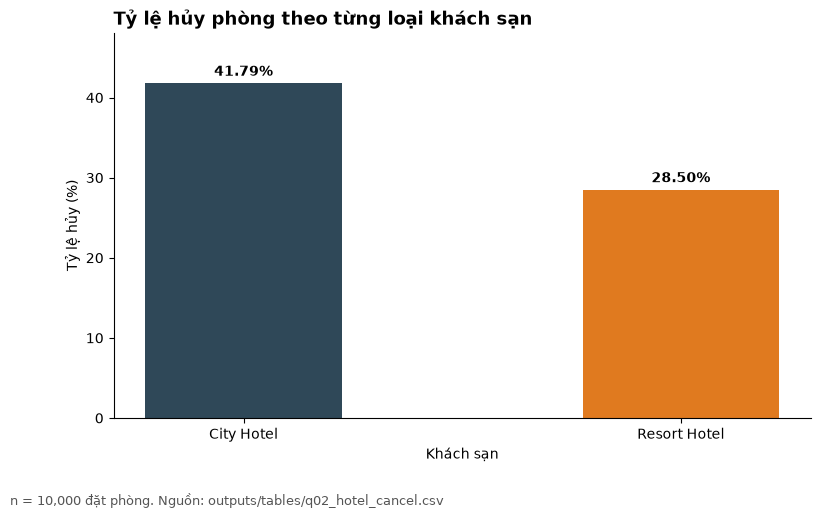

In [87]:
# tạo bảng
q02 = (
    clean_df.groupby('hotel')
    .agg(
        n_bookings=('booking_id', 'count'),
        share_pct=('booking_id', lambda x: round(len(x) / len(clean_df) * 100, 2)),
        n_canceled=('is_canceled', lambda x: (x == 1).sum()),
        cancel_rate_pct=('is_canceled', lambda x: round((x == 1).sum() / len(x) * 100, 2))
    ).reset_index()
)

save_table(q02, 'q02_hotel_cancel')

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=FIGSIZE)

bars = ax.bar(q02['hotel'], q02['cancel_rate_pct'], color=['#2F4858', '#E07A1F'], width=0.45)

# 3. Ghi số liệu % trực tiếp trên đỉnh mỗi cột
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f'{height:.2f}%',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),  # Đẩy chữ lên trên đỉnh cột 3pt
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_ylim(0, max(q02['cancel_rate_pct']) * 1.15)

total_bookings = len(clean_df)
finish_chart(
    ax,
    title='Tỷ lệ hủy phòng theo từng loại khách sạn',
    xlabel='Khách sạn',
    ylabel='Tỷ lệ hủy (%)',
    note=f'n = {total_bookings:,} đặt phòng. Nguồn: outputs/tables/q02_hotel_cancel.csv'
)

save_fig(fig, 'fig01_hotel_cancel')
display(q02)
plt.show()

In [88]:
check('q02_hotel_cancel đã được tạo', lambda: q02 is not None and len(q02) > 0)
check('q02 có đúng 2 khách sạn', lambda: len(q02) == 2)
check('Đã lưu fig01_hotel_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig01_hotel_cancel.png').exists())

✅ q02_hotel_cancel đã được tạo
✅ q02 có đúng 2 khách sạn
✅ Đã lưu fig01_hotel_cancel.png


True

> ✍️ **Nhận xét Câu 2** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
> 1. **Phát hiện chính:** City Hotel có 6.702 đặt phòng (67,02% của 10.000), Resort Hotel có 3.298 (32,98%). Tỷ lệ hủy của City Hotel cao hơn Resort Hotel.
> 2. **Số liệu và mẫu số:** City Hotel hủy 2.801/6.702 = **41,79%**; Resort Hotel hủy 940/3.298 = **28,50%** (mẫu số mỗi nhóm là số đặt phòng của khách sạn đó).
> 3. **So sánh làm rõ:** Chênh **13,29 điểm phần trăm** (gấp **1,47 lần**). City Hotel chiếm 2.801/3.741 = 74,87% số đặt phòng bị hủy, trong khi chiếm 67,02% số đặt phòng.
> 4. **Giới hạn:** Hai khách sạn khác loại hình, vị trí và cơ cấu khách; dữ liệu không có lý do hủy nên không giải thích được chênh lệch này.

> *Nguồn: outputs/tables/q02_hotel_cancel.csv · outputs/figures/fig01_hotel_cancel.png*

## Câu 3 · Mùa vụ: số đặt phòng theo tháng đến năm 2016

| | |
|---|---|
| **Cần tính** | Chỉ năm **2016** (năm duy nhất đủ 12 tháng trong dữ liệu): số đặt phòng theo tháng × khách sạn; tỷ lệ hủy theo tháng. Nêu tháng cao nhất, thấp nhất của mỗi khách sạn. |
| **Mẫu số và trình bày** | Biểu đồ 2: hai đường theo tháng 1–12. Có thể dùng `monthly_summary`. Không so sánh trực tiếp với 2015, 2017 (thiếu tháng). |
| **Đầu ra** | `clean_df` → `q03_monthly_arrivals_2016` + `fig02_monthly_arrivals_2016.png` |

**Gợi ý:** Cột gợi ý: `arrival_month, City Hotel, Resort Hotel, total, cancel_rate_pct`.

💾 outputs/tables/q03_monthly_arrivals_2016.csv  (12 dòng)
🖼️  outputs/figures/fig02_monthly_arrivals_2016.png


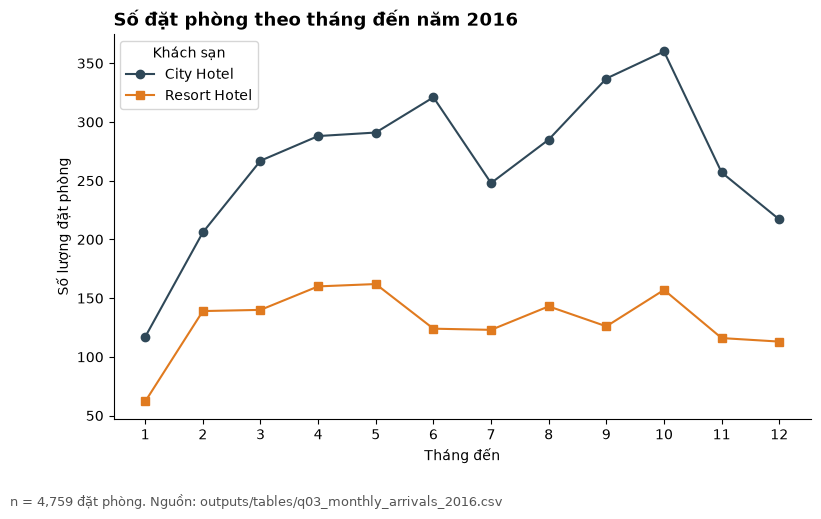

In [ ]:
df_2016 = clean_df[pd.to_datetime(clean_df['arrival_date']).dt.year == 2016].copy()
df_2016['arrival_month'] = pd.to_datetime(df_2016['arrival_date']).dt.month

q03 = (
    df_2016.groupby('arrival_month')
    .agg(
        city_hotel=('hotel', lambda x: (x == 'City Hotel').sum()),
        resort_hotel=('hotel', lambda x: (x == 'Resort Hotel').sum()),
        total=('booking_id', 'count'),
        cancel_rate_pct=('is_canceled', lambda x: round((x == 1).sum() / len(x) * 100, 2))
    )
    .reset_index()
    .rename(columns={'city_hotel': 'City Hotel', 'resort_hotel': 'Resort Hotel'})
)

save_table(q03, 'q03_monthly_arrivals_2016')

# Vẽ biểu đồ 2 đường
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(q03['arrival_month'], q03['City Hotel'], marker='o', label='City Hotel', color='#2F4858')
ax.plot(q03['arrival_month'], q03['Resort Hotel'], marker='s', label='Resort Hotel', color='#E07A1F')
ax.set_xticks(range(1, 13))
ax.legend(title='Khách sạn')

total_2016 = len(df_2016)
finish_chart(
    ax,
    title='Số đặt phòng theo tháng đến năm 2016',
    xlabel='Tháng đến',
    ylabel='Số lượng đặt phòng',
    note=f'n = {total_2016:,} đặt phòng. Nguồn: outputs/tables/q03_monthly_arrivals_2016.csv'
)

save_fig(fig, 'fig02_monthly_arrivals_2016')
plt.show()

In [90]:
check('q03_monthly_arrivals_2016 đã được tạo', lambda: q03 is not None and len(q03) > 0)
check('q03 có đủ 12 tháng', lambda: len(q03) == 12)
check('Đã lưu fig02_monthly_arrivals_2016.png', lambda: (OUTPUT_DIR / 'figures' / 'fig02_monthly_arrivals_2016.png').exists())

✅ q03_monthly_arrivals_2016 đã được tạo
✅ q03 có đủ 12 tháng
✅ Đã lưu fig02_monthly_arrivals_2016.png


True

> ✍️ **Nhận xét Câu 3** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*

> 1. **Phát hiện chính:** Số lượng đặt phòng năm 2016 biến động mạnh theo tháng; City Hotel đạt đỉnh cao nhất vào tháng 10 (360 đơn) và thấp nhất vào tháng 1 (117 đơn), trong khi Resort Hotel đạt đỉnh vào tháng 5 (162 đơn) và thấp nhất vào tháng 1 (62 đơn). Xét chung hai khách sạn, tháng 10 có 517 đặt phòng đến, trong đó 210 hủy (40,62%); tháng 1 có 179 đặt phòng, 40 hủy (22,35%). Tỷ lệ hủy theo tháng chưa tách theo khách sạn.
> 2. **Số liệu và mẫu số:** Tổng số đặt phòng năm 2016 đạt **4,759** đặt phòng (mẫu số tính trên toàn bộ các đơn đến trong năm 2016, bao gồm cả đơn thành công và đơn bị hủy).
> 3. **So sánh làm rõ:** Tháng đỉnh điểm của City Hotel (tháng 10) cao gấp **3.08 lần** so với tháng thấp nhất của chính nó (tháng 1); đối với Resort Hotel, tháng đỉnh điểm (tháng 5) cao gấp **2.61 lần** so với tháng đáy (tháng 1).
> 4. **Giới hạn:** số đặt phòng gồm cả đặt phòng bị hủy nên không phản ánh số khách lưu trú thực tế. Chỉ năm 2016 có đủ 12 tháng nên không tách được mùa vụ khỏi biến động ngẫu nhiên của một năm; 2015 và 2017 thiếu tháng nên không so sánh.

> *Nguồn: bảng `outputs/tables/q03_monthly_arrivals_2016.csv` · `outputs/figures/fig02_monthly_arrivals_2016.png`*

## Câu 4 · Thời gian đặt trước (lead time) và hủy phòng

| | |
|---|---|
| **Cần tính** | Thống kê `lead_time` theo khách sạn (số mẫu, trung bình, trung vị, Q1, Q3, max) và **tỷ lệ hủy theo `lead_time_group`**. |
| **Mẫu số và trình bày** | Biểu đồ 3: cột tỷ lệ hủy theo 5 nhóm, **đúng thứ tự** `0-7 → 181+`. Đây là mối liên hệ quan sát, không phải nhân quả. |
| **Đầu ra** | `clean_df` → `q04_leadtime_stats`, `q04_leadtime_cancel` + `fig03_leadtime_cancel.png` |

**Gợi ý:** Lưu **cả 2 bảng**.

💾 outputs/tables/q04_leadtime_stats.csv  (2 dòng)
💾 outputs/tables/q04_leadtime_cancel.csv  (5 dòng)
🖼️  outputs/figures/fig03_leadtime_cancel.png


,hotel,n_samples,mean,median,q1,q3,max
0,City Hotel,6683,110.78,74.0,24,164,629
1,Resort Hotel,3286,92.99,61.0,12,154,709


,lead_time_group,n_bookings,n_canceled,cancel_rate_pct
0,0-7,1581,159,10.06
1,8-30,1537,425,27.65
2,31-90,2542,946,37.21
3,91-180,2244,1001,44.61
4,181+,2065,1199,58.06


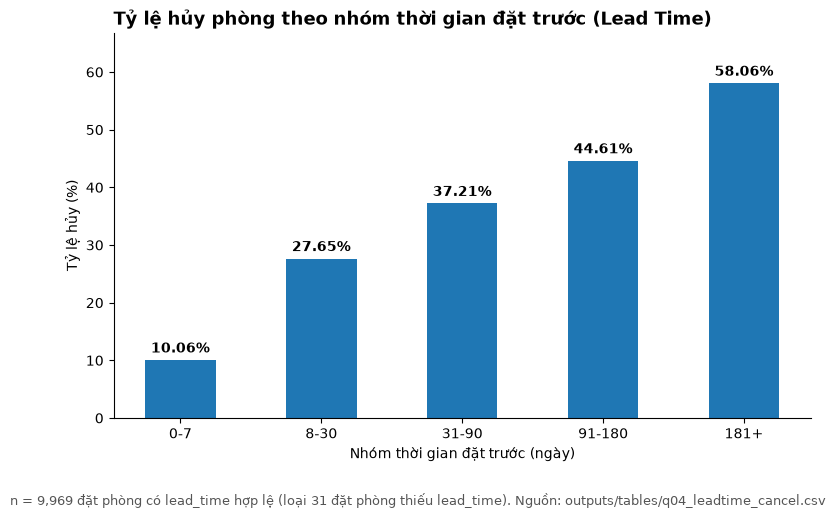

In [ ]:
# 1. BẢNG 1: THỐNG KÊ MÔ TẢ LEAD TIME THEO KHÁCH SẠN (q04)
q04 = (
    clean_df.groupby('hotel')['lead_time']
    .agg(
        n_samples='count',
        mean='mean',
        median='median',
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        max='max'
    )
    .round(2)
    .reset_index()
)

save_table(q04, 'q04_leadtime_stats')

# BẢNG 2: TỶ LỆ HỦY THEO LEAD_TIME_GROUP (q04_b)
q04_b = (
    clean_df.groupby('lead_time_group', observed=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        n_canceled=('is_canceled', lambda x: (x == 1).sum())
    )
    .assign(cancel_rate_pct=lambda df: (df['n_canceled'] / df['n_bookings'] * 100).round(2))
    .reset_index()
)

save_table(q04_b, 'q04_leadtime_cancel')

# VẼ BIỂU ĐỒ FIG03_LEADTIME_CANCEL (DÙNG Q04_B)
fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.bar(q04_b['lead_time_group'], q04_b['cancel_rate_pct'], color='#1f77b4', width=0.5)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f'{height:.2f}%',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_ylim(0, max(q04_b['cancel_rate_pct']) * 1.15)

# Hoàn thiện các thông tin phụ: Tiêu đề, nhãn trục, chú thích nguồn
finish_chart(
    ax,
    title='Tỷ lệ hủy phòng theo nhóm thời gian đặt trước (Lead Time)',
    xlabel='Nhóm thời gian đặt trước (ngày)',
    ylabel='Tỷ lệ hủy (%)',
    note=f'n = {int(q04_b["n_bookings"].sum()):,} đặt phòng có lead_time hợp lệ (loại {int(clean_df["lead_time"].isna().sum())} đặt phòng thiếu lead_time). Nguồn: outputs/tables/q04_leadtime_cancel.csv')

save_fig(fig, 'fig03_leadtime_cancel')
display(q04)
display(q04_b)
plt.show()

In [92]:
check('q04_leadtime_stats đã được tạo', lambda: q04 is not None and len(q04) > 0)
check('q04_leadtime_cancel đã được tạo', lambda: q04_b is not None and len(q04_b) > 0)
check('q04_leadtime_cancel có 5 nhóm', lambda: len(q04_b) == 5)
check('Đã lưu fig03_leadtime_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig03_leadtime_cancel.png').exists())

✅ q04_leadtime_stats đã được tạo
✅ q04_leadtime_cancel đã được tạo
✅ q04_leadtime_cancel có 5 nhóm
✅ Đã lưu fig03_leadtime_cancel.png


True

> ✍️ **Nhận xét Câu 4** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*

> 1. **Phát hiện chính:** Tỷ lệ hủy phòng có mối liên hệ quan sát tăng dần theo thời gian đặt trước (`lead_time`), thấp nhất ở nhóm đặt cận ngày 0-7 ngày (10.06%) và cao nhất ở nhóm đặt xa 181+ ngày (58.06%).
> 2. **Số liệu và mẫu số:** Thống kê trên tổng số **9,969** đặt phòng hợp lệ (gồm 6,683 đơn City Hotel có trung vị `lead_time` là 74.0 ngày và 3,286 đơn Resort Hotel có trung vị là 61.0 ngày).
> 3. **So sánh làm rõ:** Tỷ lệ hủy phòng của nhóm đặt xa nhất (181+ ngày) cao hơn nhóm đặt sát ngày (0-7 ngày) chênh **48.00 điểm phần trăm** (gấp **5.77 lần**). Nhóm 0-7 ngày có 159/1.581 đặt phòng hủy; nhóm 181+ có 1.199/2.065. Tỷ lệ tăng qua cả 5 nhóm (10,06%; 27,65%; 37,21%; 44,61%; 58,06%).
> 4. **Giới hạn:** Đây là mối liên hệ quan sát thống kê thuần túy, không khẳng định nguyên nhân. Nhóm đặt xa có thể khác nhóm đặt gần về loại đặt cọc hay phân khúc; nhóm chưa tách `lead_time_group × deposit_type`.

> *Nguồn: bảng `outputs/tables/q04_leadtime_stats.csv` · `outputs/tables/q04_leadtime_cancel.csv` · `outputs/figures/fig03_leadtime_cancel.png`*

## Câu 5 · Top 10 quốc gia của khách

| | |
|---|---|
| **Cần tính** | Đếm đặt phòng theo `country`; Top 10; tỷ lệ trên **tổng số đặt phòng**; tỷ lệ hủy mỗi nước. Báo cáo riêng số đặt phòng thiếu quốc gia. Đồng hạng → sắp tiếp theo mã. |
| **Mẫu số và trình bày** | Biểu đồ 4: cột ngang, sắp theo số lượng. |
| **Đầu ra** | `clean_df` → `q05_top10_country` + `fig04_top10_country.png` |

**Gợi ý:** Cột gợi ý: `rank, country, n_bookings, pct_of_all_bookings, cancel_rate_pct`.

💾 outputs/tables/q05_top10_country.csv  (10 dòng)
🖼️  outputs/figures/fig04_top10_country.png


,rank,country,n_bookings,pct_of_all_bookings,cancel_rate_pct
78,1,PRT,4005,40.05,57.68
34,2,GBR,999,9.99,19.72
31,3,FRA,876,8.76,19.06
28,4,ESP,700,7.00,24.57
23,5,DEU,650,6.50,18.62
49,6,ITA,294,2.94,33.67
44,7,IRL,281,2.81,23.84
5,8,BEL,201,2.01,18.41
99,9,USA,198,1.98,24.75
9,10,BRA,192,1.92,41.15


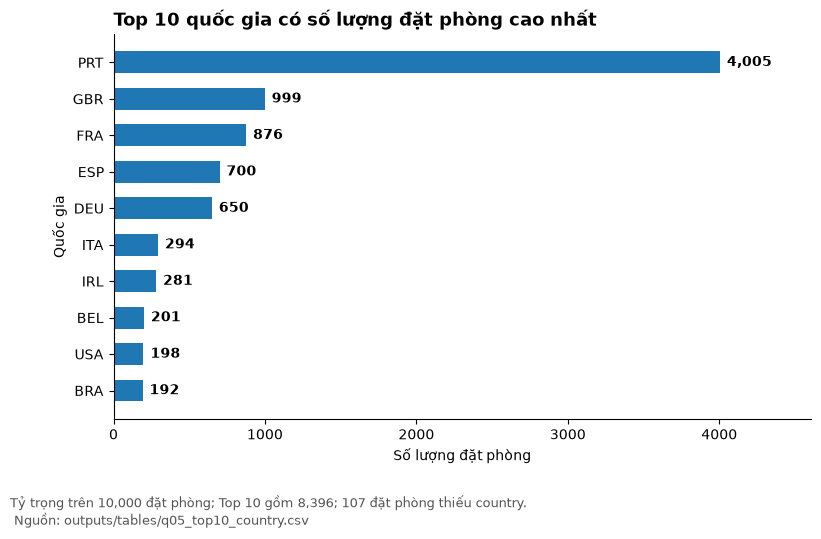

In [ ]:
# Gom nhóm theo quốc gia, tính tổng đơn, tỷ lệ đóng góp (%) và tỷ lệ hủy phòng (%)
q05 = (
    clean_df.dropna(subset=['country'])
    .groupby('country')
    .agg(
        n_bookings=('booking_id', 'count'),
        n_canceled=('is_canceled', lambda x: (x == 1).sum())
    )
    .assign(
        pct_of_all_bookings=lambda df: (df['n_bookings'] / len(clean_df) * 100).round(2),
        cancel_rate_pct=lambda df: (df['n_canceled'] / df['n_bookings'] * 100).round(2)
    )
    .reset_index()
    .sort_values(by=['n_bookings', 'country'], ascending=[False, True])
    .head(10)
    .assign(rank=lambda df: range(1, len(df) + 1))
    [['rank', 'country', 'n_bookings', 'pct_of_all_bookings', 'cancel_rate_pct']]
)

save_table(q05, 'q05_top10_country')

# Vẽ biểu đồ cột ngang (Top 1 ở trên cùng)
fig, ax = plt.subplots(figsize=FIGSIZE)
plot_df = q05.sort_values('n_bookings', ascending=True)
bars = ax.barh(plot_df['country'], plot_df['n_bookings'], color='#1f77b4', height=0.6)

# Thêm nhãn số liệu trực tiếp trên từng thanh của biểu đồ
for bar in bars:
    ax.annotate(
        f'{int(bar.get_width()):,}',
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        ha='left',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

ax.set_xlim(0, max(q05['n_bookings']) * 1.15)
# Hoàn thiện các thông tin phụ: Tiêu đề, nhãn trục, chú thích nguồn
finish_chart(
    ax,
    title='Top 10 quốc gia có số lượng đặt phòng cao nhất',
    xlabel='Số lượng đặt phòng',
    ylabel='Quốc gia',
    note=f'Tỷ trọng trên {len(clean_df):,} đặt phòng; Top 10 gồm {int(q05["n_bookings"].sum()):,}; {int(clean_df["country"].isna().sum())} đặt phòng thiếu country. \n Nguồn: outputs/tables/q05_top10_country.csv'
)

save_fig(fig, 'fig04_top10_country')
display(q05)
plt.show()

In [94]:
check('q05_top10_country đã được tạo', lambda: q05 is not None and len(q05) > 0)
check('q05 có 10 quốc gia', lambda: len(q05) == 10)
check('Đã lưu fig04_top10_country.png', lambda: (OUTPUT_DIR / 'figures' / 'fig04_top10_country.png').exists())

✅ q05_top10_country đã được tạo
✅ q05 có 10 quốc gia
✅ Đã lưu fig04_top10_country.png


True

> ✍️ **Nhận xét Câu 5** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*

> 1. **Phát hiện chính:** Bồ Đào Nha (PRT) là thị trường lớn nhất, đồng thời có tỷ lệ hủy cao hơn hẳn các thị trường châu Âu lớn khác.
> 2. **Số liệu và mẫu số:** Tỷ trọng tính trên 10.000 đặt phòng; có **9.893** đặt phòng có mã quốc gia và **107** đặt phòng thiếu quốc gia (báo cáo riêng). Top 10 gồm 8.396 đặt phòng (83,96% tổng).
> 3. **So sánh làm rõ:** PRT 4.005 đặt phòng (40,05%), tỷ lệ hủy 57,68%. GBR (999), FRA (876), ESP (700), DEU (650) có tỷ lệ hủy 18,62%–24,57%. PRT hủy 2.310 đặt phòng, chiếm 2.310/3.741 = 61,75% tổng số đặt phòng bị hủy.
> 4. **Giới hạn:** Theo tác giả bộ dữ liệu gốc, quốc gia thường chỉ được xác nhận khi nhận phòng, nên `country` của đặt phòng hủy có thể kém chính xác (Mục 5.4). 107 đặt phòng thiếu `country` không nằm trong Top 10. Mã `CN` giữ nguyên, không gộp với `CHN`. Dữ liệu không có thông tin cơ cấu khách của từng quốc gia.

> *Nguồn: bảng `outputs/tables/q05_top10_country.csv` · `outputs/figures/fig04_top10_country.png`*

## Câu 6 · Phân khúc thị trường

| | |
|---|---|
| **Cần tính** | Theo `market_segment`: số đặt phòng, tỷ trọng, tỷ lệ hủy; báo cáo riêng số thiếu phân khúc. |
| **Mẫu số và trình bày** | Biểu đồ 5: cột ngang (số đặt phòng hoặc tỷ lệ hủy), sắp theo giá trị. Nêu phân khúc nhỏ (ví dụ Aviation) có mẫu ít → tỷ lệ kém ổn định. |
| **Đầu ra** | `clean_df` → `q06_segment_cancel` + `fig05_segment_cancel.png` |

**Gợi ý:** Thêm cột `n_bookings` cạnh tỷ lệ để người đọc thấy cỡ mẫu.

💾 outputs/tables/q06_segment_cancel.csv  (7 dòng)


,market_segment,n_bookings,n_canceled,share_pct,cancel_rate_pct
6,Online TA,4741,1753,47.42,36.98
5,Offline TA/TO,2012,683,20.13,33.95
4,Groups,1703,1054,17.04,61.89
3,Direct,1018,153,10.18,15.03
2,Corporate,441,81,4.41,18.37
1,Complementary,61,10,0.61,16.39
0,Aviation,21,5,0.21,23.81


🖼️  outputs/figures/fig05_segment_cancel.png


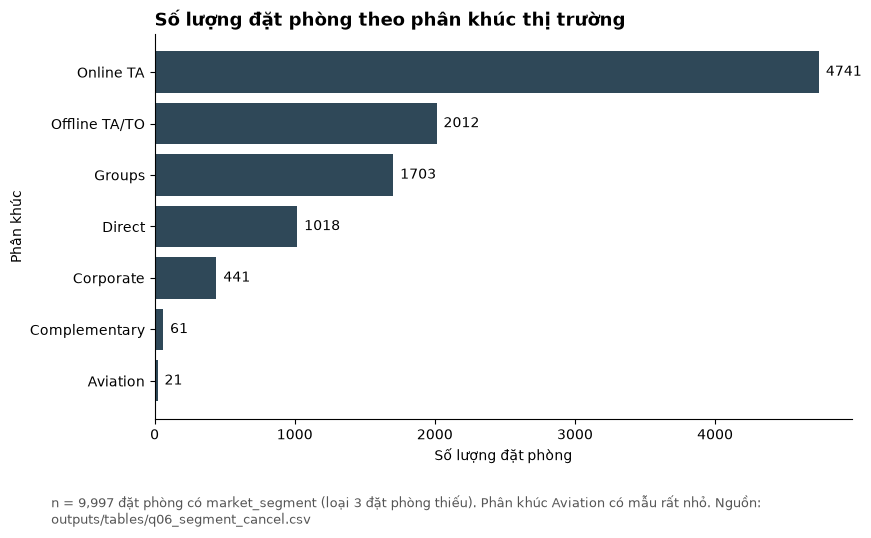

In [95]:
# 1. Tính toán bảng q06_segment_cancel
segment_df = clean_df.copy()
q06 = segment_df.groupby('market_segment').agg(
    n_bookings=('booking_id', 'count'),
    n_canceled=('is_canceled', 'sum')
).reset_index()

# Tính tỷ trọng (% share) và tỷ lệ hủy (% cancel_rate)
q06['share_pct'] = (q06['n_bookings'] / q06['n_bookings'].sum() * 100).round(2)   # mẫu số = 9.997 đặt phòng có market_segment
q06['cancel_rate_pct'] = (q06['n_canceled'] / q06['n_bookings'] * 100).round(2)
q06 = q06.sort_values('n_bookings', ascending=False)

save_table(q06, 'q06_segment_cancel')
display(q06)
# 2. Vẽ biểu đồ fig05_segment_cancel
fig, ax = plt.subplots(figsize=FIGSIZE)
q06_plot = q06.sort_values('n_bookings', ascending=True)
bars = ax.barh(q06_plot["market_segment"], q06_plot["n_bookings"], color="#2F4858")
ax.bar_label(bars, padding=5)
finish_chart(
    ax,
    'Số lượng đặt phòng theo phân khúc thị trường',
    'Số lượng đặt phòng',
    'Phân khúc',
    note=f"n = {int(q06['n_bookings'].sum()):,} đặt phòng có market_segment (loại {int(segment_df['market_segment'].isna().sum())} đặt phòng thiếu). Phân khúc Aviation có mẫu rất nhỏ. Nguồn: outputs/tables/q06_segment_cancel.csv"
)

save_fig(fig, 'fig05_segment_cancel')
plt.show()

In [96]:
check('q06_segment_cancel đã được tạo', lambda: q06 is not None and len(q06) > 0)
check('Đã lưu fig05_segment_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig05_segment_cancel.png').exists())

✅ q06_segment_cancel đã được tạo
✅ Đã lưu fig05_segment_cancel.png


True

> **✍️ Nhận xét Câu 6** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Online TA là phân khúc lớn nhất (47,42% số đặt phòng), nhưng Groups là phân khúc có tỷ lệ hủy cao nhất (61,89%); Direct có tỷ lệ hủy thấp nhất (15,03%).
> 2. **Số liệu và mẫu số:** tính trên 9.997 đặt phòng có phân khúc (loại 3 đặt phòng thiếu phân khúc, báo cáo riêng). Mẫu số tỷ lệ hủy của mỗi phân khúc là số đặt phòng của phân khúc đó.
> 3. **So sánh làm rõ:** Online TA có 4.741 đặt phòng (47,42%), hủy 36,98%. Offline TA/TO có 2.012 (20,13%), hủy 33,95%. Groups có 1.703 (17,04%), hủy 61,89%, cao hơn Direct (1.018 đặt phòng, hủy 15,03%) 46,86 điểm phần trăm, gấp khoảng 4,1 lần. Corporate (441) hủy 18,37%. Trong 1.703 đặt phòng Groups, 813 (47,74%) là Non Refund với tỷ lệ hủy 99,02% (805/813); riêng Groups No Deposit hủy 27,95% (246/880), cách Direct No Deposit (14,96%) 12,99 điểm. Chênh lệch giữa Groups và Direct thu hẹp từ 46,86 xuống 12,99 điểm khi chỉ xét No Deposit.
> 4. **Giới hạn:** Aviation (n = 21) và Complementary (n = 61) có cỡ mẫu nhỏ nên tỷ lệ kém ổn định. Dữ liệu không có điều khoản hợp đồng của từng phân khúc, nên không giải thích được vì sao Groups hủy nhiều.
>
> *Nguồn: `outputs/tables/q06_segment_cancel.csv` · `outputs/tables/x01_segment_deposit_cancel.csv` · `outputs/figures/fig05_segment_cancel.png`*

## Câu 7 · Loại đặt cọc và trạng thái đặt phòng

| | |
|---|---|
| **Cần tính** | Bảng chéo `deposit_type × reservation_status`; tỷ lệ **trong từng loại đặt cọc** (Check-Out, Canceled, No-Show, và `Unknown` nếu trạng thái thiếu). |
| **Mẫu số và trình bày** | Biểu đồ 6: cột chồng 100%. So sánh tỷ lệ hủy giữa các loại theo điểm phần trăm và nêu cỡ mẫu (Refundable rất ít). |
| **Đầu ra** | `clean_df` → `q07_deposit_cancel` + `fig06_deposit_cancel.png` |

**Gợi ý:** `pd.crosstab(..., normalize='index')`; điền `'Unknown'` **chỉ khi trình bày**.

reservation_status,deposit_type,Canceled,Check-Out,No-Show,Unknown,n_Canceled,n_Check-Out,n_No-Show,n_Unknown,n_total
0,No Deposit,27.23,71.31,1.2,0.25,2377,6224,105,22,8728
1,Non Refund,98.81,0.95,0.0,0.24,1244,12,0,3,1259
2,Refundable,38.46,61.54,0.0,0.00,5,8,0,0,13


💾 outputs/tables/q07_deposit_cancel.csv  (3 dòng)
🖼️  outputs/figures/fig06_deposit_cancel.png


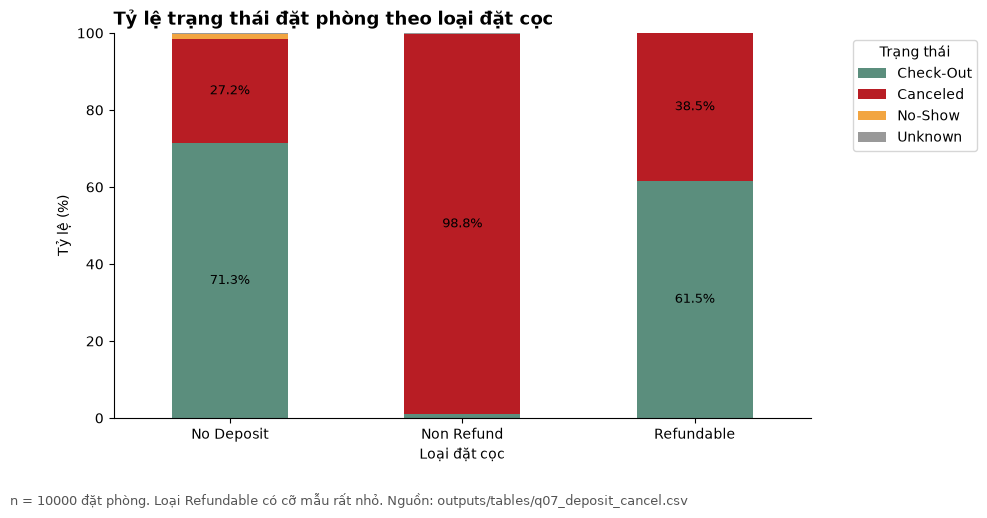

In [97]:
# 1. Tính toán bảng q07_deposit_cancel
q07_cross = pd.crosstab(clean_df['deposit_type'], clean_df['reservation_status'].fillna('Unknown'))

# Tính tỷ lệ phần trăm theo từng loại đặt cọc (theo hàng)
q07_pct = q07_cross.div(q07_cross.sum(axis=1), axis=0) * 100
q07 = q07_pct.round(2).join(q07_cross.add_prefix('n_')).assign(n_total=q07_cross.sum(axis=1)).reset_index()
display(q07)
save_table(q07, 'q07_deposit_cancel')

# 2. Vẽ biểu đồ fig06_deposit_cancel
fig, ax = plt.subplots(figsize=FIGSIZE)

# Lọc các cột trạng thái hiện có và áp dụng bảng màu STATUS_COLORS chuẩn
plot_cols = [c for c in ['Check-Out', 'Canceled', 'No-Show', 'Unknown'] if c in q07_pct.columns]
q07_pct[plot_cols].plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=[STATUS_COLORS.get(c, '#999999') for c in plot_cols]
)

# Hiển thị nhãn % ở giữa mỗi đoạn cột
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:.1f}%' if v >= 3 else '' for v in container.datavalues], label_type='center', fontsize=9)
ax.legend(title='Trạng thái', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)

finish_chart(
    ax,
    'Tỷ lệ trạng thái đặt phòng theo loại đặt cọc',
    'Loại đặt cọc',
    'Tỷ lệ (%)',
    note=f"n = {len(clean_df)} đặt phòng. Loại Refundable có cỡ mẫu rất nhỏ. Nguồn: outputs/tables/q07_deposit_cancel.csv"
)

save_fig(fig, 'fig06_deposit_cancel')
plt.show()

In [98]:
check('q07_deposit_cancel đã được tạo', lambda: q07 is not None and len(q07) > 0)
check('Đã lưu fig06_deposit_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig06_deposit_cancel.png').exists())

✅ q07_deposit_cancel đã được tạo
✅ Đã lưu fig06_deposit_cancel.png


True

> **✍️ Nhận xét Câu 7** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Nhóm Non Refund có 98,81% đặt phòng ở trạng thái Canceled (1.244/1.259), cao hơn nhiều so với No Deposit (27,23%, 2.377/8.728).
> 2. **Số liệu và mẫu số:** Tính trên 10.000 đặt phòng, mẫu số mỗi nhóm là số đặt phòng của loại đặt cọc đó.
> 3. **So sánh làm rõ:** No Deposit (8.728): Check-Out 71,31%, Canceled 27,23%, No-Show 1,20%, thiếu trạng thái 0,25%. Non Refund (1.259): Canceled **98,81%** (1.244), Check-Out chỉ 0,95% (12). Non Refund chiếm 12,59% số đặt phòng nhưng 1.244/3.626 = 34,31% số đặt phòng ở trạng thái Canceled. Refundable chỉ có 13 đặt phòng (5 Canceled, 8 Check-Out), không đủ để so sánh.
> 4. **Giới hạn:** Không kết luận "đặt cọc làm khách hủy". Có thể do cách ghi nhận hoặc đặc điểm nhóm khách; cần dữ liệu bổ sung để kiểm chứng (ví dụ điều khoản hoàn tiền theo thời kỳ).
>
> *Nguồn: `outputs/tables/q07_deposit_cancel.csv` · `outputs/figures/fig06_deposit_cancel.png`*

In [99]:
# Bảng phụ cho Insight 6: tỷ lệ hủy theo phân khúc × loại đặt cọc
# Mẫu số: đặt phòng có đủ market_segment, deposit_type và is_canceled (9.997 đặt phòng)
x01 = (clean_df.dropna(subset=['market_segment', 'deposit_type', 'is_canceled'])
       .groupby(['market_segment', 'deposit_type'], observed=True)
       .agg(n_bookings=('booking_id', 'count'),
            n_canceled=('is_canceled', lambda x: (x == 1).sum()))
       .assign(cancel_rate_pct=lambda d: (d['n_canceled'] / d['n_bookings'] * 100).round(2))
       .reset_index())
display(x01)
save_table(x01, 'x01_segment_deposit_cancel')

,market_segment,deposit_type,n_bookings,n_canceled,cancel_rate_pct
0,Aviation,No Deposit,21,5,23.81
1,Complementary,No Deposit,61,10,16.39
2,Corporate,No Deposit,412,55,13.35
3,Corporate,Non Refund,28,26,92.86
4,Corporate,Refundable,1,0,0.0
5,Direct,No Deposit,1016,152,14.96
6,Direct,Non Refund,2,1,50.0
7,Groups,No Deposit,880,246,27.95
8,Groups,Non Refund,813,805,99.02
9,Groups,Refundable,10,3,30.0


⚠️  Tên x01_segment_deposit_cancel.csv không có trong danh sách chuẩn: kiểm tra lại chính tả.
💾 outputs/tables/x01_segment_deposit_cancel.csv  (15 dòng)


## Câu 8 · Giá phòng bình quân/đêm (ADR)

| | |
|---|---|
| **Cần tính** | Chỉ đặt phòng **không hủy** có `adr` hợp lệ **và > 0**: theo khách sạn — số mẫu, trung bình, trung vị, min, max, Q1, Q3. Báo cáo riêng số `adr = 0` và số thiếu. |
| **Mẫu số và trình bày** | Biểu đồ 7: histogram độ rộng khoảng 20 EUR, tách hai khách sạn (2 panel hoặc chồng trong suốt). Không xóa giá cao trong miền. |
| **Đầu ra** | `clean_df` → `q08_adr_stats_by_hotel` + `fig07_adr_hist.png` |

**Gợi ý:** `groupby('hotel')['adr'].describe()`.

6121


,hotel,n_samples,mean,median,min,max,Q1,Q3
0,City Hotel,3828,108.18,100.65,4.5,336.00,80.75,126.9
1,Resort Hotel,2293,93.60,75.00,6.0,349.67,51.50,120.0


💾 outputs/tables/q08_adr_stats_by_hotel.csv  (2 dòng)
🖼️  outputs/figures/fig07_adr_hist.png


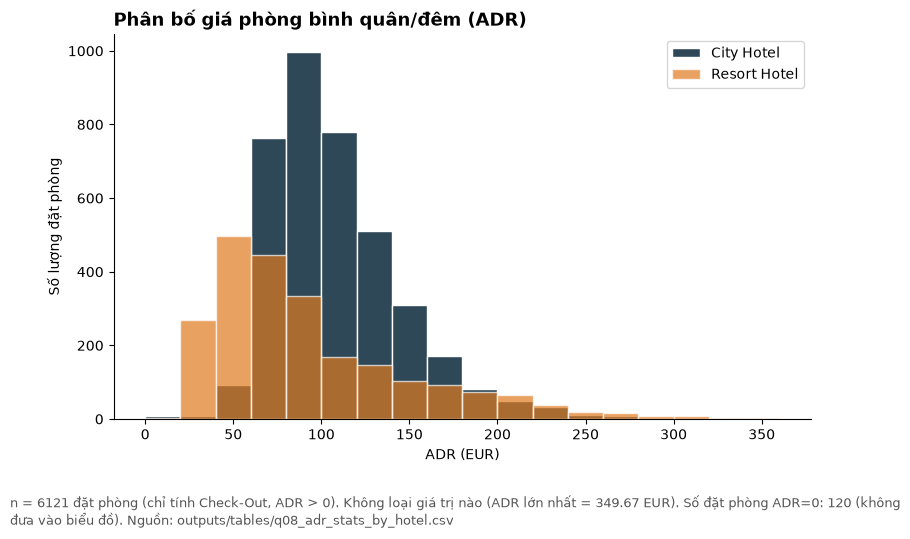

In [100]:
adr_df = clean_df[(clean_df['is_canceled'] == 0) & (clean_df['adr'] > 0)].copy()
print(len(adr_df))
q08 = adr_df.groupby('hotel')['adr'].agg(
    n_samples='count',
    mean='mean',
    median='median',
    min = 'min',
    max = 'max',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
).round(2).reset_index()
display(q08)
save_table(q08, 'q08_adr_stats_by_hotel')

fig, ax = plt.subplots(figsize=FIGSIZE)
bins = np.arange(0, adr_df['adr'].max() + 20, 20)
ax.hist(adr_df[adr_df['hotel'] == 'City Hotel']['adr'], bins=bins, alpha=1, color=HOTEL_COLORS['City Hotel'], label='City Hotel', edgecolor='white')
ax.hist(adr_df[adr_df['hotel'] == 'Resort Hotel']['adr'], bins=bins, alpha=0.7, color=HOTEL_COLORS['Resort Hotel'], label='Resort Hotel', edgecolor='white')
ax.legend()
zero_adr_count = len(clean_df[(clean_df['is_canceled'] == 0) & (clean_df['adr'] == 0)])
finish_chart(ax,
    'Phân bố giá phòng bình quân/đêm (ADR)',
    'ADR (EUR)',
    'Số lượng đặt phòng',
    note=f"n = {len(adr_df)} đặt phòng (chỉ tính Check-Out, ADR > 0). Không loại giá trị nào (ADR lớn nhất = {adr_df['adr'].max():.2f} EUR). Số đặt phòng ADR=0: {zero_adr_count} (không đưa vào biểu đồ). Nguồn: outputs/tables/q08_adr_stats_by_hotel.csv"
)
save_fig(fig, 'fig07_adr_hist')
plt.show()

In [101]:
check('q08_adr_stats_by_hotel đã được tạo', lambda: q08 is not None and len(q08) > 0)
check('Đã lưu fig07_adr_hist.png', lambda: (OUTPUT_DIR / 'figures' / 'fig07_adr_hist.png').exists())

✅ q08_adr_stats_by_hotel đã được tạo
✅ Đã lưu fig07_adr_hist.png


True

> **✍️ Nhận xét Câu 8** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Resort Hotel có phân bố ADR rộng hơn City Hotel: khoảng Q1–Q3 rộng 68,50 EUR (51,50–120,00) so với 46,15 EUR (80,75–126,90) của City Hotel. ADR lớn nhất là 349,67 EUR (Resort) và 336,00 EUR (City).
> 2. **Số liệu và mẫu số:** Đặt phòng **không hủy** (`is_canceled = 0`, 6.259), trong đó `adr > 0` là **6.121**, `adr = 0` là 120, `adr` thiếu là 18.
> 3. **So sánh làm rõ:** City Hotel (3.828): trung bình 108,18, trung vị 100,65, Q1–Q3 = 80,75–126,90. Resort Hotel (2.293): trung bình 93,60, trung vị 75,00, Q1–Q3 = 51,50–120,00. Trung bình cao hơn trung vị ở cả hai khách sạn (City +7,53 EUR; Resort +18,60 EUR), tức phân bố lệch phải, lệch nhiều hơn ở Resort. Trung vị Resort (75,00) thấp hơn City (100,65) 25,65 EUR, trong khi trung bình chỉ chênh 14,58 EUR.
> 4. **Giới hạn:** ADR là giá bình quân/đêm, không phải doanh thu thực. Chỉ tính đặt phòng Check-Out; dữ liệu không tách theo mùa nên chưa kết luận được giá phụ thuộc mùa.
>
> *Nguồn: `outputs/tables/q08_adr_stats_by_hotel.csv` · `outputs/figures/fig07_adr_hist.png`*

## Câu 9 · Thời gian lưu trú

| | |
|---|---|
| **Cần tính** | Đặt phòng **không hủy** có `total_nights` hợp lệ: phân bố theo số đêm (0, 1, …, 14, `15+`) và khách sạn; tỷ lệ lưu trú 1–3 đêm; số đặt phòng 0 đêm (báo cáo riêng). |
| **Mẫu số và trình bày** | Biểu đồ 8: cột theo số đêm **tăng dần**, tách khách sạn. |
| **Đầu ra** | `clean_df` → `q09_stay_nights` + `fig08_stay_nights.png` |

**Gợi ý:** Cột gợi ý: `nights_group, City Hotel, Resort Hotel, total, pct`.

6234


hotel,nights_group,City Hotel,Resort Hotel,total,pct
0,0,8,29,37,0.59
1,1,788,525,1313,21.06
2,2,909,363,1272,20.40
3,3,1033,304,1337,21.45
4,4,650,249,899,14.42
5,5,252,153,405,6.50
6,6,91,100,191,3.06
7,7,107,406,513,8.23
8,8,14,40,54,0.87
9,9,10,29,39,0.63


💾 outputs/tables/q09_stay_nights.csv  (16 dòng)
1-3 đêm: 3922/6234 = 62.91%
  City Hotel: 2730/3884 = 70.29%
  Resort Hotel: 1192/2350 = 50.72%
🖼️  outputs/figures/fig08_stay_nights.png


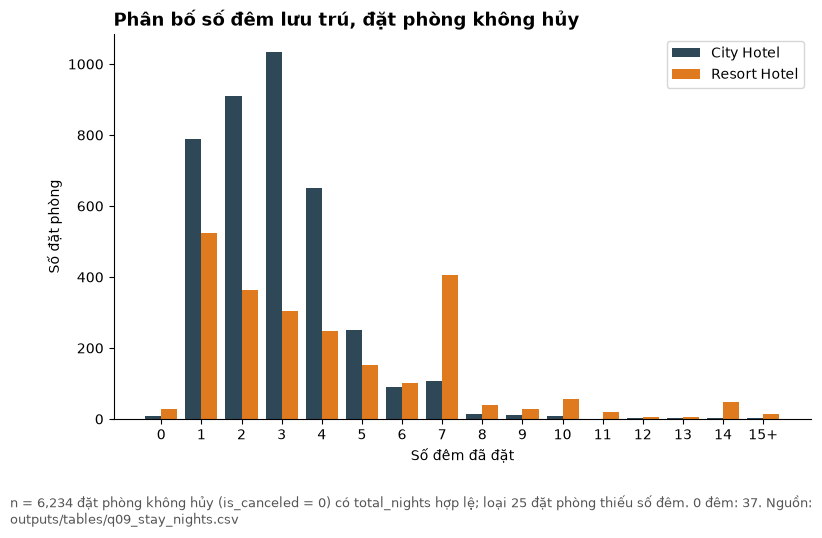

In [102]:
# 1. Tính toán bảng q09_stay_nights
stay_df = clean_df[(clean_df['is_canceled'] == 0) & (clean_df['total_nights'].notna())].copy()
stay_df['nights_group'] = stay_df['total_nights'].apply(lambda x: str(int(x)) if x <= 14 else '15+')
print(len(stay_df))
# Thiết lập Categorical để sắp xếp đúng thứ tự từ 0 đến 14 và 15+
order = [str(i) for i in range(15)] + ['15+']
stay_df['nights_group'] = pd.Categorical(stay_df['nights_group'], categories=order, ordered=True)

q09_cross = pd.crosstab(stay_df['nights_group'], stay_df['hotel'])
q09 = q09_cross.reset_index()
q09['total'] = q09.get('City Hotel', 0) + q09.get('Resort Hotel', 0)
q09['pct'] = (q09['total'] / q09['total'].sum() * 100).round(2)
q09 = q09.sort_values('nights_group')
display(q09)
save_table(q09, 'q09_stay_nights')
short_total = int(q09.loc[q09['nights_group'].isin(['1', '2', '3']), 'total'].sum())
short_by_hotel = {h: int(q09.loc[q09['nights_group'].isin(['1', '2', '3']), h].sum()) for h in ['City Hotel', 'Resort Hotel']}
print(f"1-3 đêm: {short_total}/{len(stay_df)} = {short_total/len(stay_df)*100:.2f}%")
for h, v in short_by_hotel.items():
    n_h = int((stay_df['hotel'] == h).sum()); print(f"  {h}: {v}/{n_h} = {v/n_h*100:.2f}%")

# 2. Vẽ biểu đồ fig08_stay_nights
fig, ax = plt.subplots(figsize=FIGSIZE)
x = np.arange(len(q09)); w = 0.4
ax.bar(x - w/2, q09['City Hotel'], w, label='City Hotel', color=HOTEL_COLORS['City Hotel'])
ax.bar(x + w/2, q09['Resort Hotel'], w, label='Resort Hotel', color=HOTEL_COLORS['Resort Hotel'])
ax.set_xticks(x); ax.set_xticklabels(q09['nights_group']); ax.legend()
n_no_nights = int(((clean_df['is_canceled'] == 0) & clean_df['total_nights'].isna()).sum())
zero_nights = int((stay_df['total_nights'] == 0).sum())   # số đặt phòng 0 đêm (báo cáo riêng)
finish_chart(ax, 'Phân bố số đêm lưu trú, đặt phòng không hủy', 'Số đêm đã đặt', 'Số đặt phòng',
             note=f"n = {len(stay_df):,} đặt phòng không hủy (is_canceled = 0) có total_nights hợp lệ; loại {n_no_nights} đặt phòng thiếu số đêm. "
                  f"0 đêm: {zero_nights}. Nguồn: outputs/tables/q09_stay_nights.csv")
save_fig(fig, 'fig08_stay_nights')
plt.show()

In [103]:
check('q09_stay_nights đã được tạo', lambda: q09 is not None and len(q09) > 0)
check('Đã lưu fig08_stay_nights.png', lambda: (OUTPUT_DIR / 'figures' / 'fig08_stay_nights.png').exists())

✅ q09_stay_nights đã được tạo
✅ Đã lưu fig08_stay_nights.png


True

> **✍️ Nhận xét Câu 9** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Lưu trú 1–3 đêm chiếm đa số ở cả hai khách sạn, rõ hơn ở City Hotel. Ở Resort Hotel có một cụm riêng ở 7 đêm.
> 2. **Số liệu và mẫu số:** Tính trên 6.234 đặt phòng không hủy (`is_canceled = 0`) có `total_nights` hợp lệ (loại 25 đặt phòng thiếu số đêm); trong đó 37 đặt phòng có 0 đêm vẫn được giữ.
> 3. **So sánh làm rõ:** 1–3 đêm: 3.922/6.234 = 62,91% tổng; City Hotel 2.730/3.884 = 70,29%; Resort Hotel 1.192/2.350 = 50,72%. Resort Hotel có 406 đặt phòng 7 đêm (17,28% của 2.350), nhiều hơn số đặt phòng 4 đêm (249) và 5 đêm (153) của khách sạn này; ở City Hotel, 7 đêm chỉ có 107 (2,75% của 3.884).
> 4. **Giới hạn:** Dữ liệu không có mục đích chuyến đi nên không giải thích được cụm 7 đêm. Chỉ tính đặt phòng không hủy; đặt phòng bị hủy không có số đêm thực tế.
>
> *Nguồn: `outputs/tables/q09_stay_nights.csv` · `outputs/figures/fig08_stay_nights.png`*

## Câu 10 · Đổi loại phòng khi nhận phòng

| | |
|---|---|
| **Cần tính** | Trong đặt phòng **Check-Out** có đủ cả hai loại phòng: tỷ lệ `room_changed_flag` theo khách sạn và theo `reserved_room_type`. |
| **Mẫu số và trình bày** | Mẫu số: số đặt phòng Check-Out có đủ hai loại phòng. Biểu đồ tùy chọn (`fig09_room_change.png`). Không suy ra lý do đổi phòng (nâng hạng hay hết phòng). |
| **Đầu ra** | `clean_df` → `q10_room_change_by_hotel`, `q10_room_change_by_reserved_type` |

**Gợi ý:** Với loại phòng có rất ít đặt phòng, nêu cỡ mẫu bên cạnh tỷ lệ.

In [104]:
display(clean_df)

,booking_id,row_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date,arrival_year,arrival_month,total_nights,total_guests,lead_time_group,room_changed_flag,revenue_est
0,BK000014,R04856,Resort Hotel,0,18,2015-07-01,0,4,2,1,0,HB,ESP,Online TA,TA/TO,0,G,G,No Deposit,Transient,154.77,1,Check-Out,2015-07-05,2015,7,4,3,8-30,False,619.08
1,BK000024,R02942,Resort Hotel,0,72,2015-07-01,2,4,2,0,0,BB,PRT,Direct,Direct,0,D,D,No Deposit,Transient,99.67,1,Check-Out,2015-07-07,2015,7,6,2,31-90,False,598.02
2,BK000026,R05381,Resort Hotel,0,78,2015-07-01,2,5,2,0,0,BB,PRT,Offline TA/TO,TA/TO,0,D,D,No Deposit,Transient,63.60,0,Check-Out,2015-07-08,2015,7,7,2,31-90,False,445.20
3,BK000029,R06423,Resort Hotel,0,77,2015-07-01,2,5,2,0,0,BB,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,94.00,0,Check-Out,2015-07-08,2015,7,7,2,31-90,False,658.00
4,BK000060,R02591,Resort Hotel,0,14,2015-07-02,0,2,2,0,0,BB,USA,Online TA,TA/TO,0,A,C,No Deposit,Transient,98.00,1,Check-Out,2015-07-04,2015,7,2,2,8-30,True,196.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,BK119347,R07870,City Hotel,0,45,2017-08-27,2,5,2,0,0,HB,ESP,Online TA,TA/TO,0,A,A,No Deposit,Transient,183.86,2,Check-Out,2017-09-03,2017,8,7,2,31-90,False,1287.02
9996,BK119348,R01240,City Hotel,0,63,2017-08-31,0,3,3,0,0,BB,SWE,Online TA,TA/TO,0,D,D,No Deposit,Transient-Party,195.33,2,Check-Out,2017-09-03,2017,8,3,3,31-90,False,585.99
9997,BK119352,R03326,City Hotel,0,72,2017-08-31,0,3,2,0,0,BB,POL,Direct,Direct,0,D,D,No Deposit,Transient,134.82,1,Check-Out,2017-09-03,2017,8,3,2,31-90,False,404.46
9998,BK119369,R06033,City Hotel,0,261,2017-08-30,1,4,2,0,0,BB,DEU,Direct,Direct,0,A,A,No Deposit,Transient,99.00,0,Check-Out,2017-09-04,2017,8,5,2,181+,False,495.00


6242


,hotel,n_bookings,n_changed,change_rate_pct
0,City Hotel,3891,561,14.42
1,Resort Hotel,2351,583,24.80


,reserved_room_type,n_bookings,n_changed,change_rate_pct
0,A,4287,948,22.11
3,D,1137,114,10.03
4,E,397,47,11.84
5,F,174,15,8.62
6,G,110,3,2.73
1,B,64,11,17.19
2,C,50,4,8.00
7,H,23,2,8.70


💾 outputs/tables/q10_room_change_by_hotel.csv  (2 dòng)
💾 outputs/tables/q10_room_change_by_reserved_type.csv  (8 dòng)
⚠️  Tên fig09_room_change.png không có trong danh sách chuẩn: kiểm tra lại chính tả.
🖼️  outputs/figures/fig09_room_change.png


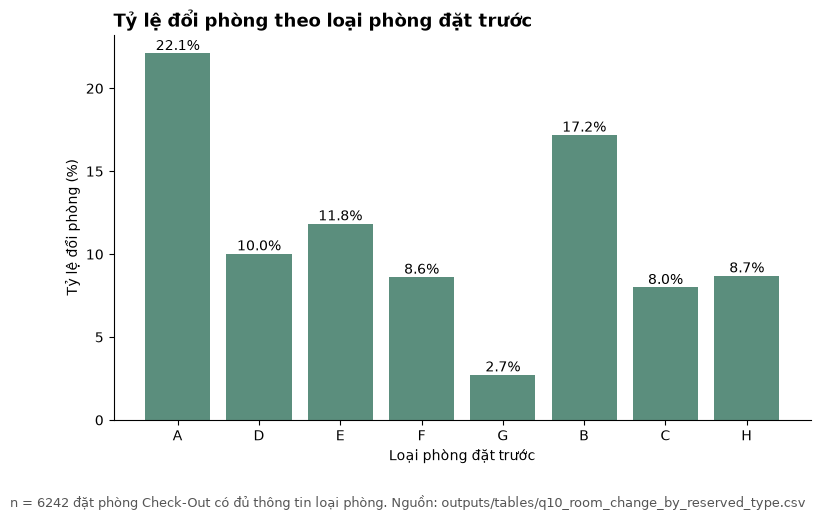

In [105]:
# 1. Tính toán q10_room_change
change_df = clean_df[(clean_df['reservation_status'] == 'Check-Out') &
                     clean_df['reserved_room_type'].notna() &
                     clean_df['assigned_room_type'].notna()].copy()
print(len(change_df))

# Bảng theo khách sạn
q10 = change_df.groupby('hotel').agg(
    n_bookings=('booking_id', 'count'),
    n_changed=('room_changed_flag', 'sum')
).reset_index()
q10['change_rate_pct'] = (q10['n_changed'] / q10['n_bookings'] * 100).round(2)
display(q10)
# Bảng theo loại phòng đặt trước
q10_b = change_df.groupby('reserved_room_type').agg(
    n_bookings=('booking_id', 'count'),
    n_changed=('room_changed_flag', 'sum')
).reset_index()
q10_b['change_rate_pct'] = (q10_b['n_changed'] / q10_b['n_bookings'] * 100).round(2)
q10_b = q10_b.sort_values('n_bookings', ascending=False)
display(q10_b)
save_table(q10, 'q10_room_change_by_hotel')
save_table(q10_b, 'q10_room_change_by_reserved_type')

# 2. Vẽ biểu đồ fig09_room_change
fig, ax = plt.subplots(figsize=FIGSIZE)
q10_b_plot = q10_b[q10_b['n_bookings'] >= 10]  # Lọc loại phòng có mẫu đủ lớn (>= 10 đơn)
bars = ax.bar(q10_b_plot['reserved_room_type'], q10_b_plot['change_rate_pct'], color='#5B8E7D')
ax.bar_label(bars, fmt='%.1f%%')

finish_chart(
    ax,
    'Tỷ lệ đổi phòng theo loại phòng đặt trước',
    'Loại phòng đặt trước',
    'Tỷ lệ đổi phòng (%)',
    note=f"n = {len(change_df)} đặt phòng Check-Out có đủ thông tin loại phòng. Nguồn: outputs/tables/q10_room_change_by_reserved_type.csv"
)

save_fig(fig, 'fig09_room_change')
plt.show()

In [106]:
check('q10_room_change_by_hotel đã được tạo', lambda: q10 is not None and len(q10) > 0)
check('q10_room_change_by_reserved_type đã được tạo', lambda: q10_b is not None and len(q10_b) > 0)

✅ q10_room_change_by_hotel đã được tạo
✅ q10_room_change_by_reserved_type đã được tạo


True

> **✍️ Nhận xét Câu 10** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
>
> 1. **Phát hiện chính:** Tỷ lệ đổi loại phòng ở Resort Hotel (24,80%) cao hơn City Hotel (14,42%); theo loại phòng đặt, loại A có số đặt phòng lớn nhất (4.287) và tỷ lệ đổi phòng cao nhất (22,11%).
> 2. **Số liệu và mẫu số:** Tính trên **6242** đặt phòng hoàn tất Check-Out có đủ thông tin phân loại hai loại phòng hợp lệ.
> 3. **So sánh làm rõ:** City Hotel 14,42% (561/3.891), Resort Hotel 24,80% (583/2.351), chênh 10,38 điểm phần trăm; chung hai khách sạn là 1.144/6.242 = 18,33%. Theo loại phòng đặt: A 22,11% (948/4.287), D 10,03% (n = 1.137), E 11,84% (n = 397), F 8,62% (n = 174), G 2,73% (n = 110). B, C, H có n < 70 nên tỷ lệ kém ổn định.
> 4. **Giới hạn:** Dữ liệu chỉ ghi nhận cờ thay đổi `True/False` mà không phân biệt được lý do đổi phòng là nâng hạng, hạ hạng hay do hết phòng. Mẫu số Câu 10 (6.242) khác Câu 9 (6.234) vì điều kiện lọc khác nhau (đủ hai mã phòng so với có số đêm hợp lệ).
>
> *Nguồn: bảng `outputs/tables/q10_room_change_by_hotel.csv` · `outputs/tables/q10_room_change_by_reserved_type.csv`*

# 6 INSIGHT CÓ BẰNG CHỨNG

Viết **6 insight** từ **ít nhất 4 chủ đề khác nhau** (khách sạn, mùa vụ, lead time, quốc gia, phân khúc, đặt cọc, giá phòng, lưu trú, đổi phòng, chất lượng dữ liệu). Mỗi insight **80–120 từ**, theo `templates/insight_template.md`.

| # | Chủ đề | Câu/Bảng/Hình làm bằng chứng | Phát hiện chính (1 câu) |
|---|---|---|---|
| 1 | Chất lượng dữ liệu | Câu 1 · `q01_before_after`, `quality_report` | Chuẩn hóa đưa 10.325 dòng về 10.000 đặt phòng và nâng tỷ lệ hủy từ 36,50% lên 37,41% |
| 2 | Khách sạn | Câu 2 · `q02_hotel_cancel`, Hình 1 | Tỷ lệ hủy City Hotel (41,79%) cao hơn Resort Hotel (28,50%) 13,29 điểm phần trăm |
| 3 | Mùa vụ | Câu 3 · `q03_monthly_arrivals_2016`, Hình 2 | Năm 2016, City Hotel đỉnh tháng 10, Resort Hotel đỉnh tháng 5; cả hai thấp nhất tháng 1 |
| 4 | Lead time | Câu 4 · `q04_leadtime_cancel`, Hình 3 | Tỷ lệ hủy tăng đều từ 10,06% (0–7 ngày) lên 58,06% (181+ ngày) |
| 5 | Đặt cọc | Câu 7 · `q07_deposit_cancel`, Hình 6 | Non Refund có 98,81% đặt phòng ở trạng thái Canceled, cao hơn No Deposit (27,23%) |
| 6 | Phân khúc | Câu 6 · `q06_segment_cancel`, `x01_segment_deposit_cancel`, Hình 5 | Groups hủy cao nhất (61,89%), nhưng khoảng cách với Direct thu hẹp còn 12,99 điểm khi xét riêng No Deposit |

**Insight 1 — Chuẩn hóa làm đổi cả số đặt phòng lẫn tỷ lệ hủy.**
Chuẩn hóa làm đổi cả số đặt phòng lẫn tỷ lệ hủy. Từ 10.325 dòng nhập, bảng sạch còn 10.000 đặt phòng: 181 dòng trùng tuyệt đối bị loại và 144 dòng cùng booking_id được gộp. Số booking_id khác nhau giảm từ 10.145 xuống 10.000 vì 215 dòng viết thừa khoảng trắng hoặc chữ thường. Tỷ lệ hủy thô là 36,50% (3.769/10.325 dòng); sau làm sạch là 37,41% (3.741/10.000 đặt phòng), cao hơn 0,91 điểm phần trăm. Mỗi tỷ lệ trong báo cáo ghi rõ mẫu số riêng (10.000, 9.997, 9.969, 6.234, …) theo điều kiện lọc của từng câu. Giới hạn: dữ liệu không cho biết vì sao có dòng trùng; 15 booking_id xung đột (8 ở adr, 7 ở lead_time) được xử lý theo quy tắc của nhóm. (Bảng q01, quality_report)

**Insight 2 — City Hotel có tỷ lệ hủy cao hơn Resort Hotel.**
City Hotel có tỷ lệ hủy cao hơn Resort Hotel rõ rệt. Trong 10.000 đặt phòng sạch, City Hotel có 6.702 đặt phòng (67,02%), trong đó 2.801 đặt phòng hủy, tức 41,79%. Resort Hotel có 3.298 đặt phòng, 940 hủy, tức 28,50%. Chênh lệch là 13,29 điểm phần trăm; City Hotel gấp khoảng 1,47 lần và chiếm 74,9% số đặt phòng hủy (2.801/3.741). Cả hai nhóm đều có hơn 3.000 đặt phòng nên khoảng cách không đến từ cỡ mẫu nhỏ. Giới hạn: một khách sạn ở Lisbon, một ở Algarve (theo mô tả bộ dữ liệu gốc), khác cơ cấu khách; dữ liệu không có lý do hủy. (Bảng q02, Hình 1)

**Insight 3 — Mùa vụ 2016 của hai khách sạn có hình dạng khác nhau.**
Mùa vụ năm 2016 của hai khách sạn có hình dạng khác nhau. Trong 4.759 đặt phòng có ngày đến năm 2016 (gồm cả đặt phòng bị hủy), City Hotel cao nhất tháng 10 với 360 đặt phòng, thấp nhất tháng 1 với 117, gấp 3,08 lần. Resort Hotel cao nhất tháng 5 với 162, thấp nhất tháng 1 với 62, gấp 2,61 lần, còn tháng 2 đến tháng 12 chỉ dao động 113–162. Tháng 10 có tỷ lệ hủy chung 40,62%, so với 22,35% của tháng 1. Giới hạn: chỉ có một năm nên chưa tách mùa vụ khỏi biến động ngẫu nhiên; tỷ lệ hủy chưa tách theo khách sạn. (Bảng q03, Hình 2)

**Insight 4 — Đặt càng sớm, tỷ lệ hủy quan sát được càng cao.**
Đặt phòng càng sớm thì tỷ lệ hủy quan sát được càng cao. Trên 9.969 đặt phòng có lead_time hợp lệ (loại 31 đặt phòng thiếu), tỷ lệ hủy tăng đều qua năm nhóm: 10,06% (0–7 ngày, 1.581 đặt phòng), 27,65%, 37,21%, 44,61% và 58,06% (181+ ngày, 2.065 đặt phòng). Nhóm đặt xa nhất cao hơn nhóm sát ngày 48,00 điểm phần trăm, gấp 5,77 lần. Trung vị lead time của City Hotel là 74 ngày, của Resort Hotel là 61 ngày. Giới hạn: đây chỉ là mối liên hệ quan sát, chưa tách theo đặt cọc hay kênh bán nên chưa đủ để nêu nguyên nhân. (Bảng q04, Hình 3)

**Insight 5 — Nhóm đặt cọc không hoàn lại gần như luôn ở trạng thái Canceled.**
Nhóm đặt cọc không hoàn lại gần như luôn ở trạng thái Canceled. Trong 1.259 đặt phòng Non Refund, 1.244 là Canceled (98,81%) và chỉ 12 đặt phòng Check-Out. Nhóm No Deposit có 8.728 đặt phòng, trong đó 27,23% Canceled và 1,20% No-Show. Non Refund chiếm 12,59% số đặt phòng nhưng có 1.244 trong 3.626 đặt phòng Canceled, khoảng một phần ba. Refundable chỉ có 13 đặt phòng nên không so sánh được. Giới hạn: không suy ra quan hệ nhân quả giữa đặt cọc và hủy; kết quả có thể do cách ghi nhận hoặc đặc điểm nhóm khách, cần kiểm chứng thêm. (Bảng q07, Hình 6)

**Insight 6 — Groups hủy cao nhất, nhưng khoảng cách thu hẹp mạnh khi xét cùng loại đặt cọc.**
Groups có tỷ lệ hủy cao nhất, nhưng khoảng cách thu hẹp mạnh khi xét cùng loại đặt cọc. Trên 9.997 đặt phòng có phân khúc, Groups có 1.703 đặt phòng, 1.054 hủy (61,89%), so với Direct 15,03% (1.018 đặt phòng), cách nhau 46,86 điểm phần trăm. Tuy vậy 813 đặt phòng Groups (47,74%) là Non Refund với tỷ lệ hủy 99,02%. Riêng nhóm No Deposit, Groups hủy 27,95% (880 đặt phòng), cách Direct 12,99 điểm và thấp hơn Online TA (36,88%; 4.734 đặt phòng). Giới hạn: chưa có điều khoản hợp đồng; Aviation (21) và Complementary (61) mẫu nhỏ. (Bảng q06, x01, Hình 5)

**Tự kiểm tra mỗi insight:** ☑ có số liệu + mẫu số · ☑ có phép so sánh · ☑ nêu ý nghĩa trong phạm vi 2 khách sạn của mẫu · ☑ nêu giới hạn · ☑ trỏ tới bảng/hình · ☑ không dùng từ nhân quả, không suy rộng ra toàn ngành.

**Giới hạn chung (≥ 3) và hướng bổ sung dữ liệu (≥ 2):**

*Giới hạn.*
1. **Con số phụ thuộc quy ước "hủy" và quy tắc làm sạch:** No-Show tính là hủy; 40 dòng `is_canceled` mâu thuẫn trạng thái được tính lại; 15 `booking_id` xung đột xử lý theo quy tắc nhóm. Chuẩn hóa đổi tỷ lệ hủy từ 36,50% lên 37,41%, nên các so sánh tương đối giữa nhóm đáng tin hơn giá trị tuyệt đối.
2. **Mùa vụ chỉ dựa trên năm 2016** (năm duy nhất đủ 12 tháng); số liệu gồm cả đặt phòng hủy; tháng 1 của Resort Hotel chỉ có 62 đặt phòng.
3. **Chỉ là liên hệ quan sát, chưa tách yếu tố chung:** 813/1.703 đặt phòng Groups là Non Refund, nên chênh lệch theo phân khúc thu hẹp từ 46,86 xuống 12,99 điểm khi xét riêng No Deposit; dữ liệu không có lý do hủy.
4. **`adr` và `revenue_est` không phải doanh thu thực:** thiếu dịch vụ, chi phí, hoàn tiền.
5. **`country` có thể kém chính xác ở đặt phòng hủy** (thường chỉ xác nhận khi nhận phòng); 107 đặt phòng thiếu quốc gia; mã `CN` giữ nguyên.
6. **Cỡ mẫu nhỏ ở một số nhóm:** Refundable (13), Aviation (21), Complementary (61); các loại phòng B, C, H dưới 70 đặt phòng.
7. **Phạm vi chỉ là hai khách sạn trong mẫu** rút từ bộ gốc 119.390 đặt phòng, giai đoạn 07/2015–08/2017; không đại diện cho ngành và không dự báo năm sau.

*Hướng bổ sung dữ liệu và câu hỏi mô tả tiếp theo.*
1. **Lý do hủy và thời điểm hủy:** thêm cột lý do hủy; tính số ngày hủy trước ngày đến từ `reservation_status_date − arrival_date`.
2. **Điều khoản đặt cọc/hoàn tiền theo phân khúc và thời kỳ,** để kiểm chứng vì sao Non Refund gần như luôn Canceled và Groups tập trung ở Non Refund.
3. **Nhiều năm đủ 12 tháng cùng lịch sự kiện** của Lisbon và Algarve, để tách mùa vụ khỏi biến động ngẫu nhiên.
4. **Câu hỏi mô tả tiếp theo:** tỷ lệ hủy theo `lead_time_group × deposit_type`; tỷ lệ hủy theo tháng tách theo khách sạn.

---
# GIAI ĐOẠN E · XUẤT DỮ LIỆU VÀ TỰ KIỂM TRA TRƯỚC KHI NỘP

1. Chạy ô xuất bên dưới.
2. **Restart & Run all** — mọi ô phải chạy không lỗi, số thứ tự ô liên tục 1, 2, 3…
3. Xem bảng tiến độ: mục tiêu 100%.
4. (Khuyến nghị) Chạy `python tools/kiem_tra_nop_bai.py <thư mục bài nộp>` trên thư mục đã sắp xếp theo Mục 12 của đề.

In [107]:
outputs = {
    'bookings_clean.csv': clean_df,
    'monthly_summary.csv': monthly_summary,
    'cleaning_log.csv': cleaning_log,
    'row_lineage.csv': row_lineage,
    'quality_report.csv': quality_report,
}
for filename, frame in outputs.items():
    if frame is None:
        print(f'⏳ CHƯA XUẤT {filename}: biến còn None.')
    else:
        frame.to_csv(OUTPUT_DIR / filename, index=False, encoding='utf-8-sig')
        print(f'💾 outputs/{filename}  ({len(frame)} dòng)')

💾 outputs/bookings_clean.csv  (10000 dòng)
💾 outputs/monthly_summary.csv  (52 dòng)
💾 outputs/cleaning_log.csv  (20 dòng)
💾 outputs/row_lineage.csv  (10325 dòng)
💾 outputs/quality_report.csv  (55 dòng)


In [108]:
show_progress()

Tiến độ tệp đầu ra: 27/27 (100%)


,Nhóm,Tệp,Có
0,Dữ liệu,bookings_clean.csv,✅
1,Dữ liệu,monthly_summary.csv,✅
2,Dữ liệu,cleaning_log.csv,✅
3,Dữ liệu,row_lineage.csv,✅
4,Dữ liệu,quality_report.csv,✅
5,Bảng,a_missing_survey.csv,✅
6,Bảng,a_issue_catalog.csv,✅
7,Bảng,q01_before_after.csv,✅
8,Bảng,q02_hotel_cancel.csv,✅
9,Bảng,q03_monthly_arrivals_2016.csv,✅


In [109]:
# (Tùy chọn — Colab) Nén thư mục outputs để tải về máy trước khi phiên Colab kết thúc
import shutil
archive = shutil.make_archive('outputs_backup', 'zip', OUTPUT_DIR)
print('Đã tạo', archive, '— tải về từ bảng Files.')

Đã tạo e:\hotel-booking-analysis\outputs_backup.zip — tải về từ bảng Files.
